In [1]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import os

mountpoint = "/content/drive"

print("GOOGLE DRIVE MOUNT DIAGNOSTIC")
print("=" * 50)

print("Path exists:", os.path.exists(mountpoint))
print("Is directory:", os.path.isdir(mountpoint))
print("Is mounted:", os.path.ismount(mountpoint))
print("Is symbolic link:", os.path.islink(mountpoint))

if os.path.isdir(mountpoint):
    print("\nDirectory contents:")
    for item in os.listdir(mountpoint):
        print("-", item)

GOOGLE DRIVE MOUNT DIAGNOSTIC
Path exists: False
Is directory: False
Is mounted: False
Is symbolic link: False


In [3]:
from google.colab import drive
import os

new_mountpoint = "/content/google_drive"

drive.mount(new_mountpoint)

print("\nGOOGLE DRIVE CHECK")
print("=" * 50)

print("Mounted:", os.path.ismount(new_mountpoint))

if os.path.isdir(new_mountpoint + "/MyDrive"):
    print("MyDrive accessible: YES")
    print("Folders:", os.listdir(new_mountpoint + "/MyDrive")[:10])
else:
    print("MyDrive accessible: NO")

Mounted at /content/google_drive

GOOGLE DRIVE CHECK
Mounted: True
MyDrive accessible: YES
Folders: ['Classroom', 'Deborah Kaburu.jpg', 'Deborah Kaburu CV (2) (1).pdf', 'Deborah Kaburu CV (2).pdf', 'Cover Letter (4).pdf', 'BOOK CLUB info.gform', 'TT TERM 4 2025.xlsx', 'TERM 4 TT Version 3.xlsx', 'Deborah Kaburu CV.pdf', 'Deborah Kaburu CV .pdf']


In [4]:
import os

DRIVE_ROOT = "/content/google_drive/MyDrive"

dataset_folder = os.path.join(
    DRIVE_ROOT, "Food_Spoilage_Datasets"
)

model_folder = os.path.join(
    DRIVE_ROOT, "Food_Spoilage_Models"
)

print("FOOD SPOILAGE PROJECT FILE CHECK")
print("=" * 55)

print("Dataset folder exists:", os.path.isdir(dataset_folder))
print("Model folder exists:", os.path.isdir(model_folder))

if os.path.isdir(dataset_folder):
    print("\nAvailable datasets:")
    for filename in os.listdir(dataset_folder):
        print("-", filename)

if os.path.isdir(model_folder):
    print("\nSaved model files:")
    for filename in os.listdir(model_folder):
        print("-", filename)

FOOD SPOILAGE PROJECT FILE CHECK
Dataset folder exists: True
Model folder exists: True

Available datasets:
- archive (1).zip
- Processed Data.zip
- clean_food_spoilage_dataset.zip
- dataset_splits
- expanded_dataset_sources

Saved model files:
- best_food_spoilage_cnn.keras
- cnn_v2_training_log.csv
- best_food_spoilage_cnn_v2.keras
- cnn_v2_training_curves.png
- cnn_v2_classification_report.txt
- cnn_v2_confusion_matrix.png
- cnn_v3_dataset_audit.md
- reports


In [5]:
import os

print("DATASET RECOVERY CHECK")
print("=" * 55)

cleaned_path = "/content/clean_food_spoilage_dataset"

print("Cleaned dataset exists:", os.path.isdir(cleaned_path))

print("train_df available:", "train_df" in globals())
print("val_df available:", "val_df" in globals())
print("test_df available:", "test_df" in globals())

print("train_augmented_ds available:",
      "train_augmented_ds" in globals())

print("val_ds available:", "val_ds" in globals())

print("CNN model available:", "cnn_model" in globals())

DATASET RECOVERY CHECK
Cleaned dataset exists: False
train_df available: False
val_df available: False
test_df available: False
train_augmented_ds available: False
val_ds available: False
CNN model available: False


In [6]:
import os
import zipfile

# Original dataset stored in Google Drive
zip_path = "/content/google_drive/MyDrive/Food_Spoilage_Datasets/archive (1).zip"

# Temporary extraction directory
extract_path = "/content/food_spoilage_dataset"

os.makedirs(extract_path, exist_ok=True)

print("DATASET RESTORATION")
print("=" * 55)

if os.path.isfile(zip_path):

    print("Dataset ZIP found.")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("Dataset extraction completed.")

    print("\nExtracted folders:")
    for folder in os.listdir(extract_path):
        print("-", folder)

else:
    print("ERROR: Dataset ZIP not found.")

DATASET RESTORATION
Dataset ZIP found.
Dataset extraction completed.

Extracted folders:
- Fruits_Vegetables_Dataset(12000)


In [7]:
import os

dataset_path = "/content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)"

print("DATASET EXTRACTION CHECK")
print("=" * 50)

print("Dataset folder exists:", os.path.isdir(dataset_path))

if os.path.isdir(dataset_path):
    print("\nContents:")
    print(os.listdir(dataset_path))

    image_count = 0

    for root, dirs, files in os.walk(dataset_path):
        for file in files:
            if file.lower().endswith(
                (".jpg", ".jpeg", ".png", ".webp", ".mpo")
            ):
                image_count += 1

    print("\nTotal extracted images:", image_count)

DATASET EXTRACTION CHECK
Dataset folder exists: True

Contents:
['Vegetables', 'Fruits']

Total extracted images: 12000


In [90]:
# FRESHTRACK — TRAINING CONTROL
# Resume development at CNN Version 3

RUN_V1 = False
RUN_V2 = False
RUN_V3 = True

print("=" * 55)
print("FRESHTRACK — TRAINING CONTROL")
print("=" * 55)

print("CNN Version 1:", "ENABLED" if RUN_V1 else "SKIPPED")
print("CNN Version 2:", "ENABLED" if RUN_V2 else "SKIPPED")
print("CNN Version 3:", "ENABLED" if RUN_V3 else "SKIPPED")

print("\nCurrent phase: CNN V3 dataset preparation")

FRESHTRACK — TRAINING CONTROL
CNN Version 1: SKIPPED
CNN Version 2: SKIPPED
CNN Version 3: ENABLED

Current phase: CNN V3 dataset preparation


## Training Progress Checkpoint

### Completed
- Google Colab environment configured
- TensorFlow 2.20.0 verified
- T4 GPU detected
- Google Drive mounted
- Two datasets uploaded to Google Drive
- 12K Fruits & Vegetables dataset inspected
- AgriFreshNET / Processed Data dataset inspected
- Dataset class counts examined
- Augmented-image/source structure in Processed Data investigated
- 12K dataset extracted to Colab `/content`

### Dataset 1
- 11,986 images
- 10 produce types
- 20 classes
- Fresh and Rotten labels

### Dataset 2
- 14,160 images
- 8 produce types
- Fresh, Semi-Fresh and Rotten
- Already contains augmented images
- Will NOT be randomly merged into baseline training

### Baseline Model Decision
Train the first custom CNN using the 12K dataset.

Supported produce:
Apple, Banana, Mango, Orange, Strawberry,
Bell Pepper, Carrot, Cucumber, Potato, Tomato.

Classification:
20 classes = produce type + Fresh/Rotten condition.

### NEXT STEP
Dataset quality inspection:
1. Check image dimensions and formats
2. Detect corrupt/unreadable images
3. Display sample fresh/rotten images
4. Check class balance
5. Create leakage-safe train/validation/test split
6. Apply augmentation to TRAINING data only
7. Build custom CNN

In [8]:
import os

dataset_path = "/content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)"

if os.path.exists(dataset_path):
    print("Dataset is available.")
    print("Contents:", os.listdir(dataset_path))
else:
    print("Dataset is NOT available. We need to remount Drive and re-extract it.")

Dataset is available.
Contents: ['Vegetables', 'Fruits']


In [9]:
from PIL import Image
import os
from collections import Counter

dataset_path = "/content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)"

valid_extensions = (".jpg", ".jpeg", ".png")

image_sizes = Counter()
image_formats = Counter()

total_images = 0
valid_images = 0
corrupt_images = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:

        if file.lower().endswith(valid_extensions):
            total_images += 1
            file_path = os.path.join(root, file)

            try:
                with Image.open(file_path) as img:
                    img.verify()

                # Re-open after verify() to safely read properties
                with Image.open(file_path) as img:
                    image_sizes[img.size] += 1
                    image_formats[img.format] += 1

                valid_images += 1

            except Exception as e:
                corrupt_images.append((file_path, str(e)))

print("DATASET QUALITY CHECK")
print("=" * 50)

print("Total image files:", total_images)
print("Valid images:", valid_images)
print("Corrupt/unreadable images:", len(corrupt_images))

print("\nImage formats:")
for image_format, count in image_formats.items():
    print(f"{image_format}: {count}")

print("\nMost common image dimensions:")
for size, count in image_sizes.most_common(10):
    print(f"{size}: {count} images")

print("\nNumber of different image dimensions:", len(image_sizes))

if corrupt_images:
    print("\nCorrupt files:")
    for file_path, error in corrupt_images[:20]:
        print(file_path)
        print("Error:", error)
else:
    print("\nNo corrupt images detected.")

DATASET QUALITY CHECK
Total image files: 11986
Valid images: 11986
Corrupt/unreadable images: 0

Image formats:
JPEG: 9573
WEBP: 3
PNG: 2409
MPO: 1

Most common image dimensions:
(224, 224): 4953 images
(100, 100): 1405 images
(320, 258): 988 images
(480, 322): 447 images
(275, 183): 387 images
(259, 194): 155 images
(848, 480): 142 images
(4032, 3024): 102 images
(262, 192): 91 images
(390, 280): 83 images

Number of different image dimensions: 1578

No corrupt images detected.


Dataset validation: 11,986 images inspected; 11,986 valid; 0 corrupt/unreadable; 1,578 unique image dimensions identified.

In [10]:
import os
from collections import OrderedDict

dataset_path = "/content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)"

valid_extensions = (".jpg", ".jpeg", ".png", ".webp")

class_counts = OrderedDict()

for category in sorted(os.listdir(dataset_path)):
    category_path = os.path.join(dataset_path, category)

    if not os.path.isdir(category_path):
        continue

    for class_name in sorted(os.listdir(category_path)):
        class_path = os.path.join(category_path, class_name)

        if not os.path.isdir(class_path):
            continue

        count = sum(
            1 for file in os.listdir(class_path)
            if file.lower().endswith(valid_extensions)
        )

        class_counts[f"{category}/{class_name}"] = count


print("CLASS DISTRIBUTION")
print("=" * 55)

for class_name, count in class_counts.items():
    print(f"{class_name:<40} {count}")

print("=" * 55)
print("Number of classes:", len(class_counts))
print("Total images:", sum(class_counts.values()))

counts = list(class_counts.values())

print("Smallest class:", min(counts))
print("Largest class:", max(counts))
print("Difference:", max(counts) - min(counts))

CLASS DISTRIBUTION
Fruits/FreshApple                        612
Fruits/FreshBanana                       624
Fruits/FreshMango                        605
Fruits/FreshOrange                       609
Fruits/FreshStrawberry                   603
Fruits/RottenApple                       588
Fruits/RottenBanana                      576
Fruits/RottenMango                       593
Fruits/RottenOrange                      591
Fruits/RottenStrawberry                  596
Vegetables/FreshBellpepper               611
Vegetables/FreshCarrot                   620
Vegetables/FreshCucumber                 608
Vegetables/FreshPotato                   615
Vegetables/FreshTomato                   604
Vegetables/RottenBellpepper              591
Vegetables/RottenCarrot                  580
Vegetables/RottenCucumber                593
Vegetables/RottenPotato                  585
Vegetables/RottenTomato                  596
Number of classes: 20
Total images: 12000
Smallest class: 576
Largest class: 624


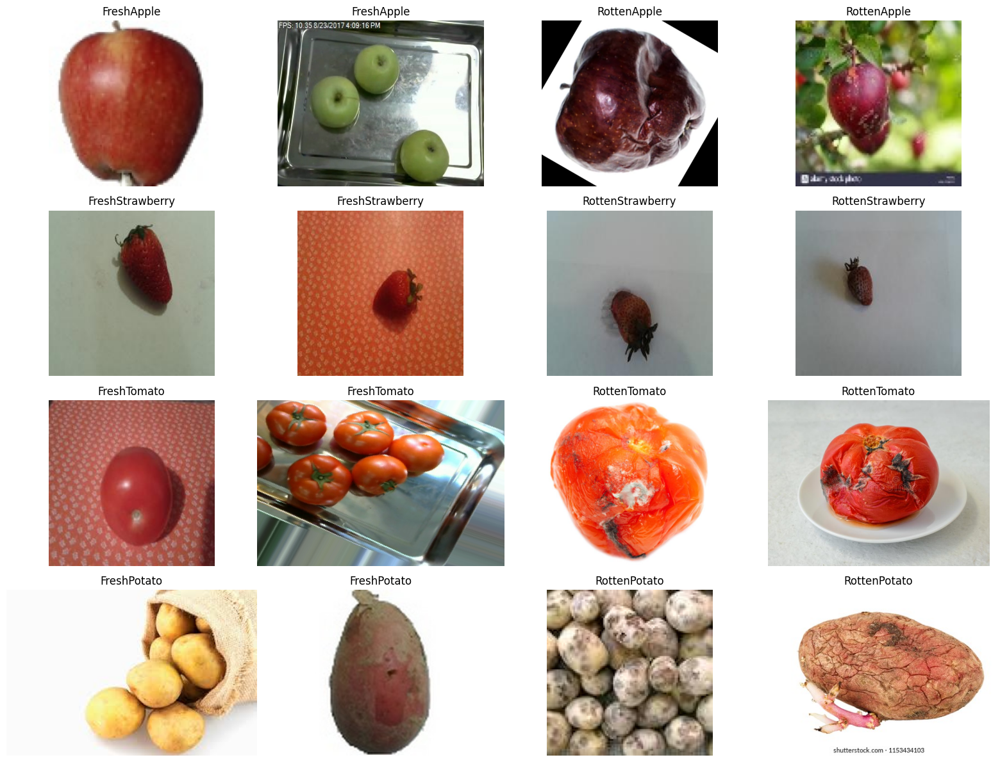

In [11]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = "/content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)"

# Choose representative classes across fruits and vegetables
sample_classes = [
    ("Fruits", "FreshApple"),
    ("Fruits", "RottenApple"),
    ("Fruits", "FreshStrawberry"),
    ("Fruits", "RottenStrawberry"),
    ("Vegetables", "FreshTomato"),
    ("Vegetables", "RottenTomato"),
    ("Vegetables", "FreshPotato"),
    ("Vegetables", "RottenPotato"),
]

plt.figure(figsize=(16, 12))

plot_number = 1

for category, class_name in sample_classes:

    class_path = os.path.join(
        dataset_path,
        category,
        class_name
    )

    image_files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png", ".webp", ".mpo")
        )
    ]

    # Select two random images from each class
    selected_images = random.sample(image_files, 2)

    for image_file in selected_images:

        image_path = os.path.join(class_path, image_file)

        try:
            image = Image.open(image_path).convert("RGB")

            plt.subplot(4, 4, plot_number)
            plt.imshow(image)
            plt.title(class_name)
            plt.axis("off")

            plot_number += 1

        except Exception as e:
            print("Could not display:", image_path)
            print(e)

plt.tight_layout()
plt.show()

In [12]:
import os
import hashlib
from collections import defaultdict

dataset_path = "/content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)"

valid_extensions = (".jpg", ".jpeg", ".png", ".webp", ".mpo")

hash_groups = defaultdict(list)

for root, dirs, files in os.walk(dataset_path):
    for file in files:

        if file.lower().endswith(valid_extensions):
            file_path = os.path.join(root, file)

            try:
                with open(file_path, "rb") as f:
                    file_hash = hashlib.md5(f.read()).hexdigest()

                hash_groups[file_hash].append(file_path)

            except Exception as e:
                print("Could not hash:", file_path)
                print(e)

duplicate_groups = {
    image_hash: paths
    for image_hash, paths in hash_groups.items()
    if len(paths) > 1
}

duplicate_files = sum(
    len(paths) - 1
    for paths in duplicate_groups.values()
)

print("DUPLICATE IMAGE CHECK")
print("=" * 50)
print("Total images checked:", sum(len(v) for v in hash_groups.values()))
print("Unique file hashes:", len(hash_groups))
print("Duplicate groups:", len(duplicate_groups))
print("Extra duplicate files:", duplicate_files)

if duplicate_groups:
    print("\nExample duplicate groups:")

    for i, paths in enumerate(list(duplicate_groups.values())[:10], start=1):
        print(f"\nGroup {i}:")
        for path in paths:
            print(" ", path)
else:
    print("\nNo exact duplicate images detected.")

DUPLICATE IMAGE CHECK
Total images checked: 12000
Unique file hashes: 11768
Duplicate groups: 224
Extra duplicate files: 232

Example duplicate groups:

Group 1:
  /content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)/Vegetables/RottenBellpepper/rottenPepper (186).jpg
  /content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)/Vegetables/RottenBellpepper/rottenPepper (113).jpg

Group 2:
  /content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)/Vegetables/RottenBellpepper/rottenPepper (154).jpg
  /content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)/Vegetables/RottenBellpepper/rottenPepper (429).jpg

Group 3:
  /content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)/Vegetables/RottenBellpepper/rottenPepper (643).jpg
  /content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)/Vegetables/RottenBellpepper/rottenPepper (159).jpg
  /content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)/Vegetables/RottenBellpepper/rottenPepper (236).jpg

In [13]:
import os
import hashlib
from collections import defaultdict

dataset_path = "/content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)"

valid_extensions = (".jpg", ".jpeg", ".png", ".webp", ".mpo")

hash_groups = defaultdict(list)

# Build duplicate groups again
for root, dirs, files in os.walk(dataset_path):
    for file in files:

        if file.lower().endswith(valid_extensions):
            file_path = os.path.join(root, file)

            with open(file_path, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()

            hash_groups[file_hash].append(file_path)


duplicate_groups = {
    image_hash: paths
    for image_hash, paths in hash_groups.items()
    if len(paths) > 1
}


same_class_duplicates = []
cross_class_duplicates = []

for image_hash, paths in duplicate_groups.items():

    classes = set()

    for path in paths:
        relative_path = os.path.relpath(path, dataset_path)

        parts = relative_path.split(os.sep)

        # Example:
        # Fruits/FreshApple/image.jpg
        # -> Fruits/FreshApple
        class_label = f"{parts[0]}/{parts[1]}"

        classes.add(class_label)

    if len(classes) == 1:
        same_class_duplicates.append((image_hash, paths))
    else:
        cross_class_duplicates.append(
            (image_hash, paths, classes)
        )


print("DUPLICATE LABEL ANALYSIS")
print("=" * 55)

print("Total duplicate groups:", len(duplicate_groups))
print("Same-class duplicate groups:", len(same_class_duplicates))
print("Cross-class duplicate groups:", len(cross_class_duplicates))


if cross_class_duplicates:

    print("\nWARNING: Cross-class duplicates detected!")

    for i, (image_hash, paths, classes) in enumerate(
        cross_class_duplicates[:20],
        start=1
    ):

        print(f"\nGroup {i}")
        print("Classes:", classes)

        for path in paths:
            print(" ", path)

else:
    print("\nNo duplicate images occur across different class labels.")

DUPLICATE LABEL ANALYSIS
Total duplicate groups: 224
Same-class duplicate groups: 222
Cross-class duplicate groups: 2


Group 1
Classes: {'Vegetables/RottenCarrot', 'Vegetables/FreshCarrot'}
  /content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)/Vegetables/RottenCarrot/rottenCarrot (549).jpg
  /content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)/Vegetables/RottenCarrot/rottenCarrot (31).jpg
  /content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)/Vegetables/FreshCarrot/freshCarrot (534).jpg

Group 2
Classes: {'Vegetables/RottenCarrot', 'Vegetables/FreshCarrot'}
  /content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)/Vegetables/RottenCarrot/rottenCarrot (527).jpg
  /content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)/Vegetables/FreshCarrot/freshCarrot (536).jpg


In [14]:
import os
import shutil
import hashlib
from collections import defaultdict

source_path = "/content/food_spoilage_dataset/Fruits_Vegetables_Dataset(12000)"
clean_path = "/content/clean_food_spoilage_dataset"

valid_extensions = (".jpg", ".jpeg", ".png", ".webp", ".mpo")

# Start clean
if os.path.exists(clean_path):
    shutil.rmtree(clean_path)

os.makedirs(clean_path)

# Group files by exact file hash
hash_groups = defaultdict(list)

for root, dirs, files in os.walk(source_path):
    for file in files:
        if file.lower().endswith(valid_extensions):

            file_path = os.path.join(root, file)

            with open(file_path, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()

            hash_groups[file_hash].append(file_path)


kept_images = 0
same_class_duplicates_removed = 0
conflicting_images_removed = 0
conflicting_groups_removed = 0


for image_hash, paths in hash_groups.items():

    labels = set()

    for path in paths:
        relative_path = os.path.relpath(path, source_path)
        parts = relative_path.split(os.sep)

        label = f"{parts[0]}/{parts[1]}"
        labels.add(label)

    # Conflicting labels:
    # exclude the entire duplicate group
    if len(labels) > 1:
        conflicting_groups_removed += 1
        conflicting_images_removed += len(paths)
        continue

    # Same label:
    # keep only ONE copy
    source_file = paths[0]
    relative_path = os.path.relpath(source_file, source_path)
    destination_file = os.path.join(clean_path, relative_path)

    os.makedirs(os.path.dirname(destination_file), exist_ok=True)

    shutil.copy2(source_file, destination_file)

    kept_images += 1
    same_class_duplicates_removed += len(paths) - 1


print("CLEAN DATASET CREATED")
print("=" * 55)

print("Original images:", sum(len(paths) for paths in hash_groups.values()))
print("Unique hashes:", len(hash_groups))

print("\nSame-class duplicate copies removed:",
      same_class_duplicates_removed)

print("Conflicting duplicate groups removed:",
      conflicting_groups_removed)

print("Images removed from conflicting groups:",
      conflicting_images_removed)

print("\nFinal cleaned dataset images:", kept_images)

print("\nClean dataset location:")
print(clean_path)

CLEAN DATASET CREATED
Original images: 12000
Unique hashes: 11768

Same-class duplicate copies removed: 229
Conflicting duplicate groups removed: 2
Images removed from conflicting groups: 5

Final cleaned dataset images: 11766

Clean dataset location:
/content/clean_food_spoilage_dataset


In [15]:
import os

clean_path = "/content/clean_food_spoilage_dataset"

valid_extensions = (".jpg", ".jpeg", ".png", ".webp", ".mpo")

clean_class_counts = {}

for category in sorted(os.listdir(clean_path)):

    category_path = os.path.join(clean_path, category)

    if not os.path.isdir(category_path):
        continue

    for class_name in sorted(os.listdir(category_path)):

        class_path = os.path.join(category_path, class_name)

        if not os.path.isdir(class_path):
            continue

        count = sum(
            1
            for file in os.listdir(class_path)
            if file.lower().endswith(valid_extensions)
        )

        clean_class_counts[f"{category}/{class_name}"] = count


print("CLEAN DATASET CLASS DISTRIBUTION")
print("=" * 60)

for class_name, count in clean_class_counts.items():
    print(f"{class_name:<42} {count}")

print("=" * 60)

counts = list(clean_class_counts.values())

print("Number of classes:", len(clean_class_counts))
print("Total cleaned images:", sum(counts))
print("Smallest class:", min(counts))
print("Largest class:", max(counts))
print("Difference:", max(counts) - min(counts))

CLEAN DATASET CLASS DISTRIBUTION
Fruits/FreshApple                          606
Fruits/FreshBanana                         623
Fruits/FreshMango                          605
Fruits/FreshOrange                         609
Fruits/FreshStrawberry                     603
Fruits/RottenApple                         586
Fruits/RottenBanana                        576
Fruits/RottenMango                         593
Fruits/RottenOrange                        591
Fruits/RottenStrawberry                    596
Vegetables/FreshBellpepper                 600
Vegetables/FreshCarrot                     608
Vegetables/FreshCucumber                   591
Vegetables/FreshPotato                     610
Vegetables/FreshTomato                     602
Vegetables/RottenBellpepper                547
Vegetables/RottenCarrot                    506
Vegetables/RottenCucumber                  576
Vegetables/RottenPotato                    564
Vegetables/RottenTomato                    574
Number of classes: 20
Total

In [16]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

clean_path = "/content/clean_food_spoilage_dataset"

valid_extensions = (".jpg", ".jpeg", ".png", ".webp", ".mpo")

# Build a dataframe containing every image and its class
records = []

for category in sorted(os.listdir(clean_path)):

    category_path = os.path.join(clean_path, category)

    if not os.path.isdir(category_path):
        continue

    for class_name in sorted(os.listdir(category_path)):

        class_path = os.path.join(category_path, class_name)

        if not os.path.isdir(class_path):
            continue

        # Keep category in the label so classes remain unambiguous
        label = f"{category}/{class_name}"

        for file in os.listdir(class_path):

            if file.lower().endswith(valid_extensions):

                records.append({
                    "filepath": os.path.join(class_path, file),
                    "label": label
                })


df = pd.DataFrame(records)

print("Total cleaned images:", len(df))
print("Number of classes:", df["label"].nunique())


# ------------------------------------------------
# FIRST SPLIT
# 70% training
# 30% temporary set
# ------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)


# ------------------------------------------------
# SECOND SPLIT
# Divide remaining 30% equally:
# 15% validation
# 15% testing
# ------------------------------------------------

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)


print("\nDATASET SPLIT")
print("=" * 50)

print(f"Training images:   {len(train_df)} ({len(train_df)/len(df)*100:.2f}%)")
print(f"Validation images: {len(val_df)} ({len(val_df)/len(df)*100:.2f}%)")
print(f"Test images:       {len(test_df)} ({len(test_df)/len(df)*100:.2f}%)")

print("\nTotal:", len(train_df) + len(val_df) + len(test_df))


print("\nCLASS COVERAGE")
print("=" * 50)

print("Classes in training:", train_df["label"].nunique())
print("Classes in validation:", val_df["label"].nunique())
print("Classes in test:", test_df["label"].nunique())


# Check for accidental overlap
train_paths = set(train_df["filepath"])
val_paths = set(val_df["filepath"])
test_paths = set(test_df["filepath"])

print("\nOVERLAP CHECK")
print("=" * 50)

print("Train ↔ Validation:", len(train_paths.intersection(val_paths)))
print("Train ↔ Test:", len(train_paths.intersection(test_paths)))
print("Validation ↔ Test:", len(val_paths.intersection(test_paths)))

Total cleaned images: 11766
Number of classes: 20

DATASET SPLIT
Training images:   8236 (70.00%)
Validation images: 1765 (15.00%)
Test images:       1765 (15.00%)

Total: 11766

CLASS COVERAGE
Classes in training: 20
Classes in validation: 20
Classes in test: 20

OVERLAP CHECK
Train ↔ Validation: 0
Train ↔ Test: 0
Validation ↔ Test: 0


## Dataset Preparation Checkpoint

The initial dataset preparation and validation stage has been completed.

### Original Dataset
- Total images: 12,000
- Produce types: 10
- Classes: 20 (Fresh and Rotten for each produce type)
- Corrupt/unreadable images: 0
- Image dimensions identified: 1,578 different dimensions
- Original class range: 576–624 images per class

### Dataset Quality Findings
Visual inspection showed clear differences between many Fresh and Rotten samples, including changes in colour, texture, bruising, mould and visible deterioration.

Some differences in image backgrounds and photography styles were also observed. These may introduce dataset bias and will therefore be considered when evaluating model performance.

### Duplicate Analysis
Exact duplicate detection identified:
- 224 duplicate groups
- 232 additional duplicate files
- 222 same-class duplicate groups
- 2 cross-class conflicting duplicate groups

Same-class duplicates were reduced to one copy.

The 2 conflicting duplicate groups contained identical carrot images labelled as both Fresh and Rotten. All 5 images belonging to these conflicting groups were excluded rather than assigning an uncertain label.

### Cleaned Dataset
- Final images: 11,766
- Classes retained: 20
- Smallest class: 506 images
- Largest class: 623 images

The original dataset remains unchanged. All cleaning was performed on a separate working copy.

### Train / Validation / Test Split

A stratified 70/15/15 split was performed using `random_state=42` for reproducibility.

- Training: 8,236 images (70%)
- Validation: 1,765 images (15%)
- Testing: 1,765 images (15%)

All 20 classes are represented in each subset.

### Leakage Check

No filepath overlap was detected between:

- Training and Validation: 0
- Training and Test: 0
- Validation and Test: 0

The test set will remain untouched during model development and will only be used for final model evaluation.

### Next Stage

Image preprocessing and training-only data augmentation, followed by implementation of the custom CNN model.

In [17]:
import os

print("COLAB STATE CHECK")
print("=" * 50)

print(
    "Clean dataset available:",
    os.path.exists("/content/clean_food_spoilage_dataset")
)

print(
    "train_df available:",
    "train_df" in globals()
)

print(
    "val_df available:",
    "val_df" in globals()
)

print(
    "test_df available:",
    "test_df" in globals()
)

if "train_df" in globals():
    print("\nTraining images:", len(train_df))

if "val_df" in globals():
    print("Validation images:", len(val_df))

if "test_df" in globals():
    print("Test images:", len(test_df))

COLAB STATE CHECK
Clean dataset available: True
train_df available: True
val_df available: True
test_df available: True

Training images: 8236
Validation images: 1765
Test images: 1765


In [18]:
import tensorflow as tf

# CNN input configuration
IMG_HEIGHT = 224
IMG_WIDTH = 224
CHANNELS = 3
BATCH_SIZE = 32

IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)

print("CNN INPUT CONFIGURATION")
print("=" * 50)
print(f"Image size: {IMG_HEIGHT} x {IMG_WIDTH}")
print(f"Channels: {CHANNELS} (RGB)")
print(f"Input shape: ({IMG_HEIGHT}, {IMG_WIDTH}, {CHANNELS})")
print(f"Batch size: {BATCH_SIZE}")
print(f"TensorFlow version: {tf.__version__}")

CNN INPUT CONFIGURATION
Image size: 224 x 224
Channels: 3 (RGB)
Input shape: (224, 224, 3)
Batch size: 32
TensorFlow version: 2.21.0


In [19]:
def preprocess_image(filepath, label):
    # Read image file
    image = tf.io.read_file(filepath)

    # Decode image and force RGB output
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Set shape so TensorFlow knows it is an RGB image
    image.set_shape([None, None, 3])

    # Resize to CNN input size
    image = tf.image.resize(
        image,
        [IMG_HEIGHT, IMG_WIDTH]
    )

    # Convert to float32 and normalize pixel values to 0-1
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


print("Preprocessing function created successfully.")

Preprocessing function created successfully.


In [20]:
# Get all class names in a consistent alphabetical order
class_names = sorted(df["label"].unique())

# Create mappings
class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

index_to_class = {
    index: class_name
    for class_name, index in class_to_index.items()
}

print("CLASS LABEL MAPPING")
print("=" * 60)

for class_name, index in class_to_index.items():
    print(f"{index:2d} -> {class_name}")

print("=" * 60)
print("Total classes:", len(class_names))

CLASS LABEL MAPPING
 0 -> Fruits/FreshApple
 1 -> Fruits/FreshBanana
 2 -> Fruits/FreshMango
 3 -> Fruits/FreshOrange
 4 -> Fruits/FreshStrawberry
 5 -> Fruits/RottenApple
 6 -> Fruits/RottenBanana
 7 -> Fruits/RottenMango
 8 -> Fruits/RottenOrange
 9 -> Fruits/RottenStrawberry
10 -> Vegetables/FreshBellpepper
11 -> Vegetables/FreshCarrot
12 -> Vegetables/FreshCucumber
13 -> Vegetables/FreshPotato
14 -> Vegetables/FreshTomato
15 -> Vegetables/RottenBellpepper
16 -> Vegetables/RottenCarrot
17 -> Vegetables/RottenCucumber
18 -> Vegetables/RottenPotato
19 -> Vegetables/RottenTomato
Total classes: 20


In [21]:
# Add numerical class IDs to each dataset split

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["class_id"] = train_df["label"].map(class_to_index)
val_df["class_id"] = val_df["label"].map(class_to_index)
test_df["class_id"] = test_df["label"].map(class_to_index)

print("NUMERICAL LABEL CHECK")
print("=" * 50)

print("Training labels missing:",
      train_df["class_id"].isna().sum())

print("Validation labels missing:",
      val_df["class_id"].isna().sum())

print("Test labels missing:",
      test_df["class_id"].isna().sum())

print("\nExample training records:")
print(
    train_df[
        ["label", "class_id"]
    ].head(10).to_string(index=False)
)

NUMERICAL LABEL CHECK
Training labels missing: 0
Validation labels missing: 0
Test labels missing: 0

Example training records:
                    label  class_id
        Fruits/FreshApple         0
   Vegetables/FreshPotato        13
        Fruits/FreshApple         0
  Vegetables/RottenCarrot        16
   Vegetables/FreshTomato        14
  Fruits/RottenStrawberry         9
  Vegetables/RottenPotato        18
Vegetables/RottenCucumber        17
   Vegetables/FreshCarrot        11
  Vegetables/RottenCarrot        16


In [22]:
# Create TensorFlow datasets from the DataFrames

train_ds = tf.data.Dataset.from_tensor_slices((
    train_df["filepath"].values,
    train_df["class_id"].values
))

val_ds = tf.data.Dataset.from_tensor_slices((
    val_df["filepath"].values,
    val_df["class_id"].values
))

test_ds = tf.data.Dataset.from_tensor_slices((
    test_df["filepath"].values,
    test_df["class_id"].values
))

# Apply preprocessing
train_ds = train_ds.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

# Batch the datasets
train_ds = train_ds.batch(BATCH_SIZE)
val_ds = val_ds.batch(BATCH_SIZE)
test_ds = test_ds.batch(BATCH_SIZE)

# Prefetch batches for better training performance
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("TensorFlow datasets created successfully.")
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

TensorFlow datasets created successfully.
Training batches: 258
Validation batches: 56
Test batches: 56


In [23]:
# Load one real batch from the training dataset
for image_batch, label_batch in train_ds.take(1):
    print("BATCH VERIFICATION")
    print("=" * 50)

    print("Image batch shape:", image_batch.shape)
    print("Label batch shape:", label_batch.shape)

    print("\nImage data type:", image_batch.dtype)
    print("Label data type:", label_batch.dtype)

    print("\nMinimum pixel value:", tf.reduce_min(image_batch).numpy())
    print("Maximum pixel value:", tf.reduce_max(image_batch).numpy())

    print("\nFirst 10 class IDs:")
    print(label_batch[:10].numpy())

    print("\nCorresponding class names:")
    for class_id in label_batch[:10].numpy():
        print(f"{class_id:2d} -> {index_to_class[int(class_id)]}")

BATCH VERIFICATION
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)

Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int64'>

Minimum pixel value: 0.0
Maximum pixel value: 1.0

First 10 class IDs:
[ 0 13  0 16 14  9 18 17 11 16]

Corresponding class names:
 0 -> Fruits/FreshApple
13 -> Vegetables/FreshPotato
 0 -> Fruits/FreshApple
16 -> Vegetables/RottenCarrot
14 -> Vegetables/FreshTomato
 9 -> Fruits/RottenStrawberry
18 -> Vegetables/RottenPotato
17 -> Vegetables/RottenCucumber
11 -> Vegetables/FreshCarrot
16 -> Vegetables/RottenCarrot


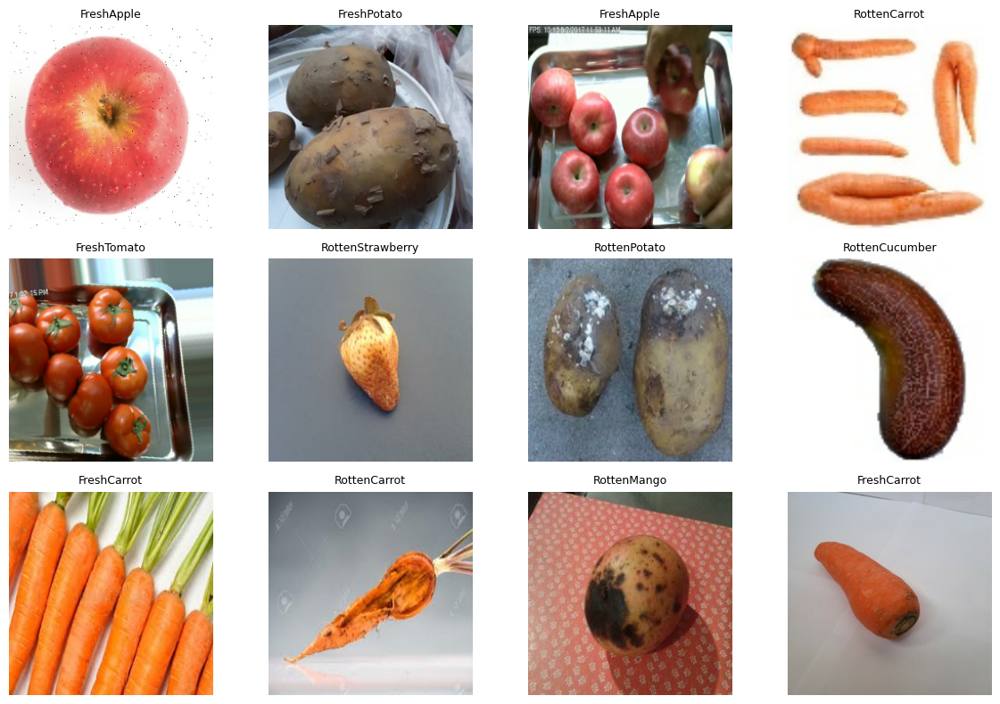

In [24]:
import matplotlib.pyplot as plt

# Take one batch from the training dataset
for image_batch, label_batch in train_ds.take(1):

    plt.figure(figsize=(12, 8))

    for i in range(12):
        plt.subplot(3, 4, i + 1)

        # Images are already normalized between 0 and 1
        plt.imshow(image_batch[i].numpy())

        class_id = int(label_batch[i].numpy())
        class_name = index_to_class[class_id]

        # Make label easier to read
        display_name = class_name.replace("Fruits/", "").replace(
            "Vegetables/", ""
        )

        plt.title(display_name, fontsize=9)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [25]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.10),
        layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05
        ),
        layers.RandomContrast(0.10),
    ],
    name="data_augmentation"
)

print("DATA AUGMENTATION CONFIGURATION")
print("=" * 50)

for layer in data_augmentation.layers:
    print(layer.name, "->", layer.__class__.__name__)

print("\nData augmentation pipeline created successfully.")

DATA AUGMENTATION CONFIGURATION
random_flip -> RandomFlip
random_rotation -> RandomRotation
random_zoom -> RandomZoom
random_translation -> RandomTranslation
random_contrast -> RandomContrast

Data augmentation pipeline created successfully.


In [26]:
import os

print("RESUME CHECK")
print("=" * 50)

print(
    "Clean dataset available:",
    os.path.exists("/content/clean_food_spoilage_dataset")
)

print("train_df available:", "train_df" in globals())
print("val_df available:", "val_df" in globals())
print("test_df available:", "test_df" in globals())

print("train_ds available:", "train_ds" in globals())
print("val_ds available:", "val_ds" in globals())
print("test_ds available:", "test_ds" in globals())

print(
    "augmentation available:",
    "data_augmentation" in globals()
)

RESUME CHECK
Clean dataset available: True
train_df available: True
val_df available: True
test_df available: True
train_ds available: True
val_ds available: True
test_ds available: True
augmentation available: True


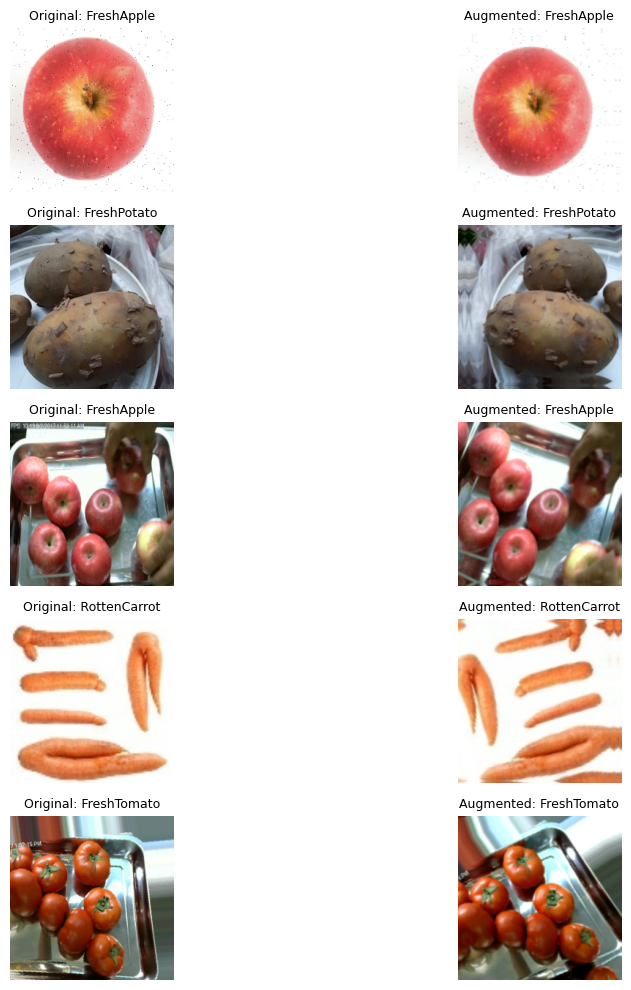

In [27]:
import matplotlib.pyplot as plt

# Take one batch from the training dataset
for image_batch, label_batch in train_ds.take(1):

    # Select the first 5 images
    sample_images = image_batch[:5]
    sample_labels = label_batch[:5]

    # Apply augmentation in training mode
    augmented_images = data_augmentation(
        sample_images,
        training=True
    )

    plt.figure(figsize=(12, 10))

    for i in range(5):
        class_id = int(sample_labels[i].numpy())

        display_name = (
            index_to_class[class_id]
            .replace("Fruits/", "")
            .replace("Vegetables/", "")
        )

        # Original image
        plt.subplot(5, 2, (i * 2) + 1)
        plt.imshow(sample_images[i].numpy())
        plt.title(f"Original: {display_name}", fontsize=9)
        plt.axis("off")

        # Augmented image
        plt.subplot(5, 2, (i * 2) + 2)

        # Clip values for safe visualization
        augmented = tf.clip_by_value(
            augmented_images[i],
            0.0,
            1.0
        )

        plt.imshow(augmented.numpy())
        plt.title(f"Augmented: {display_name}", fontsize=9)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [28]:
# Apply augmentation ONLY to the training dataset

train_augmented_ds = train_ds.map(
    lambda images, labels: (
        data_augmentation(images, training=True),
        labels
    ),
    num_parallel_calls=tf.data.AUTOTUNE
)

train_augmented_ds = train_augmented_ds.prefetch(
    tf.data.AUTOTUNE
)

print("TRAINING-ONLY AUGMENTATION CHECK")
print("=" * 55)

print("Training dataset:")
print("  Augmentation: ENABLED")

print("\nValidation dataset:")
print("  Augmentation: DISABLED")

print("\nTest dataset:")
print("  Augmentation: DISABLED")

print("\nTraining batches:",
      tf.data.experimental.cardinality(train_augmented_ds).numpy())

print("Validation batches:",
      tf.data.experimental.cardinality(val_ds).numpy())

print("Test batches:",
      tf.data.experimental.cardinality(test_ds).numpy())

TRAINING-ONLY AUGMENTATION CHECK
Training dataset:
  Augmentation: ENABLED

Validation dataset:
  Augmentation: DISABLED

Test dataset:
  Augmentation: DISABLED

Training batches: 258
Validation batches: 56
Test batches: 56


In [29]:
print("FINAL PREPROCESSING VERIFICATION")
print("=" * 60)

# Get one batch from each dataset
train_images, train_labels = next(iter(train_augmented_ds))
val_images, val_labels = next(iter(val_ds))
test_images, test_labels = next(iter(test_ds))

print("\nTRAINING")
print("Image shape:", train_images.shape)
print("Label shape:", train_labels.shape)
print(
    "Pixel range:",
    float(tf.reduce_min(train_images)),
    "to",
    float(tf.reduce_max(train_images))
)

print("\nVALIDATION")
print("Image shape:", val_images.shape)
print("Label shape:", val_labels.shape)
print(
    "Pixel range:",
    float(tf.reduce_min(val_images)),
    "to",
    float(tf.reduce_max(val_images))
)

print("\nTEST")
print("Image shape:", test_images.shape)
print("Label shape:", test_labels.shape)
print(
    "Pixel range:",
    float(tf.reduce_min(test_images)),
    "to",
    float(tf.reduce_max(test_images))
)

print("\nDATASET SUMMARY")
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Number of classes:", len(class_names))

print("\nClasses in training:", train_df["class_id"].nunique())
print("Classes in validation:", val_df["class_id"].nunique())
print("Classes in test:", test_df["class_id"].nunique())

print("\nPreprocessing pipeline verification complete.")

FINAL PREPROCESSING VERIFICATION

TRAINING
Image shape: (32, 224, 224, 3)
Label shape: (32,)
Pixel range: 0.0 to 1.056487798690796

VALIDATION
Image shape: (32, 224, 224, 3)
Label shape: (32,)
Pixel range: 0.0 to 1.0

TEST
Image shape: (32, 224, 224, 3)
Label shape: (32,)
Pixel range: 0.0 to 1.0

DATASET SUMMARY
Training images: 8236
Validation images: 1765
Test images: 1765
Number of classes: 20

Classes in training: 20
Classes in validation: 20
Classes in test: 20

Preprocessing pipeline verification complete.


In [30]:
# Apply augmentation ONLY to training data
# and keep augmented pixel values within [0, 1]

def augment_training_batch(images, labels):
    images = data_augmentation(images, training=True)

    # Keep augmented pixels within the normalized range
    images = tf.clip_by_value(images, 0.0, 1.0)

    return images, labels


train_augmented_ds = train_ds.map(
    augment_training_batch,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_augmented_ds = train_augmented_ds.prefetch(
    tf.data.AUTOTUNE
)

print("Training augmentation pipeline updated successfully.")

Training augmentation pipeline updated successfully.


In [31]:
# Verify corrected augmented training batch

train_images, train_labels = next(iter(train_augmented_ds))

print("AUGMENTATION FIX VERIFICATION")
print("=" * 55)

print("Image shape:", train_images.shape)
print("Label shape:", train_labels.shape)

print(
    "Minimum pixel value:",
    float(tf.reduce_min(train_images))
)

print(
    "Maximum pixel value:",
    float(tf.reduce_max(train_images))
)

print("\nExpected pixel range: 0.0 to 1.0")

if (
    tf.reduce_min(train_images) >= 0.0
    and tf.reduce_max(train_images) <= 1.0
):
    print("RESULT: PASS - augmented pixels are within [0, 1].")
else:
    print("RESULT: FAIL - pixel values are outside [0, 1].")

AUGMENTATION FIX VERIFICATION
Image shape: (32, 224, 224, 3)
Label shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0

Expected pixel range: 0.0 to 1.0
RESULT: PASS - augmented pixels are within [0, 1].


## Custom CNN Model Architecture

A lightweight Convolutional Neural Network is developed from scratch
to classify fruit and vegetable images into 20 produce-condition classes.

The architecture consists of three convolutional blocks, global average
pooling, a dense classification layer, dropout regularization, and a
20-class softmax output layer.

In [32]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Build a custom CNN from scratch
cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Convolutional Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Feature aggregation
    layers.GlobalAveragePooling2D(),

    # Classification layers
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    # Output: 20 produce-condition classes
    layers.Dense(20, activation="softmax")
], name="FoodSpoilageCustomCNN")

# Display architecture
cnn_model.summary()

Model: "FoodSpoilageCustomCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,340 (438.83 KB)

 Trainable params: 112,340 (438.83 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
# STEP 36: Compile the custom CNN model

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CUSTOM CNN COMPILATION")
print("=" * 55)

print("Model:", cnn_model.name)
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Loss: Sparse Categorical Crossentropy")
print("Metric: Accuracy")
print("Number of output classes:", cnn_model.output_shape[-1])

print("\nCNN model compiled successfully.")

CUSTOM CNN COMPILATION
Model: FoodSpoilageCustomCNN
Optimizer: Adam
Learning rate: 0.001
Loss: Sparse Categorical Crossentropy
Metric: Accuracy
Number of output classes: 20

CNN model compiled successfully.


In [34]:
import os
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Directory for trained model checkpoints
checkpoint_dir = "/content/cnn_checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

best_model_path = os.path.join(
    checkpoint_dir,
    "best_food_spoilage_cnn.keras"
)

# Configure callbacks
training_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=best_model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001,
        verbose=1
    )
]

print("CNN TRAINING CALLBACKS")
print("=" * 55)

for callback in training_callbacks:
    print(callback.__class__.__name__)

print("\nBest model path:", best_model_path)
print("Training callbacks configured successfully.")

CNN TRAINING CALLBACKS
EarlyStopping
ModelCheckpoint
ReduceLROnPlateau

Best model path: /content/cnn_checkpoints/best_food_spoilage_cnn.keras
Training callbacks configured successfully.


In [35]:
import os
from tensorflow.keras.callbacks import ModelCheckpoint

# Confirm Google Drive is mounted
drive_folder = "/content/drive/MyDrive/Food_Spoilage_Models"

# Create model storage directory
os.makedirs(drive_folder, exist_ok=True)

# Persistent model checkpoint path
best_model_path = os.path.join(
    drive_folder,
    "best_food_spoilage_cnn.keras"
)

# Update the existing ModelCheckpoint callback
training_callbacks[1] = ModelCheckpoint(
    filepath=best_model_path,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

print("CNN MODEL STORAGE CONFIGURATION")
print("=" * 55)
print("Google Drive folder:", drive_folder)
print("Best model path:", best_model_path)
print("Model checkpoint configured successfully.")

CNN MODEL STORAGE CONFIGURATION
Google Drive folder: /content/drive/MyDrive/Food_Spoilage_Models
Best model path: /content/drive/MyDrive/Food_Spoilage_Models/best_food_spoilage_cnn.keras
Model checkpoint configured successfully.


In [36]:
import os
import shutil

# Permanent storage in Google Drive
backup_folder = "/content/google_drive/MyDrive/Food_Spoilage_Datasets"

backup_path = os.path.join(
    backup_folder,
    "clean_food_spoilage_dataset.zip"
)

print("CLEANED DATASET BACKUP")
print("=" * 55)

if os.path.exists(backup_path):
    print("Backup already exists. Not overwriting.")
else:
    print("Creating compressed backup...")

    created_zip = shutil.make_archive(
        "/content/clean_food_spoilage_dataset",
        "zip",
        root_dir="/content",
        base_dir="clean_food_spoilage_dataset"
    )

    shutil.copy2(created_zip, backup_path)

    print("Backup completed.")

print("\nBackup exists:", os.path.isfile(backup_path))

if os.path.isfile(backup_path):
    print(
        "Backup size (MB):",
        round(os.path.getsize(backup_path) / (1024 ** 2), 2)
    )

    print("Saved to:", backup_path)

CLEANED DATASET BACKUP
Backup already exists. Not overwriting.

Backup exists: True
Backup size (MB): 852.53
Saved to: /content/google_drive/MyDrive/Food_Spoilage_Datasets/clean_food_spoilage_dataset.zip


In [37]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

clean_dir = "/content/clean_food_spoilage_dataset"

# Build a dataframe of cleaned images and their labels
records = []

for root, dirs, files in os.walk(clean_dir):
    for filename in sorted(files):
        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png", ".webp", ".mpo")
        ):
            filepath = os.path.join(root, filename)
            label = os.path.relpath(
                os.path.dirname(filepath), clean_dir
            ).replace("\\", "/")

            records.append({
                "filepath": filepath,
                "label": label
            })

df = pd.DataFrame(records)

# Consistent class ordering
class_names = sorted(df["label"].unique())
class_to_id = {
    name: index for index, name in enumerate(class_names)
}

df["class_id"] = df["label"].map(class_to_id)

# Stratified 70% training split
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["class_id"],
    random_state=42
)

# Split remaining 30% equally
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class_id"],
    random_state=42
)

print("DATASET SPLIT RESULTS")
print("=" * 50)
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Total:", len(df))
print("Classes:", len(class_names))

DATASET SPLIT RESULTS
Training: 8236
Validation: 1765
Testing: 1765
Total: 11766
Classes: 20


In [38]:
import os
import pandas as pd

split_folder = (
    "/content/google_drive/MyDrive/"
    "Food_Spoilage_Datasets/dataset_splits"
)

os.makedirs(split_folder, exist_ok=True)

datasets = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

print("SAVING DATASET SPLITS")
print("=" * 55)

for name, split_df in datasets.items():

    save_df = split_df.copy()

    # Store paths relative to the cleaned dataset directory
    save_df["filepath"] = save_df["filepath"].apply(
        lambda path: os.path.relpath(path, clean_dir)
        .replace("\\", "/")
    )

    csv_path = os.path.join(
        split_folder,
        f"{name}_split.csv"
    )

    save_df.to_csv(csv_path, index=False)

    # Verify the saved CSV
    verified_df = pd.read_csv(csv_path)

    print(
        f"{name}: {len(verified_df)} images "
        f"| Saved: {os.path.isfile(csv_path)}"
    )

print("\nSaved to:", split_folder)

SAVING DATASET SPLITS
train: 8236 images | Saved: True
validation: 1765 images | Saved: True
test: 1765 images | Saved: True

Saved to: /content/google_drive/MyDrive/Food_Spoilage_Datasets/dataset_splits


In [39]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def preprocess_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


def create_dataset(dataframe):
    dataset = tf.data.Dataset.from_tensor_slices(
        (
            dataframe["filepath"].values,
            dataframe["class_id"].values
        )
    )

    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("TENSORFLOW DATASET CHECK")
print("=" * 50)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

for images, labels in train_ds.take(1):
    print("\nImage batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))

TENSORFLOW DATASET CHECK
Training batches: 258
Validation batches: 56
Testing batches: 56

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel range: 0.0 to 1.0


In [40]:
from tensorflow.keras import layers
import tensorflow as tf

# Data augmentation configuration
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),
    layers.RandomContrast(0.10)
], name="data_augmentation")


# Apply augmentation only to training images
def augment_training_batch(images, labels):

    images = data_augmentation(
        images,
        training=True
    )

    images = tf.clip_by_value(
        images,
        0.0,
        1.0
    )

    return images, labels


train_augmented_ds = train_ds.map(
    augment_training_batch,
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)


# Verify augmented dataset
print("DATA AUGMENTATION CHECK")
print("=" * 50)

for images, labels in train_augmented_ds.take(1):

    print("Augmented image shape:", images.shape)
    print("Label shape:", labels.shape)

    print(
        "Pixel range:",
        float(tf.reduce_min(images)),
        "to",
        float(tf.reduce_max(images))
    )

print("Training augmentation restored successfully.")

DATA AUGMENTATION CHECK
Augmented image shape: (32, 224, 224, 3)
Label shape: (32,)
Pixel range: 0.0 to 1.0
Training augmentation restored successfully.


In [41]:
import tensorflow as tf
from tensorflow.keras import layers, models

cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Convolutional Block 1
    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 2
    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Block 3
    layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.3),

    # 20 freshness/spoilage classes
    layers.Dense(
        20,
        activation="softmax"
    )

], name="FoodSpoilageCustomCNN")

# Display model architecture
cnn_model.summary()

print("\nMODEL ARCHITECTURE CHECK")
print("=" * 50)
print("Model name:", cnn_model.name)
print("Output classes:", cnn_model.output_shape[-1])
print("Total parameters:", cnn_model.count_params())

Model: "FoodSpoilageCustomCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 112,340 (438.83 KB)

 Trainable params: 112,340 (438.83 KB)

 Non-trainable params: 0 (0.00 B)


MODEL ARCHITECTURE CHECK
Model name: FoodSpoilageCustomCNN
Output classes: 20
Total parameters: 112340


In [42]:
import tensorflow as tf

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN COMPILATION CHECK")
print("=" * 50)

print("Optimizer:", type(cnn_model.optimizer).__name__)

print(
    "Learning rate:",
    float(cnn_model.optimizer.learning_rate.numpy())
)

print("Loss:", cnn_model.loss)

print("Metrics:", cnn_model.metrics_names)

print("\nCNN model compiled successfully.")

CNN COMPILATION CHECK
Optimizer: Adam
Learning rate: 0.0010000000474974513
Loss: sparse_categorical_crossentropy
Metrics: ['loss', 'compile_metrics']

CNN model compiled successfully.


In [43]:
import os
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Permanent model storage in Google Drive
model_folder = (
    "/content/google_drive/MyDrive/Food_Spoilage_Models"
)

os.makedirs(model_folder, exist_ok=True)

best_model_path = os.path.join(
    model_folder,
    "best_food_spoilage_cnn.keras"
)

training_callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=best_model_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001,
        verbose=1
    )
]

print("CNN TRAINING CALLBACK CHECK")
print("=" * 55)

print("Model folder exists:", os.path.isdir(model_folder))
print("Checkpoint path:", best_model_path)
print("Callbacks configured:", len(training_callbacks))

for callback in training_callbacks:
    print("-", type(callback).__name__)

print("\nTraining callbacks configured successfully.")

CNN TRAINING CALLBACK CHECK
Model folder exists: True
Checkpoint path: /content/google_drive/MyDrive/Food_Spoilage_Models/best_food_spoilage_cnn.keras
Callbacks configured: 3
- EarlyStopping
- ModelCheckpoint
- ReduceLROnPlateau

Training callbacks configured successfully.


In [44]:
import tensorflow as tf
import os

print("CNN TRAINING READINESS CHECK")
print("=" * 55)

required_components = [
    "train_df",
    "val_df",
    "test_df",
    "train_augmented_ds",
    "val_ds",
    "test_ds",
    "cnn_model",
    "training_callbacks",
    "best_model_path"
]

all_ready = True

for component in required_components:
    available = component in globals()
    print(f"{component}: {'READY' if available else 'MISSING'}")

    if not available:
        all_ready = False

print("\nHARDWARE CHECK")
print("=" * 55)

gpus = tf.config.list_physical_devices("GPU")

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(gpus) > 0)
print("GPU devices:", gpus)

print("\nMODEL CHECK")
print("=" * 55)

if "cnn_model" in globals():
    print("Model parameters:", cnn_model.count_params())
    print("Output classes:", cnn_model.output_shape[-1])

print("\nFINAL STATUS")
print("=" * 55)

if all_ready:
    print("ALL COMPONENTS READY FOR TRAINING")
else:
    print("SOME COMPONENTS ARE MISSING — DO NOT START TRAINING")

CNN TRAINING READINESS CHECK
train_df: READY
val_df: READY
test_df: READY
train_augmented_ds: READY
val_ds: READY
test_ds: READY
cnn_model: READY
training_callbacks: READY
best_model_path: READY

HARDWARE CHECK
TensorFlow version: 2.21.0
GPU available: True
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

MODEL CHECK
Model parameters: 112340
Output classes: 20

FINAL STATUS
ALL COMPONENTS READY FOR TRAINING


In [45]:
import time

EPOCHS = 20

print("STARTING CUSTOM CNN TRAINING")
print("=" * 55)

start_time = time.time()

history = cnn_model.fit(
    train_augmented_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=training_callbacks,
    verbose=1
)

training_minutes = (time.time() - start_time) / 60

print("\nCNN TRAINING COMPLETED")
print("=" * 55)
print(f"Epochs completed: {len(history.history['loss'])}")
print(f"Training duration: {training_minutes:.2f} minutes")
print(f"Best validation accuracy: {max(history.history['val_accuracy']):.4f}")
print(f"Lowest validation loss: {min(history.history['val_loss']):.4f}")
print(f"Best model checkpoint: {best_model_path}")

STARTING CUSTOM CNN TRAINING
Epoch 1/20
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 515ms/step - accuracy: 0.0835 - loss: 2.9238
Epoch 1: val_loss improved from None to 2.45419, saving model to /content/google_drive/MyDrive/Food_Spoilage_Models/best_food_spoilage_cnn.keras

Epoch 1: finished saving model to /content/google_drive/MyDrive/Food_Spoilage_Models/best_food_spoilage_cnn.keras
258/258 ━━━━━━━━━━━━━━━━━━━━ 152s 542ms/step - accuracy: 0.1305 - loss: 2.7926 - val_accuracy: 0.2720 - val_loss: 2.4542 - learning_rate: 0.0010
Epoch 2/20
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 605ms/step - accuracy: 0.2529 - loss: 2.4212
Epoch 2: val_loss improved from 2.45419 to 1.91685, saving model to /content/google_drive/MyDrive/Food_Spoilage_Models/best_food_spoilage_cnn.keras

Epoch 2: finished saving model to /content/google_drive/MyDrive/Food_Spoilage_Models/best_food_spoilage_cnn.keras
258/258 ━━━━━━━━━━━━━━━━━━━━ 161s 622ms/step - accuracy: 0.2844 - loss: 2.3028 - val_accuracy: 0.4142 - val_loss: 1.9168 - lear

In [46]:
import os
import tensorflow as tf

print("SAVED CNN MODEL VERIFICATION")
print("=" * 55)

print("Checkpoint exists:", os.path.isfile(best_model_path))

if os.path.isfile(best_model_path):

    saved_model = tf.keras.models.load_model(best_model_path)

    print("Model name:", saved_model.name)
    print("Model parameters:", saved_model.count_params())
    print("Output classes:", saved_model.output_shape[-1])

    print(
        "File size (MB):",
        round(os.path.getsize(best_model_path) / (1024 ** 2), 2)
    )

    print("\nSaved CNN loaded successfully.")
else:
    print("ERROR: Saved model checkpoint not found.")

SAVED CNN MODEL VERIFICATION
Checkpoint exists: True
Model name: FoodSpoilageCustomCNN
Model parameters: 112340
Output classes: 20
File size (MB): 1.33

Saved CNN loaded successfully.


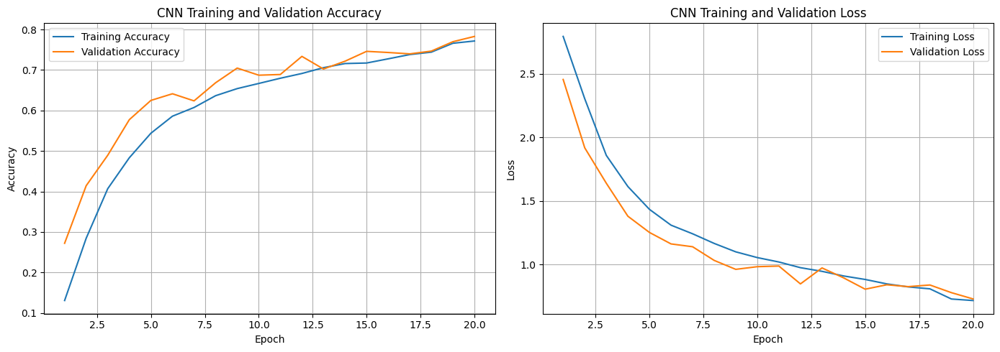

In [47]:
import matplotlib.pyplot as plt

# Retrieve training history
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = range(1, len(train_accuracy) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy graph
axes[0].plot(epochs, train_accuracy, label="Training Accuracy")
axes[0].plot(epochs, val_accuracy, label="Validation Accuracy")

axes[0].set_title("CNN Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss graph
axes[1].plot(epochs, train_loss, label="Training Loss")
axes[1].plot(epochs, val_loss, label="Validation Loss")

axes[1].set_title("CNN Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [48]:
print("CUSTOM CNN TEST EVALUATION")
print("=" * 55)

test_loss, test_accuracy = saved_model.evaluate(
    test_ds,
    verbose=1
)

print("\nFINAL TEST RESULTS")
print("=" * 55)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Images: {len(test_df)}")

CUSTOM CNN TEST EVALUATION
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.7892 - loss: 0.7193

FINAL TEST RESULTS
Test Accuracy: 78.92%
Test Loss: 0.7193
Test Images: 1765


In [49]:
import numpy as np
from sklearn.metrics import classification_report

print("GENERATING CNN CLASSIFICATION REPORT")
print("=" * 55)

# Generate predictions for all test images
predictions = saved_model.predict(
    test_ds,
    verbose=1
)

# Convert probabilities to predicted class IDs
y_pred = np.argmax(predictions, axis=1)

# Actual class IDs, in the same order as test_ds
y_true = test_df["class_id"].to_numpy()

# Generate report
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("\nCNN CLASSIFICATION REPORT")
print("=" * 55)
print(report)

GENERATING CNN CLASSIFICATION REPORT
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 76ms/step

CNN CLASSIFICATION REPORT
                             precision    recall  f1-score   support

          Fruits/FreshApple     0.7565    0.9560    0.8447        91
         Fruits/FreshBanana     0.8462    0.8280    0.8370        93
          Fruits/FreshMango     0.9770    0.9341    0.9551        91
         Fruits/FreshOrange     0.9882    0.9231    0.9545        91
     Fruits/FreshStrawberry     0.8485    0.9231    0.8842        91
         Fruits/RottenApple     0.6932    0.6932    0.6932        88
        Fruits/RottenBanana     0.8046    0.8046    0.8046        87
         Fruits/RottenMango     0.8333    0.7303    0.7784        89
        Fruits/RottenOrange     0.9143    0.7273    0.8101        88
    Fruits/RottenStrawberry     0.7755    0.8444    0.8085        90
 Vegetables/FreshBellpepper     0.8462    0.8556    0.8508        90
     Vegetables/FreshCarrot     0.8421    0.8791    0.8602        9

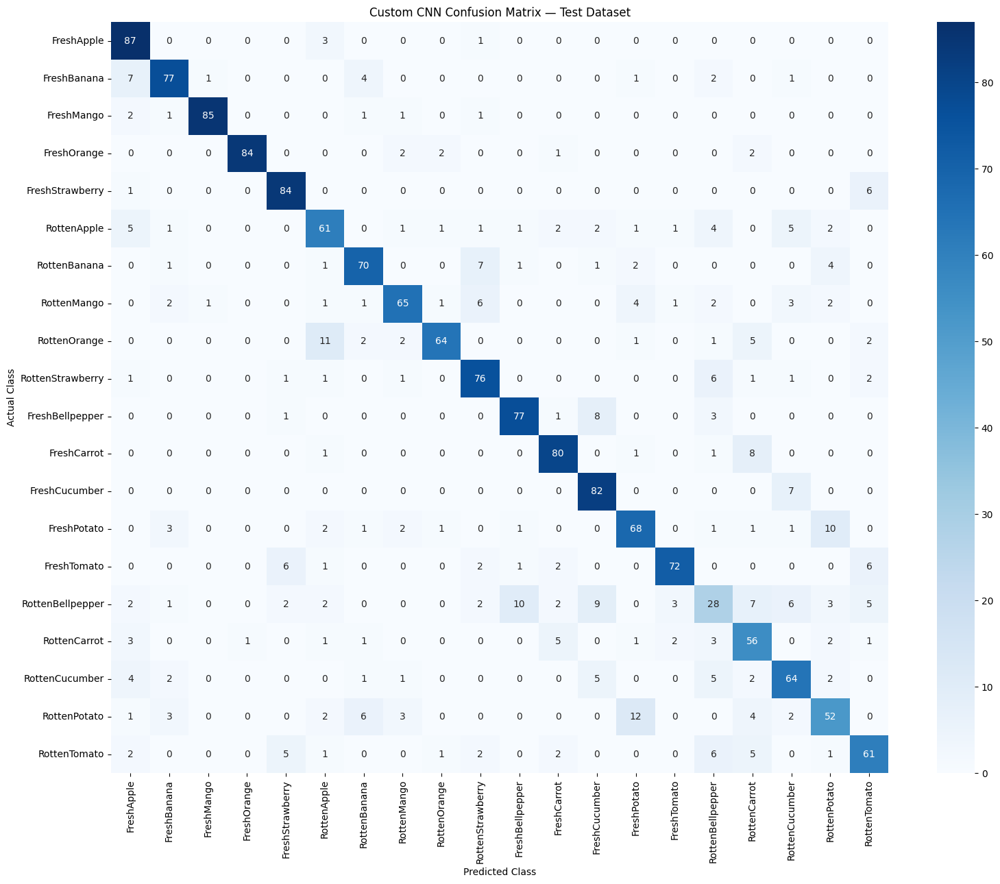

CONFUSION MATRIX CHECK
Total test predictions: 1765
Correct predictions: 1393
Incorrect predictions: 372


In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Generate confusion matrix using Step 21 predictions
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

# Shorten labels for readability
short_labels = [
    name.split("/")[-1]
    for name in class_names
]

plt.figure(figsize=(16, 13))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=short_labels,
    yticklabels=short_labels
)

plt.title("Custom CNN Confusion Matrix — Test Dataset")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=90)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print("CONFUSION MATRIX CHECK")
print("=" * 55)
print("Total test predictions:", cm.sum())
print("Correct predictions:", np.trace(cm))
print("Incorrect predictions:", cm.sum() - np.trace(cm))

# Custom CNN for Food Spoilage Detection
## Baseline Model Development, Training and Evaluation

**Project:** Smartphone-Based Food Spoilage Detection Using Deep Learning  
**Model:** FoodSpoilageCustomCNN  
**Framework:** TensorFlow / Keras  
**Experiment:** Baseline CNN — Version 1  
**Status:** Training and baseline evaluation completed

---

## 1. Dataset Preparation and Cleaning

The initial dataset consisted of 12,000 images of fruits and vegetables, representing 10 produce types divided into 20 classes based on freshness condition (fresh or rotten).

The produce categories included apples, bananas, mangoes, oranges, strawberries, bell peppers, carrots, cucumbers, potatoes and tomatoes.

To improve dataset quality, exact duplicate detection was performed using image hashing. Duplicate images were removed, and images associated with conflicting class labels were excluded to reduce inconsistencies during training.

The cleaning process produced the following results:

| Dataset Cleaning Metric | Result |
|---|---:|
| Original images | 12,000 |
| Unique image hashes | 11,768 |
| Conflicting-label groups | 2 |
| Images excluded due to conflicting labels | 5 |
| Final cleaned images | **11,766** |

The cleaned dataset was stored in Google Drive as a compressed ZIP file to support future model training and reproducibility.

### 1.1 Dataset Splitting

The cleaned dataset was divided into training, validation and testing subsets using stratified sampling with a fixed random state of 42.

| Dataset | Number of Images | Approximate Proportion |
|---|---:|---:|
| Training | 8,236 | 70% |
| Validation | 1,765 | 15% |
| Testing | 1,765 | 15% |
| **Total** | **11,766** | **100%** |

Stratified splitting was used to maintain the distribution of the 20 classes across the three subsets.

The split assignments were saved as CSV files in Google Drive to support consistent dataset reuse in subsequent experiments.

## 2. Image Preprocessing

All images were preprocessed to ensure consistent input dimensions and pixel representations for the CNN.

The preprocessing operations included:

- Resizing images to 224 × 224 pixels.
- Converting images to RGB format with three colour channels.
- Converting pixel values to 32-bit floating-point format.
- Normalizing pixel intensities to the range 0–1.
- Organizing images into batches of 32 using TensorFlow's `tf.data` pipeline.

The preprocessing pipeline generated 258 training batches, 56 validation batches and 56 testing batches.

## 3. Data Augmentation

Data augmentation was applied exclusively to the training dataset to introduce controlled image variations and improve the model's ability to learn from diverse visual conditions.

The augmentation techniques included:

| Technique | Configuration |
|---|---|
| Horizontal flipping | Random horizontal flip |
| Rotation | 0.08 rotation factor |
| Zoom | 0.10 zoom factor |
| Translation | 0.05 horizontal and vertical factors |
| Contrast adjustment | 0.10 contrast factor |

Augmented pixel values were clipped to the range 0–1 to maintain consistency with the normalized input images.

Validation and testing images were not augmented, ensuring that evaluation was performed on unmodified images from the respective datasets.

## 4. Custom CNN Architecture

A convolutional neural network was developed from scratch using TensorFlow and Keras without pretrained weights or transfer learning.

The architecture consisted of three convolutional blocks followed by classification layers.

| Layer | Configuration | Output Shape |
|---|---|---|
| Input | RGB image | 224 × 224 × 3 |
| Conv2D 1 | 32 filters, 3 × 3, ReLU | 224 × 224 × 32 |
| MaxPooling2D 1 | 2 × 2 | 112 × 112 × 32 |
| Conv2D 2 | 64 filters, 3 × 3, ReLU | 112 × 112 × 64 |
| MaxPooling2D 2 | 2 × 2 | 56 × 56 × 64 |
| Conv2D 3 | 128 filters, 3 × 3, ReLU | 56 × 56 × 128 |
| MaxPooling2D 3 | 2 × 2 | 28 × 28 × 128 |
| Global Average Pooling | Feature aggregation | 128 |
| Dense | 128 neurons, ReLU | 128 |
| Dropout | Rate of 0.3 | 128 |
| Output Dense | 20 neurons, Softmax | 20 |

The CNN contained **112,340 trainable parameters**, with no non-trainable parameters.

The convolutional layers were designed to learn visual features such as colour variations, texture patterns and surface characteristics that may be associated with freshness or visible spoilage.

Global average pooling was used to reduce the number of parameters compared with flattening the complete feature maps.

The softmax output layer generated predictions across the 20 produce-condition categories.

## 5. Model Compilation and Training

The CNN was compiled using the following configuration:

| Parameter | Configuration |
|---|---|
| Optimizer | Adam |
| Initial learning rate | 0.001 |
| Loss function | Sparse categorical cross-entropy |
| Evaluation metric | Classification accuracy |
| Batch size | 32 |
| Maximum epochs | 20 |
| Training images | 8,236 |
| Validation images | 1,765 |

Three training callbacks were configured:

**EarlyStopping:** Monitored validation loss with a patience of five epochs and restored the best-performing weights.

**ModelCheckpoint:** Saved the model whenever validation loss improved.

**ReduceLROnPlateau:** Reduced the learning rate by a factor of 0.5 when validation loss failed to improve for three consecutive epochs, subject to a minimum learning rate of 0.00001.

The CNN completed all 20 epochs in approximately 45.38 minutes using GPU acceleration in Google Colab.

At Epoch 17, the learning rate was reduced from 0.001 to 0.0005. Subsequent epochs recorded further improvements in validation performance.

The best model checkpoint was saved in Keras format in Google Drive.

## 6. Training and Validation Results

The CNN demonstrated progressive improvement throughout training.

| Metric | Epoch 1 | Epoch 20 |
|---|---:|---:|
| Training accuracy | 14.69% | 74.24% |
| Validation accuracy | 25.61% | 76.94% |
| Training loss | 2.7522 | 0.8134 |
| Validation loss | 2.4370 | 0.7620 |

Training accuracy increased as the model learned patterns from the augmented images.

Validation accuracy also improved across the training process, reaching its highest recorded value of 76.94% at Epoch 20.

Both training and validation loss decreased overall, indicating progressive optimization of the CNN.

### 6.1 Learning Curve Interpretation

The training and validation accuracy curves showed an upward trend, while the corresponding loss curves demonstrated a downward trend.

Validation accuracy remained slightly higher than training accuracy during much of the experiment. This may be attributed in part to the use of training-only augmentation and dropout, which increase training difficulty.

The learning curves did not show clear evidence of severe overfitting during the 20-epoch experiment.

However, validation loss was still improving at the final epoch, indicating that further training or model refinement could be investigated.

## 7. Test Dataset Evaluation

The trained CNN was evaluated using 1,765 held-out test images that were not used during training or validation.

The following results were obtained:

| Evaluation Metric | Result |
|---|---:|
| Test accuracy | **75.64%** |
| Test loss | 0.8239 |
| Validation accuracy | 76.94% |
| Difference between validation and test accuracy | 1.30 percentage points |
| Macro precision | 75.52% |
| Macro recall | 75.23% |
| Macro F1-score | 75.12% |
| Weighted precision | 75.92% |
| Weighted recall | 75.64% |
| Weighted F1-score | 75.52% |

The relatively small difference between validation and test accuracy suggests reasonably consistent performance on held-out images from the same dataset.

However, performance on photographs captured under real-world smartphone conditions has not yet been established.

## 8. Class-Level Classification Performance

Precision, recall and F1-score were calculated for each of the 20 classes to evaluate performance beyond overall accuracy.

### 8.1 Best-Performing Classes

| Class | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Fresh Mango | 90.53% | 94.51% | 92.47% |
| Fresh Orange | 96.51% | 91.21% | 93.79% |
| Fresh Strawberry | 88.89% | 87.91% | 88.40% |
| Fresh Apple | 73.04% | 92.31% | 81.55% |
| Fresh Bell Pepper | 88.51% | 85.56% | 87.01% |

These categories demonstrated relatively strong recall, indicating that the model successfully identified a high proportion of their actual test images.

### 8.2 Underperforming Classes

| Class | Precision | Recall | F1-score |
|---|---:|---:|---:|
| Rotten Bell Pepper | 53.45% | 37.80% | 44.29% |
| Rotten Carrot | 54.02% | 61.84% | 57.67% |
| Rotten Apple | 70.51% | 62.50% | 66.27% |
| Rotten Banana | 77.46% | 63.22% | 69.62% |
| Rotten Potato | 54.46% | 64.71% | 59.14% |

Rotten bell peppers recorded the lowest recall at 37.80%, indicating that the CNN failed to correctly identify a substantial proportion of images belonging to this class.

The results also revealed weaknesses in identifying several other rotten produce categories.

These findings suggest that additional dataset diversity and model refinement may be required to improve the recognition of visible spoilage characteristics.

## 9. Confusion Matrix Analysis

A 20-class confusion matrix was generated to examine correct and incorrect predictions across the test dataset.

| Confusion Matrix Metric | Result |
|---|---:|
| Total test predictions | 1,765 |
| Correct predictions | 1,335 |
| Incorrect predictions | 430 |
| Overall accuracy | 75.64% |
| Misclassification rate | 24.36% |

The confusion matrix confirmed that 1,335 images were correctly classified, while 430 images were assigned to incorrect categories.

The classification report highlighted difficulties with several rotten produce categories, particularly rotten bell peppers, carrots, potatoes, apples and bananas.

Further examination of the individual confusion matrix cells is necessary to distinguish errors involving produce identification from errors involving freshness classification.

Of particular importance are cases in which rotten produce is incorrectly predicted as fresh, since such errors may undermine the usefulness of the application as a spoilage-screening tool.

## 10. Baseline Model Limitations

The baseline experiment identified several limitations:

1. **Restricted produce coverage:** The model supports only 10 produce types across 20 fresh and rotten categories.
2. **Uneven class performance:** Several rotten produce categories recorded substantially lower recall than fresh produce categories.
3. **Dataset generalization:** Test results were obtained from the existing image dataset and do not establish performance on photographs captured in markets, households or other real-world environments.
4. **Binary freshness categories:** The model currently distinguishes fresh and rotten produce but does not classify intermediate spoilage stages.
5. **Visual assessment limitations:** Visible appearance alone cannot reliably determine microbial contamination or guarantee that food is safe for consumption.

The baseline model therefore provides an initial automated visual spoilage classification capability rather than a definitive food safety assessment.

## 11. Planned Improvements — Next Development Phase

The next phase will focus on improving classification performance and expanding the model's practical applicability.

### 11.1 Dataset Expansion

Additional images will be considered for underperforming categories, prioritizing rotten bell peppers, carrots, potatoes, apples and bananas.

New produce categories may also be introduced, including avocados, pineapples and cabbages, depending on dataset availability and quality.

Additional smartphone-captured images will be considered to introduce realistic variations in lighting, background, camera angle and image quality.

### 11.2 Dataset Preparation and Validation

New images will undergo quality checks, duplicate detection and label verification.

The expanded dataset will be split using a reproducible procedure that prevents duplicate or near-duplicate images from appearing across training and evaluation subsets.

An independent test set will be reserved for the revised model's final assessment.

### 11.3 Model Improvement and Comparison

The custom CNN will be retrained or refined using the expanded dataset.

Performance will be assessed using accuracy, precision, recall, F1-score and confusion matrix analysis.

The original baseline results will be retained as a reference. Where class definitions or evaluation datasets change, comparisons will be interpreted accordingly rather than treated as directly equivalent.

### 11.4 Mobile Application Integration

After model selection and finalization, the selected CNN will be converted to TensorFlow Lite for mobile inference.

The TensorFlow Lite model will subsequently be integrated into the Flutter application to support smartphone-based image capture and offline freshness/spoilage classification.

The application will present classification results as visual assessments rather than definitive guarantees of food safety.

## 12. Baseline Experiment Conclusion

The baseline experiment demonstrated that a custom CNN developed without pretrained weights can learn visual features associated with fresh and rotten fruits and vegetables.

The model achieved **75.64% test accuracy across 20 classes**, with a macro F1-score of **75.12%**.

Although the results provide an encouraging foundation for the proposed mobile application, the classification report revealed weaknesses in several rotten produce categories.

These findings establish the need for targeted dataset improvement, further model evaluation and testing under realistic smartphone imaging conditions.

The completed baseline model will serve as the reference point for the next development phase.

---

**Experiment status:** Baseline CNN training and evaluation completed.

**Next milestone:** Step 23 — Dataset Expansion and Improvement.

**Version control:** Baseline notebook to be committed to the `feature/cnn-model` GitHub branch before beginning dataset expansion.

In [51]:
!pip -q install kagglehub

import kagglehub
import os

dataset_path = kagglehub.dataset_download("moltean/fruits")

print("Download completed!")
print("Dataset saved at:", dataset_path)

print("\nDataset contents:")
for item in sorted(os.listdir(dataset_path)):
    print(item)

Using Colab cache for faster access to the 'fruits' dataset.
Download completed!
Dataset saved at: /kaggle/input/fruits

Dataset contents:
fruits-360_100x100
fruits-360_3-body-problem
fruits-360_meta
fruits-360_multi
fruits-360_original-size


In [52]:
import os

original_path = "/kaggle/input/fruits/fruits-360_original-size"

print("Original-size dataset structure:")
print("=" * 55)

for item in sorted(os.listdir(original_path)):
    item_path = os.path.join(original_path, item)

    if os.path.isdir(item_path):
        print(f"📁 {item}/")

        subfolders = [
            name for name in os.listdir(item_path)
            if os.path.isdir(os.path.join(item_path, name))
        ]

        print(f"   Number of subfolders: {len(subfolders)}")
        print(f"   First 10: {sorted(subfolders)[:10]}")
    else:
        print(f"📄 {item}")

Original-size dataset structure:
📁 fruits-360-original-size/
   Number of subfolders: 4
   First 10: ['Papers', 'Test', 'Training', 'Validation']


In [53]:
import os

base_path = (
    "/kaggle/input/fruits/fruits-360_original-size/"
    "fruits-360-original-size"
)

# Our 13 target produce types
target_produce = [
    "Apple", "Banana", "Mango", "Orange", "Strawberry",
    "Pepper", "Carrot", "Cucumber", "Potato", "Tomato",
    "Avocado", "Pineapple", "Cabbage"
]

for split in ["Training", "Validation", "Test"]:
    split_path = os.path.join(base_path, split)

    print(f"\n{'=' * 55}")
    print(f"{split.upper()} DATASET")
    print("=" * 55)

    if not os.path.isdir(split_path):
        print("Folder not found")
        continue

    categories = sorted([
        name for name in os.listdir(split_path)
        if os.path.isdir(os.path.join(split_path, name))
    ])

    matched = [
        name for name in categories
        if any(
            name.lower().startswith(produce.lower())
            for produce in target_produce
        )
    ]

    total_images = 0

    for category in matched:
        category_path = os.path.join(split_path, category)

        count = sum(
            1 for file in os.listdir(category_path)
            if file.lower().endswith((".jpg", ".jpeg", ".png"))
        )

        total_images += count
        print(f"{category}: {count} images")

    print("-" * 55)
    print(f"Matched categories: {len(matched)}")
    print(f"Total matched images: {total_images}")


TRAINING DATASET
Apple 10: 465 images
Apple 11: 287 images
Apple 12: 310 images
Apple 13: 465 images
Apple 14: 310 images
Apple 17: 489 images
Apple 18: 486 images
Apple 19: 486 images
Apple 20: 468 images
Apple 21: 319 images
Apple 22: 465 images
Apple 23: 314 images
Apple 5: 294 images
Apple 6: 315 images
Apple 7: 462 images
Apple 8: 458 images
Apple 9: 463 images
Apple Braeburn 1: 320 images
Apple Red Yellow 2: 453 images
Avocado Black 1: 468 images
Avocado Black 2: 492 images
Avocado Green 1: 468 images
Banana 2: 149 images
Banana 3: 154 images
Banana 4: 169 images
Cabbage red 1: 99 images
Carrot 1: 101 images
Cucumber 1: 100 images
Cucumber 10: 480 images
Cucumber 11: 466 images
Cucumber 3: 322 images
Cucumber 4: 152 images
Cucumber 5: 471 images
Cucumber 6: 618 images
Cucumber 7: 473 images
Cucumber 8: 465 images
Cucumber 9: 468 images
Orange 2: 468 images
Orange 3: 477 images
Orange 4: 632 images
Orange 5: 473 images
Orange peeled 1: 320 images
Pepper 1: 458 images
Pepper 2: 32

In [54]:
import os

training_path = os.path.join(base_path, "Training")

categories = sorted(os.listdir(training_path))

keywords = ["mango", "pineapple", "potato"]

for keyword in keywords:
    matches = [
        name for name in categories
        if keyword in name.lower()
    ]

    print(f"\n{keyword.upper()}:")
    print(matches if matches else "No matching folders found")


MANGO:
No matching folders found

PINEAPPLE:
No matching folders found

POTATO:
No matching folders found


In [55]:
import os

fruits100_path = (
    "/kaggle/input/fruits/fruits-360_100x100"
)

print("100x100 branch contents:")
print(os.listdir(fruits100_path))

print("\nSearching for missing produce categories:")

for root, dirs, files in os.walk(fruits100_path):
    for folder in dirs:
        if any(
            keyword in folder.lower()
            for keyword in ["mango", "pineapple", "potato"]
        ):
            print(os.path.join(root, folder))

100x100 branch contents:
['fruits-360']

Searching for missing produce categories:
/kaggle/input/fruits/fruits-360_100x100/fruits-360/Training/Potato Red 1
/kaggle/input/fruits/fruits-360_100x100/fruits-360/Training/Potato Sweet 1
/kaggle/input/fruits/fruits-360_100x100/fruits-360/Training/Potato Red 2
/kaggle/input/fruits/fruits-360_100x100/fruits-360/Training/Mangostan 1
/kaggle/input/fruits/fruits-360_100x100/fruits-360/Training/Pineapple Mini 1
/kaggle/input/fruits/fruits-360_100x100/fruits-360/Training/Potato White 1
/kaggle/input/fruits/fruits-360_100x100/fruits-360/Training/Mango Red 1
/kaggle/input/fruits/fruits-360_100x100/fruits-360/Training/Mango 1
/kaggle/input/fruits/fruits-360_100x100/fruits-360/Training/Pineapple 1
/kaggle/input/fruits/fruits-360_100x100/fruits-360/Test/Potato Red 1
/kaggle/input/fruits/fruits-360_100x100/fruits-360/Test/Potato Sweet 1
/kaggle/input/fruits/fruits-360_100x100/fruits-360/Test/Potato Red 2
/kaggle/input/fruits/fruits-360_100x100/fruits-360/

In [57]:
from pathlib import Path
import pandas as pd

original_root = Path(
    "/kaggle/input/fruits/fruits-360_original-size/"
    "fruits-360-original-size"
)

small_root = Path(
    "/kaggle/input/fruits/fruits-360_100x100/fruits-360"
)

original_targets = {
    "Apple": ["apple"],
    "Banana": ["banana"],
    "Avocado": ["avocado"],
    "Cabbage": ["cabbage"],
    "Carrot": ["carrot"],
    "Cucumber": ["cucumber"],
    "Orange": ["orange"],
    "BellPepper": ["pepper"],
    "Strawberry": ["strawberry"],
    "Tomato": ["tomato"],
}

small_targets = {
    "Mango": ["Mango 1", "Mango Red 1"],
    "Pineapple": ["Pineapple 1", "Pineapple Mini 1"],
    "Potato": ["Potato Red 1", "Potato Red 2", "Potato White 1"],
}

records = []

def collect_images(root, branch, targets, exact=False):
    for split in ["Training", "Validation", "Test"]:
        split_dir = root / split

        if not split_dir.exists():
            continue

        for category_dir in sorted(split_dir.iterdir()):
            if not category_dir.is_dir():
                continue

            category = category_dir.name

            for produce, patterns in targets.items():
                if exact:
                    matched = category in patterns
                else:
                    matched = any(
                        category.lower().startswith(pattern)
                        for pattern in patterns
                    )

                if not matched:
                    continue

                for image_path in category_dir.iterdir():
                    if image_path.suffix.lower() in [
                        ".jpg", ".jpeg", ".png"
                    ]:
                        records.append({
                            "source": "Fruits-360",
                            "branch": branch,
                            "original_split": split,
                            "original_category": category,
                            "produce": produce,
                            "source_path": str(image_path),
                            "filename": image_path.name,
                            "freshness_label": "UNVERIFIED"
                        })

collect_images(
    original_root,
    "original-size",
    original_targets
)

collect_images(
    small_root,
    "100x100",
    small_targets,
    exact=True
)

fruits360_manifest = pd.DataFrame(records)

print("TOTAL SELECTED IMAGES:", len(fruits360_manifest))

print("\nIMAGES BY PRODUCE:")
print(
    fruits360_manifest.groupby(
        ["produce", "branch"]
    ).size().to_string()
)

print("\nIMAGES BY ORIGINAL SPLIT:")
print(
    fruits360_manifest.groupby(
        ["branch", "original_split"]
    ).size().to_string()
)

print("\nUNIQUE PRODUCE TYPES:")
print(sorted(fruits360_manifest["produce"].unique()))

TOTAL SELECTED IMAGES: 57524

IMAGES BY PRODUCE:
produce     branch       
Apple       original-size    22035
Avocado     original-size     2850
Banana      original-size      945
BellPepper  original-size     5012
Cabbage     original-size      389
Carrot      original-size      201
Cucumber    original-size     8022
Mango       100x100           1224
Orange      original-size     4734
Pineapple   100x100           1312
Potato      100x100           1804
Strawberry  original-size     1266
Tomato      original-size     7730

IMAGES BY ORIGINAL SPLIT:
branch         original_split
100x100        Test               1088
               Training           3252
original-size  Test              13241
               Training          26625
               Validation        13318

UNIQUE PRODUCE TYPES:
['Apple', 'Avocado', 'Banana', 'BellPepper', 'Cabbage', 'Carrot', 'Cucumber', 'Mango', 'Orange', 'Pineapple', 'Potato', 'Strawberry', 'Tomato']


In [ ]:
from pathlib import Path

# Google Drive should already be mounted from our previous work.
drive_root = Path("/content/google_drive/MyDrive")

# Create a separate folder for Fruits-360
save_dir = (
    drive_root
    / "Food_Spoilage_Datasets"
    / "expanded_dataset_sources"
    / "fruits360"
)

save_dir.mkdir(parents=True, exist_ok=True)

# Save the manifest
manifest_path = save_dir / "fruits360_source_manifest.csv"

fruits360_manifest.to_csv(manifest_path, index=False)

print("Manifest saved successfully!")
print("Location:", manifest_path)
print("Total image records:", len(fruits360_manifest))
print("Produce categories:", fruits360_manifest["produce"].nunique())
print("File exists:", manifest_path.exists())

In [58]:
from pathlib import Path
from zipfile import ZipFile, ZIP_STORED
import os

save_dir = Path(
    "/content/google_drive/MyDrive/"
    "Food_Spoilage_Datasets/"
    "expanded_dataset_sources/fruits360"
)

archive_path = save_dir / "fruits360_selected.zip"
temporary_archive = Path("/content/fruits360_selected.zip")

# Avoid overwriting an existing archive
if archive_path.exists():
    print("Archive already exists:", archive_path)
else:
    print("Creating archive of selected images...")

    with ZipFile(temporary_archive, "w", ZIP_STORED) as archive:
        for index, row in enumerate(
            fruits360_manifest.itertuples(index=False), start=1
        ):
            source = Path(row.source_path)

            if not source.is_file():
                raise FileNotFoundError(source)

            archive_name = (
                Path("fruits360_selected")
                / row.branch
                / row.original_split
                / row.original_category
                / row.filename
            )

            archive.write(source, arcname=str(archive_name))

            if index % 10000 == 0:
                print(f"Archived {index:,} images...")

    print("Copying archive to Google Drive...")
    import shutil
    shutil.copy2(temporary_archive, archive_path)

    print("Archive saved successfully!")

print("Archive location:", archive_path)
print("Archive exists:", archive_path.exists())

if archive_path.exists():
    print(
        "Archive size:",
        round(archive_path.stat().st_size / (1024**3), 2),
        "GB"
    )

Archive already exists: /content/google_drive/MyDrive/Food_Spoilage_Datasets/expanded_dataset_sources/fruits360/fruits360_selected.zip
Archive location: /content/google_drive/MyDrive/Food_Spoilage_Datasets/expanded_dataset_sources/fruits360/fruits360_selected.zip
Archive exists: True
Archive size: 2.0 GB


In [59]:
from pathlib import Path
from zipfile import ZipFile, BadZipFile

archive_path = Path(
    "/content/google_drive/MyDrive/"
    "Food_Spoilage_Datasets/"
    "expanded_dataset_sources/fruits360/"
    "fruits360_selected.zip"
)

expected_images = 57226

with ZipFile(archive_path, "r") as archive:
    image_files = [
        name for name in archive.namelist()
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("ZIP VERIFICATION")
    print("=" * 50)
    print("Archive exists:", archive_path.exists())
    print("Expected images:", expected_images)
    print("Images inside ZIP:", len(image_files))
    print("Image count matches:", len(image_files) == expected_images)

    print("\nChecking archive integrity...")
    damaged_file = archive.testzip()

    print("Archive integrity:", "PASSED" if damaged_file is None else "FAILED")
    if damaged_file:
        print("Damaged file:", damaged_file)

ZIP VERIFICATION
Archive exists: True
Expected images: 57226
Images inside ZIP: 57226
Image count matches: True

Checking archive integrity...
Archive integrity: PASSED


In [60]:
from pathlib import Path
from zipfile import ZipFile
import pandas as pd

save_dir = Path(
    "/content/google_drive/MyDrive/"
    "Food_Spoilage_Datasets/"
    "expanded_dataset_sources/fruits360"
)

manifest_path = save_dir / "fruits360_source_manifest.csv"
archive_path = save_dir / "fruits360_selected.zip"

manifest = pd.read_csv(manifest_path)

# Construct paths matching the ZIP structure
manifest["archive_path"] = manifest.apply(
    lambda row: (
        f"fruits360_selected/"
        f"{row['branch']}/"
        f"{row['original_split']}/"
        f"{row['original_category']}/"
        f"{row['filename']}"
    ),
    axis=1
)

# Check every manifest entry against the saved archive
with ZipFile(archive_path, "r") as archive:
    archive_files = set(archive.namelist())

missing = [
    path for path in manifest["archive_path"]
    if path not in archive_files
]

print("MANIFEST VERIFICATION")
print("=" * 45)
print("Total records:", len(manifest))
print("Unique archive paths:", manifest["archive_path"].nunique())
print("Missing images:", len(missing))

if len(missing) == 0 and manifest["archive_path"].nunique() == len(manifest):
    manifest.to_csv(manifest_path, index=False)
    fruits360_manifest = manifest
    print("Portable manifest saved successfully!")
else:
    print("Verification failed. Original manifest was not overwritten.")
    print("Sample missing paths:", missing[:5])

MANIFEST VERIFICATION
Total records: 57226
Unique archive paths: 57226
Missing images: 0
Portable manifest saved successfully!


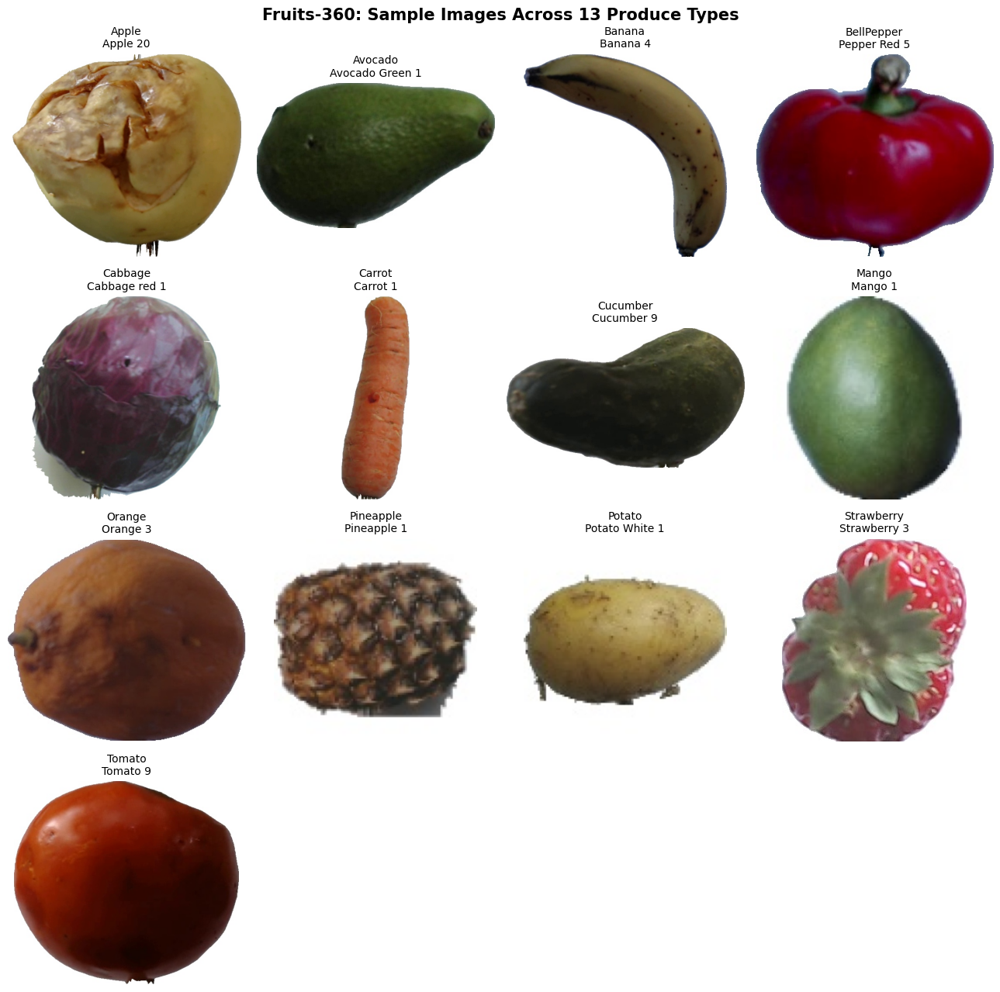

In [61]:
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from io import BytesIO
from zipfile import ZipFile

manifest = pd.read_csv(manifest_path)

# Select one reproducible random image per produce type
samples = (
    manifest.groupby("produce", group_keys=False)
    .sample(n=1, random_state=42)
    .sort_values("produce")
)

fig, axes = plt.subplots(4, 4, figsize=(13, 13))
axes = axes.flatten()

with ZipFile(archive_path, "r") as archive:
    for i, (_, row) in enumerate(samples.iterrows()):
        image_bytes = archive.read(row["archive_path"])

        with Image.open(BytesIO(image_bytes)) as img:
            axes[i].imshow(img.convert("RGB"))

        axes[i].set_title(
            f"{row['produce']}\n"
            f"{row['original_category']}",
            fontsize=10
        )
        axes[i].axis("off")

for j in range(len(samples), len(axes)):
    axes[j].axis("off")

plt.suptitle(
    "Fruits-360: Sample Images Across 13 Produce Types",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

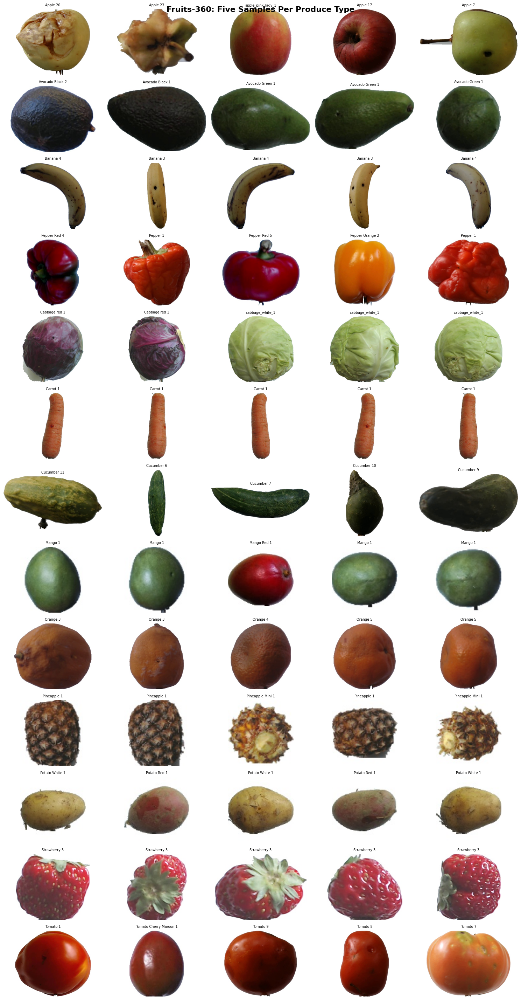

In [62]:
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
from zipfile import ZipFile

samples = (
    manifest.groupby("produce", group_keys=False)
    .sample(n=5, random_state=42)
    .sort_values("produce")
)

produce_types = sorted(manifest["produce"].unique())

fig, axes = plt.subplots(
    len(produce_types), 5,
    figsize=(15, 29)
)

with ZipFile(archive_path, "r") as archive:
    for row_idx, produce in enumerate(produce_types):
        produce_samples = samples[
            samples["produce"] == produce
        ]

        for col_idx, (_, row) in enumerate(
            produce_samples.iterrows()
        ):
            image_bytes = archive.read(row["archive_path"])

            with Image.open(BytesIO(image_bytes)) as img:
                axes[row_idx, col_idx].imshow(
                    img.convert("RGB")
                )

            axes[row_idx, col_idx].axis("off")

            if col_idx == 0:
                axes[row_idx, col_idx].set_ylabel(
                    produce,
                    fontsize=11,
                    rotation=90,
                    labelpad=12
                )

            axes[row_idx, col_idx].set_title(
                row["original_category"],
                fontsize=7
            )

plt.suptitle(
    "Fruits-360: Five Samples Per Produce Type",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
category_summary = (
    manifest.groupby(["produce", "original_category"])
    .size()
    .reset_index(name="image_count")
    .sort_values(["produce", "image_count"], ascending=[True, False])
)

print("FRUITS-360 CATEGORY BREAKDOWN")
print("=" * 55)

for produce in sorted(manifest["produce"].unique()):
    subset = category_summary[
        category_summary["produce"] == produce
    ]

    print(f"\n{produce.upper()} — {len(subset)} varieties")
    print(
        subset[["original_category", "image_count"]]
        .to_string(index=False)
    )

In [63]:
# Step 23.16 — Freshness Label Gap Analysis

import pandas as pd

# Original dataset labels from our baseline CNN
baseline_labels = set(class_names)

# All 13 target produce types
target_produce = [
    "Apple",
    "Banana",
    "Mango",
    "Orange",
    "Strawberry",
    "BellPepper",
    "Carrot",
    "Cucumber",
    "Potato",
    "Tomato",
    "Avocado",
    "Pineapple",
    "Cabbage"
]

# Normalize labels to handle spaces and underscores
def normalize_label(label):
    return str(label).lower().replace(" ", "").replace("_", "")

records = []

for produce in target_produce:

    normalized_produce = normalize_label(produce)

    fresh_matches = [
        label for label in baseline_labels
        if normalize_label(label).startswith("fresh")
        and normalized_produce in normalize_label(label)
    ]

    rotten_matches = [
        label for label in baseline_labels
        if normalize_label(label).startswith("rotten")
        and normalized_produce in normalize_label(label)
    ]

    records.append({
        "Produce": produce,
        "Baseline fresh label": ", ".join(sorted(fresh_matches)) or "MISSING",
        "Baseline rotten label": ", ".join(sorted(rotten_matches)) or "MISSING",
        "Fruits-360 images": int(
            (manifest["produce"] == produce).sum()
        )
    })

# Create results table
label_gap_df = pd.DataFrame(records)

# Display results
print("FRESHNESS LABEL GAP ANALYSIS")
print("=" * 80)
print(label_gap_df.to_string(index=False))

# Summary
print("\nSUMMARY")
print("=" * 80)

print("Total produce types:", len(target_produce))

print(
    "Produce types with fresh labels:",
    (label_gap_df["Baseline fresh label"] != "MISSING").sum()
)

print(
    "Produce types with rotten labels:",
    (label_gap_df["Baseline rotten label"] != "MISSING").sum()
)

print(
    "Produce types requiring new labels:",
    len(label_gap_df[
        (label_gap_df["Baseline fresh label"] == "MISSING") |
        (label_gap_df["Baseline rotten label"] == "MISSING")
    ])
)

FRESHNESS LABEL GAP ANALYSIS
   Produce Baseline fresh label Baseline rotten label  Fruits-360 images
     Apple              MISSING               MISSING              22035
    Banana              MISSING               MISSING                647
     Mango              MISSING               MISSING               1224
    Orange              MISSING               MISSING               4734
Strawberry              MISSING               MISSING               1266
BellPepper              MISSING               MISSING               5012
    Carrot              MISSING               MISSING                201
  Cucumber              MISSING               MISSING               8022
    Potato              MISSING               MISSING               1804
    Tomato              MISSING               MISSING               7730
   Avocado              MISSING               MISSING               2850
 Pineapple              MISSING               MISSING               1312
   Cabbage            

In [ ]:
# Step 23.16A — Inspect Original CNN Class Labels

print("ORIGINAL CNN CLASS LABELS")
print("=" * 50)

print("Variable type:", type(class_names))
print("Total classes:", len(class_names))

for index, label in enumerate(class_names):
    print(f"{index + 1:02d}. {label}")

In [64]:
# Step 23.16B — Corrected Freshness Label Gap Analysis

import pandas as pd

baseline_labels = set(class_names)

target_produce = [
    "Apple", "Banana", "Mango", "Orange",
    "Strawberry", "BellPepper", "Carrot",
    "Cucumber", "Potato", "Tomato",
    "Avocado", "Pineapple", "Cabbage"
]

def normalize_label(label):
    return str(label).lower().replace(" ", "").replace("_", "")

records = []

for produce in target_produce:

    normalized_produce = normalize_label(produce)

    fresh_matches = []
    rotten_matches = []

    for label in baseline_labels:

        # Remove Fruits/ or Vegetables/ prefix
        class_name = label.split("/")[-1]
        normalized_class = normalize_label(class_name)

        if normalized_class == f"fresh{normalized_produce}":
            fresh_matches.append(label)

        elif normalized_class == f"rotten{normalized_produce}":
            rotten_matches.append(label)

    records.append({
        "Produce": produce,
        "Baseline fresh label": ", ".join(sorted(fresh_matches)) or "MISSING",
        "Baseline rotten label": ", ".join(sorted(rotten_matches)) or "MISSING",
        "Fruits-360 images": int(
            (manifest["produce"] == produce).sum()
        )
    })

label_gap_df = pd.DataFrame(records)

print("CORRECTED FRESHNESS LABEL GAP ANALYSIS")
print("=" * 90)
print(label_gap_df.to_string(index=False))

print("\nSUMMARY")
print("=" * 90)

print("Total produce types:", len(target_produce))

print(
    "Produce types with fresh labels:",
    (label_gap_df["Baseline fresh label"] != "MISSING").sum()
)

print(
    "Produce types with rotten labels:",
    (label_gap_df["Baseline rotten label"] != "MISSING").sum()
)

missing_labels = label_gap_df[
    (label_gap_df["Baseline fresh label"] == "MISSING") |
    (label_gap_df["Baseline rotten label"] == "MISSING")
]

print("Produce types requiring new labels:", len(missing_labels))

print("\nPRODUCE TYPES REQUIRING NEW LABELLED DATA:")
print(missing_labels["Produce"].to_string(index=False))

CORRECTED FRESHNESS LABEL GAP ANALYSIS
   Produce       Baseline fresh label       Baseline rotten label  Fruits-360 images
     Apple          Fruits/FreshApple          Fruits/RottenApple              22035
    Banana         Fruits/FreshBanana         Fruits/RottenBanana                647
     Mango          Fruits/FreshMango          Fruits/RottenMango               1224
    Orange         Fruits/FreshOrange         Fruits/RottenOrange               4734
Strawberry     Fruits/FreshStrawberry     Fruits/RottenStrawberry               1266
BellPepper Vegetables/FreshBellpepper Vegetables/RottenBellpepper               5012
    Carrot     Vegetables/FreshCarrot     Vegetables/RottenCarrot                201
  Cucumber   Vegetables/FreshCucumber   Vegetables/RottenCucumber               8022
    Potato     Vegetables/FreshPotato     Vegetables/RottenPotato               1804
    Tomato     Vegetables/FreshTomato     Vegetables/RottenTomato               7730
   Avocado                

In [65]:
# Step 23.17 — Existing labelled dataset distribution

import pandas as pd

# Use the original cleaned dataset's training, validation
# and test manifests. Do not modify the splits.
baseline_df = pd.concat(
    [
        train_df.assign(split="train"),
        val_df.assign(split="validation"),
        test_df.assign(split="test")
    ],
    ignore_index=True
)

# Count examples in each original class
class_counts = (
    baseline_df.groupby(["label", "split"])
    .size()
    .unstack(fill_value=0)
)

# Include total number of examples
class_counts["Total"] = class_counts.sum(axis=1)

print("EXISTING FRESH / ROTTEN DATASET")
print("=" * 75)
print(class_counts.to_string())

print("\nSUMMARY")
print("=" * 75)
print("Total images:", len(baseline_df))
print("Total classes:", baseline_df["label"].nunique())
print("Smallest class:", class_counts["Total"].idxmin())
print("Smallest class count:", class_counts["Total"].min())
print("Largest class:", class_counts["Total"].idxmax())
print("Largest class count:", class_counts["Total"].max())

EXISTING FRESH / ROTTEN DATASET
split                        test  train  validation  Total
label                                                      
Fruits/FreshApple              91    424          91    606
Fruits/FreshBanana             93    436          94    623
Fruits/FreshMango              91    424          90    605
Fruits/FreshOrange             91    426          92    609
Fruits/FreshStrawberry         91    422          90    603
Fruits/RottenApple             88    410          88    586
Fruits/RottenBanana            87    403          86    576
Fruits/RottenMango             89    415          89    593
Fruits/RottenOrange            88    414          89    591
Fruits/RottenStrawberry        90    417          89    596
Vegetables/FreshBellpepper     90    420          90    600
Vegetables/FreshCarrot         91    426          91    608
Vegetables/FreshCucumber       89    414          88    591
Vegetables/FreshPotato         91    427          92    610
Vegetabl

In [66]:
from pathlib import Path
from datetime import datetime, timezone

checkpoint_dir = Path(
    "/content/google_drive/MyDrive/"
    "Food_Spoilage_Datasets/"
    "expanded_dataset_sources"
)

checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_file = checkpoint_dir / "PROJECT_CHECKPOINT_STEP_23.md"

checkpoint_text = """# Food Spoilage Detection — Project Checkpoint

## Status
Paused after Step 23.17 — Existing Labelled Dataset Audit.
CNN retraining has NOT started.

## 1. Baseline CNN — Completed
- Architecture: Custom CNN built from scratch
- Input: 224 x 224 RGB images
- Classes: 20 (10 fresh, 10 rotten)
- Parameters: 112,340
- Best validation accuracy: 76.94%
- Held-out test accuracy: 75.64%
- Original cleaned dataset: 11,766 images
- Training: 8,236 images
- Validation: 1,765 images
- Testing: 1,765 images

Saved baseline model:
MyDrive/Food_Spoilage_Models/best_food_spoilage_cnn.keras

Original cleaned dataset:
MyDrive/Food_Spoilage_Datasets/clean_food_spoilage_dataset.zip

Original dataset splits:
MyDrive/Food_Spoilage_Datasets/dataset_splits/

## 2. Dataset Expansion — Completed Preparation

Target: 13 produce types, 26 fresh/rotten classes.

Existing produce:
Apple, Banana, Mango, Orange, Strawberry,
Bell Pepper, Carrot, Cucumber, Potato, Tomato.

New produce:
Avocado, Pineapple, Cabbage.

Fruits-360 images selected: 57,226
Produce types represented: 13

Source archive:
MyDrive/Food_Spoilage_Datasets/expanded_dataset_sources/fruits360/fruits360_selected.zip

Source manifest:
MyDrive/Food_Spoilage_Datasets/expanded_dataset_sources/fruits360/fruits360_source_manifest.csv

Archive integrity: PASSED
Manifest records: 57,226
Unique archive paths: 57,226
Missing images: 0

Important:
Fruits-360 images have UNVERIFIED freshness labels.
Do not automatically label all images as fresh.
Multiple photographs may show the same physical produce item.
Preserve provenance and prevent data leakage.

## 3. Original Labelled Dataset Audit — Step 23.17

Total images: 11,766
Total classes: 20
Smallest class: Vegetables/RottenCarrot (506)
Largest class: Fruits/FreshBanana (623)

Baseline class distribution is reasonably balanced.

## 4. Work Not Yet Completed
- Find verified fresh and rotten images for avocado,
  pineapple and cabbage.
- Review freshness labels and image quality.
- Detect duplicate and near-duplicate images.
- Prevent leakage between training and evaluation splits.
- Balance the expanded dataset.
- Prepare the 26-class training dataset.
- Retrain and evaluate the improved custom CNN.
- Convert the selected model to TensorFlow Lite.
- Integrate offline inference into Flutter.

## 5. Next Step

Step 23.19 — Plan additional verified fresh and rotten
image sources for avocado, pineapple and cabbage.

Retraining remains PAUSED until explicitly resumed.

## 6. GitHub
Repository:
https://github.com/Deborah-dev-lab/food-spoilage-detection

CNN development branch:
feature/cnn-model

Notebook:
ml/notebooks/Food_Spoilage_CNN_Training.ipynb

Save and commit the updated notebook when returning
to the local development environment.

Do not commit large dataset ZIP archives to GitHub.
"""

checkpoint_file.write_text(checkpoint_text, encoding="utf-8")

print("PROJECT CHECKPOINT")
print("=" * 55)
print("Checkpoint saved:", checkpoint_file.exists())
print("Location:", checkpoint_file)
print("Current step: 23.17 completed")
print("Next step: 23.19")
print("CNN retraining: PAUSED")

PROJECT CHECKPOINT
Checkpoint saved: True
Location: /content/google_drive/MyDrive/Food_Spoilage_Datasets/expanded_dataset_sources/PROJECT_CHECKPOINT_STEP_23.md
Current step: 23.17 completed
Next step: 23.19
CNN retraining: PAUSED


In [67]:
# Step 24.1 — Restore CNN Training Environment

import os
import tensorflow as tf
import pandas as pd
import numpy as np

from pathlib import Path
from google.colab import drive

# Mount Google Drive
drive.mount("/content/google_drive")

# Define saved project locations
DATASET_DIR = Path(
    "/content/google_drive/MyDrive/Food_Spoilage_Datasets"
)

MODEL_DIR = Path(
    "/content/google_drive/MyDrive/Food_Spoilage_Models"
)

SPLITS_DIR = DATASET_DIR / "dataset_splits"

BASELINE_MODEL = MODEL_DIR / "best_food_spoilage_cnn.keras"

CLEAN_DATASET = DATASET_DIR / "clean_food_spoilage_dataset.zip"

# Check environment
print("CNN RETRAINING ENVIRONMENT")
print("=" * 55)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

print("\nSAVED PROJECT FILES")
print("=" * 55)

files_to_check = {
    "Baseline CNN": BASELINE_MODEL,
    "Clean dataset": CLEAN_DATASET,
    "Training split": SPLITS_DIR / "train_split.csv",
    "Validation split": SPLITS_DIR / "validation_split.csv",
    "Test split": SPLITS_DIR / "test_split.csv"
}

for name, path in files_to_check.items():
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

Drive already mounted at /content/google_drive; to attempt to forcibly remount, call drive.mount("/content/google_drive", force_remount=True).
CNN RETRAINING ENVIRONMENT
TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

SAVED PROJECT FILES
Baseline CNN: FOUND
Clean dataset: FOUND
Training split: FOUND
Validation split: FOUND
Test split: FOUND


In [70]:
# Step 24.2 — Restore Cleaned Dataset and Splits

import os
import zipfile
import pandas as pd
from pathlib import Path

# 1. Define paths
DATASET_DIR = Path(
    "/content/google_drive/MyDrive/Food_Spoilage_Datasets"
)

CLEAN_DATASET = DATASET_DIR / "clean_food_spoilage_dataset.zip"
SPLITS_DIR = DATASET_DIR / "dataset_splits"

EXTRACT_DIR = Path("/content/food_spoilage_v2")

# 2. Extract cleaned dataset
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

print("Extracting cleaned dataset...")

with zipfile.ZipFile(CLEAN_DATASET, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extraction complete!")

# 3. Restore original splits
train_df = pd.read_csv(SPLITS_DIR / "train_split.csv")
val_df = pd.read_csv(SPLITS_DIR / "validation_split.csv")
test_df = pd.read_csv(SPLITS_DIR / "test_split.csv")

# 4. Display split information
print("\nDATASET SPLITS")
print("=" * 55)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTotal images:",
      len(train_df) + len(val_df) + len(test_df))

# 5. Inspect saved image paths
print("\nSAMPLE SAVED PATHS")
print("=" * 55)

print(train_df["filepath"].head(3).to_string(index=False))

# 6. Inspect extracted folder structure
print("\nEXTRACTED TOP-LEVEL CONTENTS")
print("=" * 55)

for item in EXTRACT_DIR.iterdir():
    print(item.name)

Extracting cleaned dataset...
Dataset extraction complete!

DATASET SPLITS
Training images: 8236
Validation images: 1765
Testing images: 1765

Total images: 11766

SAMPLE SAVED PATHS
      Fruits/FreshApple/freshApple (152).jpg
Vegetables/FreshPotato/freshPotato (156).jpg
      Fruits/FreshApple/freshApple (610).png

EXTRACTED TOP-LEVEL CONTENTS
clean_food_spoilage_dataset


In [76]:
# Step 24.3 — Reconnect and Verify Image Paths

from pathlib import Path

# Root folder containing Fruits/ and Vegetables/
IMAGE_ROOT = (
    EXTRACT_DIR / "clean_food_spoilage_dataset"
)

print("IMAGE ROOT:", IMAGE_ROOT)
print("Root exists:", IMAGE_ROOT.exists())

# Create absolute image paths
for df in [train_df, val_df, test_df]:
    df["absolute_path"] = df["filepath"].apply(
        lambda path: str(IMAGE_ROOT / Path(path))
    )

# Verify every image exists
print("\nIMAGE PATH VERIFICATION")
print("=" * 55)

for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    existing = df["absolute_path"].apply(
        lambda path: Path(path).is_file()
    )

    print(f"{name}: {existing.sum():,}/{len(df):,} images found")

    if not existing.all():
        print("Sample missing paths:")
        print(
            df.loc[~existing, "absolute_path"]
            .head(5)
            .to_string(index=False)
        )

# Check class labels
class_names = sorted(train_df["label"].unique())

print("\nCLASS INFORMATION")
print("=" * 55)
print("Total classes:", len(class_names))
print("Class names:")
for index, name in enumerate(class_names):
    print(f"{index:02d}: {name}")

# Final validation
all_paths_valid = all(
    df["absolute_path"].apply(
        lambda path: Path(path).is_file()
    ).all()
    for df in [train_df, val_df, test_df]
)

print("\nAll image paths valid:", all_paths_valid)

IMAGE ROOT: /content/food_spoilage_v2/clean_food_spoilage_dataset
Root exists: True

IMAGE PATH VERIFICATION
Training: 8,163/8,236 images found
Sample missing paths:
/content/food_spoilage_v2/clean_food_spoilage_d...
/content/food_spoilage_v2/clean_food_spoilage_d...
/content/food_spoilage_v2/clean_food_spoilage_d...
/content/food_spoilage_v2/clean_food_spoilage_d...
/content/food_spoilage_v2/clean_food_spoilage_d...
Validation: 1,744/1,765 images found
Sample missing paths:
/content/food_spoilage_v2/clean_food_spoilage_d...
/content/food_spoilage_v2/clean_food_spoilage_d...
/content/food_spoilage_v2/clean_food_spoilage_d...
/content/food_spoilage_v2/clean_food_spoilage_d...
/content/food_spoilage_v2/clean_food_spoilage_d...
Testing: 1,751/1,765 images found
Sample missing paths:
/content/food_spoilage_v2/clean_food_spoilage_d...
/content/food_spoilage_v2/clean_food_spoilage_d...
/content/food_spoilage_v2/clean_food_spoilage_d...
/content/food_spoilage_v2/clean_food_spoilage_d...
/cont

In [78]:
from pathlib import Path
import pandas as pd
import os

print("=" * 65)
print("FRESHTRACK — DATASET PATH DIAGNOSTIC")
print("=" * 65)

# 1. Check the path that caused the error
missing_path = Path(
    "/content/food_spoilage_v2/"
    "clean_food_spoilage_dataset/"
    "Vegetables/FreshCucumber/"
    "freshCucumber (282).jpg"
)

print("\n1. ORIGINAL FILE PATH")
print("Path:", missing_path)
print("Exists:", missing_path.exists())

# 2. Check where datasets are currently stored
print("\n2. DATASET DIRECTORIES")

for directory in [
    "/content/food_spoilage_v2",
    "/content/v3_original",
    "/content",
]:
    folder = Path(directory)

    print(f"\n{directory}")
    print("Exists:", folder.exists())

    if folder.exists():
        for item in list(folder.iterdir())[:20]:
            print("  ", item.name)

# 3. Inspect dataframe paths
print("\n3. DATAFRAME PATH CHECK")

for name, df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df),
]:
    print(f"\n{name}")
    print("Total records:", len(df))

    if "absolute_path" in df.columns:
        paths = df["absolute_path"].astype(str)

        existing = paths.map(os.path.isfile)

        print("Existing files:", int(existing.sum()))
        print("Missing files:", int((~existing).sum()))

        if (~existing).any():
            print("Example missing path:")
            print(paths[~existing].iloc[0])

# 4. Find the cucumber image in the current Colab runtime
print("\n4. SEARCHING FOR THE MISSING IMAGE")

matches = list(
    Path("/content").glob(
        "**/freshCucumber (282).jpg"
    )
)

print("Matching files found:", len(matches))

for match in matches[:10]:
    print(match)

print("\nDIAGNOSTIC COMPLETE")

FRESHTRACK — DATASET PATH DIAGNOSTIC

1. ORIGINAL FILE PATH
Path: /content/food_spoilage_v2/clean_food_spoilage_dataset/Vegetables/FreshCucumber/freshCucumber (282).jpg
Exists: False

2. DATASET DIRECTORIES

/content/food_spoilage_v2
Exists: True
   clean_food_spoilage_dataset

/content/v3_original
Exists: False

/content
Exists: True
   .config
   food_spoilage_dataset
   cnn_checkpoints
   google_drive
   food_spoilage_v2
   drive
   clean_food_spoilage_dataset
   sample_data

3. DATAFRAME PATH CHECK

TRAIN
Total records: 8236
Existing files: 8163
Missing files: 73
Example missing path:
/content/food_spoilage_v2/clean_food_spoilage_dataset/Vegetables/RottenCarrot/rottenCarrot (110).jpg

VALIDATION
Total records: 1765
Existing files: 1744
Missing files: 21
Example missing path:
/content/food_spoilage_v2/clean_food_spoilage_dataset/Vegetables/RottenPotato/rottenPotato (391).jpg

TEST
Total records: 1765
Existing files: 1751
Missing files: 14
Example missing path:
/content/food_spoilage

In [80]:
from pathlib import Path
import pandas as pd
import os

print("=" * 65)
print("FRESHTRACK — DATASET PATH REPAIR")
print("=" * 65)

# Existing dataset root
OLD_ROOT = Path(
    "/content/food_spoilage_v2/clean_food_spoilage_dataset"
)

# Alternative cleaned dataset root
NEW_ROOT = Path(
    "/content/clean_food_spoilage_dataset"
)

print("\nOLD ROOT:", OLD_ROOT)
print("Exists:", OLD_ROOT.exists())

print("\nNEW ROOT:", NEW_ROOT)
print("Exists:", NEW_ROOT.exists())

# Preserve original dataframes for comparison
train_df_before_repair = train_df.copy()
val_df_before_repair = val_df.copy()
test_df_before_repair = test_df.copy()


def repair_paths(df, dataset_name):

    df = df.copy()

    repaired_count = 0
    unresolved = []

    corrected_paths = []

    for original_path in df["absolute_path"].astype(str):

        original = Path(original_path)

        # Keep existing paths unchanged
        if original.is_file():
            corrected_paths.append(str(original))
            continue

        # Only replace the known dataset root
        try:
            relative_path = original.relative_to(OLD_ROOT)

        except ValueError:
            corrected_paths.append(str(original))
            unresolved.append(str(original))
            continue

        candidate = NEW_ROOT / relative_path

        if candidate.is_file():

            corrected_paths.append(str(candidate))
            repaired_count += 1

        else:

            corrected_paths.append(str(original))
            unresolved.append(str(original))

    df["absolute_path"] = corrected_paths

    existing = df["absolute_path"].map(os.path.isfile)

    print(f"\n{dataset_name}")
    print("-" * 45)
    print("Total images:", len(df))
    print("Paths repaired:", repaired_count)
    print("Valid paths:", int(existing.sum()))
    print("Missing paths:", int((~existing).sum()))

    if unresolved:
        print("\nFirst unresolved paths:")

        for path in unresolved[:5]:
            print(path)

    return df


# Repair the original dataframes
train_df = repair_paths(train_df, "TRAINING")
val_df = repair_paths(val_df, "VALIDATION")
test_df = repair_paths(test_df, "TESTING")


print("\n" + "=" * 65)
print("FINAL VALIDATION")
print("=" * 65)

total_missing = sum(
    (~df["absolute_path"].map(os.path.isfile)).sum()
    for df in [train_df, val_df, test_df]
)

print("Total missing files:", int(total_missing))

print("\nDataset sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

if total_missing == 0:
    print("\nPASS: All dataset image paths are valid.")
    print("Ready to proceed to TensorFlow pipeline validation.")
else:
    print("\nREVIEW REQUIRED: Some image paths remain unresolved.")
    print("Do not begin training until these are investigated.")

FRESHTRACK — DATASET PATH REPAIR

OLD ROOT: /content/food_spoilage_v2/clean_food_spoilage_dataset
Exists: True

NEW ROOT: /content/clean_food_spoilage_dataset
Exists: True

TRAINING
---------------------------------------------
Total images: 8236
Paths repaired: 73
Valid paths: 8236
Missing paths: 0

VALIDATION
---------------------------------------------
Total images: 1765
Paths repaired: 21
Valid paths: 1765
Missing paths: 0

TESTING
---------------------------------------------
Total images: 1765
Paths repaired: 14
Valid paths: 1765
Missing paths: 0

FINAL VALIDATION
Total missing files: 0

Dataset sizes:
Training: 8236
Validation: 1765
Testing: 1765

PASS: All dataset image paths are valid.
Ready to proceed to TensorFlow pipeline validation.


In [81]:
# Step 24.5 — Build Improved Custom CNN Version 2

import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

def build_cnn_v2():

    model = models.Sequential(
        name="FoodSpoilage_CNN_V2"
    )

    model.add(
        layers.Input(shape=(224, 224, 3))
    )

    # Block 1 — Basic visual features
    model.add(layers.Conv2D(
        32, (3, 3), padding="same", activation="relu"
    ))
    model.add(layers.BatchNormalization())

    model.add(layers.Conv2D(
        32, (3, 3), padding="same", activation="relu"
    ))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))

    # Block 2 — Colour and texture patterns
    model.add(layers.Conv2D(
        64, (3, 3), padding="same", activation="relu"
    ))
    model.add(layers.BatchNormalization())

    model.add(layers.Conv2D(
        64, (3, 3), padding="same", activation="relu"
    ))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))

    # Block 3 — More complex spoilage patterns
    model.add(layers.Conv2D(
        128, (3, 3), padding="same", activation="relu"
    ))
    model.add(layers.BatchNormalization())

    model.add(layers.Conv2D(
        128, (3, 3), padding="same", activation="relu"
    ))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))

    # Block 4 — High-level features
    model.add(layers.Conv2D(
        256, (3, 3), padding="same", activation="relu"
    ))
    model.add(layers.BatchNormalization())

    model.add(layers.Conv2D(
        256, (3, 3), padding="same", activation="relu"
    ))
    model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D((2, 2)))

    # Classification layers
    model.add(layers.GlobalAveragePooling2D())

    model.add(layers.Dense(
        128, activation="relu"
    ))

    model.add(layers.Dropout(0.35))

    model.add(layers.Dense(
        NUM_CLASSES, activation="softmax"
    ))

    return model


# Create model
cnn_v2 = build_cnn_v2()

# Compile model
cnn_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display architecture
cnn_v2.summary()

print("\nCNN VERSION 2 CREATED SUCCESSFULLY")
print("=" * 55)
print("Input shape:", cnn_v2.input_shape)
print("Output shape:", cnn_v2.output_shape)
print("Total parameters:", cnn_v2.count_params())
print("Number of classes:", NUM_CLASSES)

Model: "FoodSpoilage_CNN_V2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 256)            │             

 Total params: 1,211,572 (4.62 MB)

 Trainable params: 1,209,652 (4.61 MB)

 Non-trainable params: 1,920 (7.50 KB)


CNN VERSION 2 CREATED SUCCESSFULLY
Input shape: (None, 224, 224, 3)
Output shape: (None, 20)
Total parameters: 1211572
Number of classes: 20


In [82]:
# Step 24.6 — Configure CNN Version 2 Training

import tensorflow as tf
from pathlib import Path

# Directory for saved CNN models
MODEL_DIR = Path(
    "/content/google_drive/MyDrive/Food_Spoilage_Models"
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Separate checkpoint for CNN Version 2
V2_MODEL_PATH = MODEL_DIR / "best_food_spoilage_cnn_v2.keras"

# Training configuration
EPOCHS_V2 = 35

callbacks_v2 = [

    # Save the model with the lowest validation loss
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(V2_MODEL_PATH),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    # Stop training if validation loss stops improving
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    # Reduce learning rate when progress slows
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    # Record training metrics for later analysis
    tf.keras.callbacks.CSVLogger(
        str(MODEL_DIR / "cnn_v2_training_log.csv")
    )
]

print("CNN VERSION 2 — TRAINING CONFIGURATION")
print("=" * 55)

print("Maximum epochs:", EPOCHS_V2)
print("Initial learning rate:", 0.0005)
print("Early stopping patience:", 7)
print("Learning-rate reduction patience:", 3)
print("Checkpoint location:", V2_MODEL_PATH)

print("\nCONFIGURED CALLBACKS:")
for callback in callbacks_v2:
    print("-", callback.__class__.__name__)

print("\nBaseline model preserved:",
      (MODEL_DIR / "best_food_spoilage_cnn.keras").exists())

CNN VERSION 2 — TRAINING CONFIGURATION
Maximum epochs: 35
Initial learning rate: 0.0005
Early stopping patience: 7
Learning-rate reduction patience: 3
Checkpoint location: /content/google_drive/MyDrive/Food_Spoilage_Models/best_food_spoilage_cnn_v2.keras

CONFIGURED CALLBACKS:
- ModelCheckpoint
- EarlyStopping
- ReduceLROnPlateau
- CSVLogger

Baseline model preserved: True


In [83]:
# Step 24.6 — Configure CNN Version 2 Training

import tensorflow as tf
from pathlib import Path

# Directory for saved CNN models
MODEL_DIR = Path(
    "/content/google_drive/MyDrive/Food_Spoilage_Models"
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Separate checkpoint for CNN Version 2
V2_MODEL_PATH = MODEL_DIR / "best_food_spoilage_cnn_v2.keras"

# Training configuration
EPOCHS_V2 = 35

callbacks_v2 = [

    # Save the model with the lowest validation loss
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(V2_MODEL_PATH),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    # Stop training if validation loss stops improving
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    # Reduce learning rate when progress slows
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    # Record training metrics for later analysis
    tf.keras.callbacks.CSVLogger(
        str(MODEL_DIR / "cnn_v2_training_log.csv")
    )
]

print("CNN VERSION 2 — TRAINING CONFIGURATION")
print("=" * 55)

print("Maximum epochs:", EPOCHS_V2)
print("Initial learning rate:", 0.0005)
print("Early stopping patience:", 7)
print("Learning-rate reduction patience:", 3)
print("Checkpoint location:", V2_MODEL_PATH)

print("\nCONFIGURED CALLBACKS:")
for callback in callbacks_v2:
    print("-", callback.__class__.__name__)

print("\nBaseline model preserved:",
      (MODEL_DIR / "best_food_spoilage_cnn.keras").exists())

CNN VERSION 2 — TRAINING CONFIGURATION
Maximum epochs: 35
Initial learning rate: 0.0005
Early stopping patience: 7
Learning-rate reduction patience: 3
Checkpoint location: /content/google_drive/MyDrive/Food_Spoilage_Models/best_food_spoilage_cnn_v2.keras

CONFIGURED CALLBACKS:
- ModelCheckpoint
- EarlyStopping
- ReduceLROnPlateau
- CSVLogger

Baseline model preserved: True


In [86]:
from pathlib import Path
import os

print("=" * 60)
print("FRESHTRACK — PRE-TRAINING FILE VALIDATION")
print("=" * 60)

all_valid = True

for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    missing = [
        p for p in df["absolute_path"].astype(str)
        if not os.path.isfile(p)
    ]

    print(f"{name}: {len(df)} images")
    print(f"  Missing: {len(missing)}")

    if missing:
        all_valid = False
        print("  Example:", missing[0])

print("\nAll paths valid:", all_valid)

FRESHTRACK — PRE-TRAINING FILE VALIDATION
Training: 8236 images
  Missing: 0
Validation: 1765 images
  Missing: 0
Testing: 1765 images
  Missing: 0

All paths valid: True


In [87]:
from pathlib import Path
import os

print("=" * 60)
print("FRESHTRACK — PRE-TRAINING FILE VALIDATION")
print("=" * 60)

all_valid = True

for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    missing = [
        p for p in df["absolute_path"].astype(str)
        if not os.path.isfile(p)
    ]

    print(f"{name}: {len(df)} images")
    print(f"  Missing: {len(missing)}")

    if missing:
        all_valid = False
        print("  Example:", missing[0])

print("\nAll paths valid:", all_valid)

FRESHTRACK — PRE-TRAINING FILE VALIDATION
Training: 8236 images
  Missing: 0
Validation: 1765 images
  Missing: 0
Testing: 1765 images
  Missing: 0

All paths valid: True


In [88]:
print("=" * 60)
print("FRESHTRACK — REBUILD TENSORFLOW PIPELINES")
print("=" * 60)

# Recreate datasets using the corrected dataframe paths
train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df, training=False)
test_ds = create_dataset(test_df, training=False)

# Reapply training-only augmentation
train_augmented_ds = train_ds.map(
    lambda images, labels: (
        tf.clip_by_value(
            data_augmentation_v2(images, training=True),
            0.0,
            1.0
        ),
        labels
    ),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

# Verify training data
for images, labels in train_augmented_ds.take(1):
    print("Training batch:", images.shape)
    print("Labels:", labels.shape)

# Verify validation data
for images, labels in val_ds.take(1):
    print("Validation batch:", images.shape)

# Verify testing data
for images, labels in test_ds.take(1):
    print("Testing batch:", images.shape)

print("\nPASS: TensorFlow pipelines rebuilt successfully.")

FRESHTRACK — REBUILD TENSORFLOW PIPELINES
Training batch: (32, 224, 224, 3)
Labels: (32,)
Validation batch: (32, 224, 224, 3)
Testing batch: (32, 224, 224, 3)

PASS: TensorFlow pipelines rebuilt successfully.


In [91]:
# Step 24.7 — Train CNN Version 2
%%script echo
CNN V2 training skipped — proceeding to CNN V3.

import tensorflow as tf
import time

print("CNN VERSION 2 — TRAINING")
print("=" * 55)

# Verify GPU availability
gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus)

if not gpus:
    print("WARNING: No GPU detected. Training may be very slow.")

print("\nTraining images:", len(train_df))
print("Validation images:", len(val_df))
print("Number of classes:", NUM_CLASSES)
print("Maximum epochs:", EPOCHS_V2)

print("\nStarting CNN Version 2 training...\n")

start_time = time.time()

# Train using augmented training images
history_v2 = cnn_v2.fit(
    train_augmented_ds,
    validation_data=val_ds,
    epochs=EPOCHS_V2,
    callbacks=callbacks_v2,
    verbose=1
)

end_time = time.time()

training_minutes = (end_time - start_time) / 60

print("\nCNN VERSION 2 — TRAINING COMPLETE")
print("=" * 55)

print(f"Training duration: {training_minutes:.2f} minutes")
print("Epochs completed:", len(history_v2.history["loss"]))

print(
    "Best validation accuracy:",
    f"{max(history_v2.history['val_accuracy']) * 100:.2f}%"
)

print(
    "Best validation loss:",
    f"{min(history_v2.history['val_loss']):.4f}"
)

print("\nSaved checkpoint:", V2_MODEL_PATH)
print("Checkpoint exists:", V2_MODEL_PATH.exists())

In [ ]:
# Step 24.8 — CNN Version 2 Training Curves

import matplotlib.pyplot as plt
from pathlib import Path

history = history_v2.history

epochs = range(1, len(history["accuracy"]) + 1)

best_epoch = min(
    range(len(history["val_loss"])),
    key=lambda i: history["val_loss"][i]
) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy graph
axes[0].plot(
    epochs,
    history["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    epochs,
    history["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Checkpoint: Epoch {best_epoch}"
)

axes[0].set_title("CNN Version 2 — Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss graph
axes[1].plot(
    epochs,
    history["loss"],
    label="Training Loss"
)

axes[1].plot(
    epochs,
    history["val_loss"],
    label="Validation Loss"
)

axes[1].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Checkpoint: Epoch {best_epoch}"
)

axes[1].set_title("CNN Version 2 — Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

# Save graphs to Google Drive
plot_path = (
    Path("/content/google_drive/MyDrive/Food_Spoilage_Models")
    / "cnn_v2_training_curves.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Best checkpoint epoch:", best_epoch)
print("Training curves saved:", plot_path.exists())
print("Location:", plot_path)

In [ ]:
# STEP 24.9 — CNN VERSION 2 TEST EVALUATION

import tensorflow as tf

# Load best model saved during training
best_cnn_v2 = tf.keras.models.load_model(
    str(V2_MODEL_PATH)
)

print("CNN VERSION 2 — TEST EVALUATION")
print("=" * 55)

test_loss_v2, test_accuracy_v2 = best_cnn_v2.evaluate(
    test_ds,
    verbose=1
)

# Baseline CNN Version 1
baseline_accuracy = 0.7564

improvement = (
    test_accuracy_v2 - baseline_accuracy
) * 100

print("\nTEST RESULTS")
print("=" * 55)

print(f"CNN Version 1 Accuracy: {baseline_accuracy * 100:.2f}%")
print(f"CNN Version 2 Accuracy: {test_accuracy_v2 * 100:.2f}%")
print(f"CNN Version 2 Loss: {test_loss_v2:.4f}")

print(
    f"Improvement: {improvement:+.2f} percentage points"
)

print("\nTest images evaluated:", len(test_df))
print("Classes evaluated:", NUM_CLASSES)

In [ ]:
# STEP 24.10 — CLASSIFICATION REPORT

import numpy as np
import pandas as pd
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score
)

print("CNN VERSION 2 — CLASSIFICATION REPORT")
print("=" * 60)

# Predict probabilities for the test dataset
predicted_probabilities_v2 = best_cnn_v2.predict(
    test_ds,
    verbose=1
)

# Convert probabilities to predicted class IDs
y_pred_v2 = np.argmax(
    predicted_probabilities_v2,
    axis=1
)

# Actual class IDs, in the same order as test_ds
y_true_v2 = test_df["class_id"].to_numpy()

# Generate classification report
report_v2 = classification_report(
    y_true_v2,
    y_pred_v2,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("\nCLASSIFICATION REPORT")
print("=" * 60)
print(report_v2)

# Overall performance
print("\nOVERALL PERFORMANCE")
print("=" * 60)

print(
    "Test accuracy:",
    f"{accuracy_score(y_true_v2, y_pred_v2) * 100:.2f}%"
)

print(
    "Macro F1-score:",
    f"{f1_score(y_true_v2, y_pred_v2, average='macro'):.4f}"
)

print(
    "Weighted F1-score:",
    f"{f1_score(y_true_v2, y_pred_v2, average='weighted'):.4f}"
)

# Save report to Google Drive
report_path_v2 = (
    MODEL_DIR / "cnn_v2_classification_report.txt"
)

report_path_v2.write_text(report_v2)

print("\nReport saved:", report_path_v2.exists())
print("Location:", report_path_v2)

In [ ]:
# STEP 24.11 — CNN VERSION 2 CONFUSION MATRIX

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm_v2 = confusion_matrix(
    y_true_v2,
    y_pred_v2,
    labels=list(range(NUM_CLASSES))
)

# Display matrix
fig, ax = plt.subplots(figsize=(15, 13))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_v2,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)

plt.title("CNN Version 2 — Test Confusion Matrix")
plt.tight_layout()

# Save to Google Drive
cm_path = MODEL_DIR / "cnn_v2_confusion_matrix.png"

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Check freshness-level errors
true_freshness = np.array([
    "Rotten" if "Rotten" in class_names[i] else "Fresh"
    for i in y_true_v2
])

pred_freshness = np.array([
    "Rotten" if "Rotten" in class_names[i] else "Fresh"
    for i in y_pred_v2
])

freshness_cm = confusion_matrix(
    true_freshness,
    pred_freshness,
    labels=["Fresh", "Rotten"]
)

print("\nFRESHNESS-LEVEL CONFUSION MATRIX")
print("=" * 55)

print(
    pd.DataFrame(
        freshness_cm,
        index=["Actual Fresh", "Actual Rotten"],
        columns=["Predicted Fresh", "Predicted Rotten"]
    )
)

print("\nCRITICAL ERRORS")
print("=" * 55)

print(
    "Rotten predicted as Fresh:",
    freshness_cm[1, 0]
)

print(
    "Fresh predicted as Rotten:",
    freshness_cm[0, 1]
)

print("\nConfusion matrix saved:", cm_path.exists())
print("Location:", cm_path)

In [ ]:
# STEP 24.13 — VALIDATE PRODUCE AND FRESHNESS PREDICTIONS

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Use predictions already generated in Step 24.10
probs = predicted_probabilities_v2

def extract_produce(label):
    return label.split("/")[-1].replace(
        "Fresh", ""
    ).replace(
        "Rotten", ""
    )

def extract_freshness(label):
    return (
        "Rotten" if "Rotten" in label
        else "Fresh"
    )

# Create unique produce types
produce_names = sorted(set(
    extract_produce(label)
    for label in class_names
))

# Group class indices by produce and freshness
produce_indices = {
    produce: [
        i for i, label in enumerate(class_names)
        if extract_produce(label) == produce
    ]
    for produce in produce_names
}

fresh_indices = [
    i for i, label in enumerate(class_names)
    if extract_freshness(label) == "Fresh"
]

rotten_indices = [
    i for i, label in enumerate(class_names)
    if extract_freshness(label) == "Rotten"
]

# Group probabilities
produce_probs = np.column_stack([
    probs[:, indices].sum(axis=1)
    for indices in produce_indices.values()
])

fresh_probs = probs[:, fresh_indices].sum(axis=1)
rotten_probs = probs[:, rotten_indices].sum(axis=1)

# Final predictions
predicted_produce = np.array(produce_names)[
    np.argmax(produce_probs, axis=1)
]

predicted_freshness = np.where(
    rotten_probs > fresh_probs,
    "Rotten",
    "Fresh"
)

# Ground truth
true_produce = np.array([
    extract_produce(class_names[i])
    for i in y_true_v2
])

true_freshness = np.array([
    extract_freshness(class_names[i])
    for i in y_true_v2
])

# Evaluation
print("CNN VERSION 2 — GROUPED CLASSIFICATION")
print("=" * 55)

print(
    "Produce identification accuracy:",
    f"{accuracy_score(true_produce, predicted_produce)*100:.2f}%"
)

print(
    "Freshness classification accuracy:",
    f"{accuracy_score(true_freshness, predicted_freshness)*100:.2f}%"
)

print("\nFRESHNESS CONFUSION MATRIX")
print("=" * 55)

cm = confusion_matrix(
    true_freshness,
    predicted_freshness,
    labels=["Fresh", "Rotten"]
)

print("                  Predicted Fresh  Predicted Rotten")
print(f"Actual Fresh      {cm[0,0]:15d}  {cm[0,1]:16d}")
print(f"Actual Rotten     {cm[1,0]:15d}  {cm[1,1]:16d}")

print("\nFRESHNESS CLASSIFICATION REPORT")
print("=" * 55)

print(classification_report(
    true_freshness,
    predicted_freshness,
    labels=["Fresh", "Rotten"],
    digits=4
))

print("\nRotten predicted as Fresh:", cm[1, 0])
print("Fresh predicted as Rotten:", cm[0, 1])

In [ ]:
# STEP 24.14 — REAL-WORLD IMAGE PREDICTION

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from google.colab import files
from PIL import Image, ImageOps
from io import BytesIO

def predict_smartphone_image(image_bytes):

    image = Image.open(BytesIO(image_bytes))
    image = ImageOps.exif_transpose(image).convert("RGB")

    # Match the model's training preprocessing
    image_resized = image.resize(
        (224, 224),
        resample=Image.Resampling.BILINEAR
    )

    image_array = (
        np.asarray(image_resized, dtype=np.float32) / 255.0
    )

    image_batch = np.expand_dims(image_array, axis=0)

    probabilities = best_cnn_v2.predict(
        image_batch, verbose=0
    )[0]

    # Group by produce type
    produce_scores = {
        produce: float(probabilities[indices].sum())
        for produce, indices in produce_indices.items()
    }

    predicted_produce = max(
        produce_scores, key=produce_scores.get
    )

    # Group by freshness status
    fresh_score = float(
        probabilities[fresh_indices].sum()
    )

    rotten_score = float(
        probabilities[rotten_indices].sum()
    )

    predicted_freshness = (
        "Rotten" if rotten_score > fresh_score
        else "Fresh"
    )

    return {
        "image": image,
        "produce": predicted_produce,
        "produce_probability": produce_scores[predicted_produce],
        "freshness": predicted_freshness,
        "fresh_probability": fresh_score,
        "rotten_probability": rotten_score
    }


print("UPLOAD ONE REAL SMARTPHONE PHOTOGRAPH")
print("=" * 55)

uploaded = files.upload()

for filename, image_bytes in uploaded.items():

    result = predict_smartphone_image(image_bytes)

    plt.figure(figsize=(6, 5))
    plt.imshow(result["image"])
    plt.axis("off")
    plt.title(filename)
    plt.show()

    print("\nCNN VERSION 2 — SMARTPHONE TEST")
    print("=" * 55)
    print("File:", filename)
    print("Predicted produce:", result["produce"])
    print("Predicted freshness:", result["freshness"])

    print(
        "Produce probability:",
        f"{result['produce_probability'] * 100:.2f}%"
    )

    print(
        "Fresh probability:",
        f"{result['fresh_probability'] * 100:.2f}%"
    )

    print(
        "Rotten probability:",
        f"{result['rotten_probability'] * 100:.2f}%"
    )

    print("\nNote: Probabilities are not verified food-safety scores.")

In [ ]:
# STEP 24.15 — TEST CROPPED APPLE IMAGE

import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from io import BytesIO

print("Upload the same apples photograph again.")

uploaded = files.upload()

filename = next(iter(uploaded))

image = Image.open(
    BytesIO(uploaded[filename])
).convert("RGB")

# Display image for selecting crop coordinates
plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.title("Select one apple to crop")
plt.axis("on")
plt.show()

print("Image dimensions:", image.size)

In [ ]:
# STEP 24.16 — CROP AND TEST ONE APPLE

import matplotlib.pyplot as plt
import numpy as np
from io import BytesIO
from PIL import Image

# Use the photograph uploaded in Step 24.15
image = Image.open(
    BytesIO(uploaded[filename])
).convert("RGB")

# Crop the central apple
crop_box = (465, 395, 700, 630)

cropped_apple = image.crop(crop_box)

# Convert cropped image to bytes for existing prediction function
buffer = BytesIO()
cropped_apple.save(buffer, format="JPEG")
cropped_bytes = buffer.getvalue()

# Predict original and cropped images
original_result = predict_smartphone_image(
    uploaded[filename]
)

cropped_result = predict_smartphone_image(
    cropped_bytes
)

# Display comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image)
axes[0].set_title("Original Photograph")
axes[0].axis("off")

axes[1].imshow(cropped_apple)
axes[1].set_title("Cropped Apple")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Print results
print("\nCNN VERSION 2 — ORIGINAL VS CROPPED")
print("=" * 60)

print("\nORIGINAL IMAGE")
print("Produce:", original_result["produce"])
print("Freshness:", original_result["freshness"])
print(
    "Produce probability:",
    f"{original_result['produce_probability'] * 100:.2f}%"
)

print("\nCROPPED IMAGE")
print("Produce:", cropped_result["produce"])
print("Freshness:", cropped_result["freshness"])
print(
    "Produce probability:",
    f"{cropped_result['produce_probability'] * 100:.2f}%"
)

print(
    "Fresh probability:",
    f"{cropped_result['fresh_probability'] * 100:.2f}%"
)

print(
    "Rotten probability:",
    f"{cropped_result['rotten_probability'] * 100:.2f}%"
)

In [ ]:
# STEP 24.17 — AUDIT CLASS MAPPING AND PREDICTIONS

import numpy as np
import pandas as pd

print("CNN VERSION 2 — PREDICTION AUDIT")
print("=" * 60)

# Verify output dimensions
print("Model output shape:", best_cnn_v2.output_shape)
print("Number of class names:", len(class_names))

print("\nCLASS INDEX MAPPING")
print("=" * 60)

for index, label in enumerate(class_names):
    print(f"{index:02d}: {label}")

# Reuse the cropped apple from Step 24.16
cropped_image_array = (
    np.asarray(
        cropped_apple.resize((224, 224)),
        dtype=np.float32
    ) / 255.0
)

cropped_batch = np.expand_dims(
    cropped_image_array,
    axis=0
)

probabilities = best_cnn_v2.predict(
    cropped_batch,
    verbose=0
)[0]

# Show top 10 predicted classes
top_indices = np.argsort(probabilities)[::-1][:10]

results = pd.DataFrame({
    "Class Index": top_indices,
    "Class Name": [
        class_names[i] for i in top_indices
    ],
    "Probability (%)": [
        round(float(probabilities[i]) * 100, 2)
        for i in top_indices
    ]
})

print("\nTOP 10 CLASS PREDICTIONS — CROPPED APPLE")
print("=" * 60)

print(results.to_string(index=False))

print("\nCHECKS")
print("=" * 60)
print("Probability sum:", round(float(probabilities.sum()), 6))
print("Output classes match labels:",
      len(probabilities) == len(class_names))

print("\nAPPLE CLASS PROBABILITIES")
for i, label in enumerate(class_names):
    if "Apple" in label:
        print(f"{label}: {probabilities[i] * 100:.2f}%")

In [ ]:
# STEP 24.18 — VERIFY MODEL ON A KNOWN DATASET APPLE

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path

# Select one fresh apple from the reserved test dataset
apple_row = test_df[
    test_df["label"] == "Fruits/FreshApple"
].iloc[0]

image_path = apple_row["absolute_path"]

# Use exactly the same loader as the test pipeline
image_tensor, true_label = load_image(
    tf.constant(image_path),
    tf.constant(int(apple_row["class_id"]))
)

# Predict using the saved CNN V2
probabilities = best_cnn_v2.predict(
    tf.expand_dims(image_tensor, axis=0),
    verbose=0
)[0]

predicted_index = int(np.argmax(probabilities))

print("KNOWN DATASET IMAGE TEST")
print("=" * 55)

print("Actual class:", apple_row["label"])
print("Predicted class:", class_names[predicted_index])

print(
    "Prediction probability:",
    f"{probabilities[predicted_index] * 100:.2f}%"
)

print("\nTOP 5 PREDICTIONS")

for index in np.argsort(probabilities)[::-1][:5]:
    print(
        f"{class_names[index]}: "
        f"{probabilities[index] * 100:.2f}%"
    )

plt.figure(figsize=(5, 5))
plt.imshow(image_tensor.numpy())
plt.title("Known Fresh Apple — Test Dataset")
plt.axis("off")
plt.show()

In [ ]:
# STEP 25.1 — DOWNLOAD NEW FRUIT AND VEGETABLE DATASET

!pip -q install kagglehub

import kagglehub
from pathlib import Path

print("DOWNLOADING NEW DATASET")
print("=" * 55)

dataset_path = kagglehub.dataset_download(
    "projetofv/classificao-de-frutas-e-vegetais"
)

dataset_path = Path(dataset_path)

print("\nDATASET DOWNLOAD COMPLETE")
print("=" * 55)

print("Dataset location:", dataset_path)
print("Dataset exists:", dataset_path.exists())

# Inspect top-level contents
print("\nDATASET CONTENTS")
print("=" * 55)

for item in sorted(dataset_path.iterdir()):
    print(
        "[DIR]" if item.is_dir() else "[FILE]",
        item.name
    )

In [ ]:
# STEP 25.2 — DATASET STRUCTURE AUDIT

from pathlib import Path

DATASET_FV = (
    Path(dataset_path) / "Dataset-FV"
)

print("DATASET FV — STRUCTURE AUDIT")
print("=" * 60)

print("Dataset exists:", DATASET_FV.exists())

# Display folder structure (first 3 levels)
def inspect_structure(folder, level=0, max_depth=3):

    if level >= max_depth:
        return

    items = sorted(folder.iterdir())

    for item in items:

        if item.is_dir():

            print(
                "  " * level
                + f"[DIR] {item.name}"
            )

            inspect_structure(
                item,
                level + 1,
                max_depth
            )

        elif item.suffix.lower() == ".csv":

            print(
                "  " * level
                + f"[CSV] {item.name}"
            )

        elif level == 0:

            print(
                "  " * level
                + f"[FILE] {item.name}"
            )


inspect_structure(DATASET_FV)

# Locate all CSV files
csv_files = list(
    DATASET_FV.rglob("*.csv")
)

print("\nCSV FILES FOUND")
print("=" * 60)

for csv_file in csv_files:
    print(csv_file.relative_to(DATASET_FV))

print("\nTotal CSV files:", len(csv_files))

In [ ]:
# STEP 25.3 — VERSION 3 DATASET QUALITY AUDIT

from pathlib import Path
import pandas as pd

DATASET_FV = Path(
    "/root/.cache/kagglehub/datasets/"
    "projetofv/classificao-de-frutas-e-vegetais/"
    "versions/1/Dataset-FV"
)

QUALITY_DIR = DATASET_FV / "com_classificacao"

translations = {
    "abacate": "Avocado",
    "banana": "Banana",
    "caqui": "Persimmon",
    "laranja": "Orange",
    "limao": "Lemon",
    "maca": "Apple",
    "mamao": "Papaya",
    "melancia": "Watermelon",
    "morango": "Strawberry",
    "pepino": "Cucumber",
    "pessego": "Peach",
    "pimentao": "Bell Pepper",
    "tomate": "Tomato"
}

extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

records = []

for quality_pt, quality_en in [
    ("bom", "Good"),
    ("ruim", "Bad")
]:
    folder = QUALITY_DIR / quality_pt

    for produce_folder in sorted(folder.iterdir()):

        if not produce_folder.is_dir():
            continue

        images = [
            file for file in produce_folder.rglob("*")
            if file.is_file()
            and file.suffix.lower() in extensions
        ]

        records.append({
            "Produce": translations.get(
                produce_folder.name,
                produce_folder.name
            ),
            "Quality": quality_en,
            "Count": len(images)
        })

df = pd.DataFrame(records)

summary = df.pivot_table(
    index="Produce",
    columns="Quality",
    values="Count",
    aggfunc="sum",
    fill_value=0
)

summary = summary.reindex(
    columns=["Good", "Bad"],
    fill_value=0
)

summary["Total"] = summary["Good"] + summary["Bad"]

summary["Bad %"] = (
    summary["Bad"] / summary["Total"] * 100
).round(1)

summary["Has Both Labels"] = (
    (summary["Good"] > 0) &
    (summary["Bad"] > 0)
)

print("CNN VERSION 3 — DATASET QUALITY AUDIT")
print("=" * 75)

print(summary.to_string())

print("\nOVERALL SUMMARY")
print("=" * 75)

print("Good images:", int(summary["Good"].sum()))
print("Bad images:", int(summary["Bad"].sum()))
print("Total images:", int(summary["Total"].sum()))

print(
    "Produce types with both labels:",
    int(summary["Has Both Labels"].sum())
)

print("\nCLASSES WITH MISSING LABELS")
print("=" * 75)

print(
    summary[
        ~summary["Has Both Labels"]
    ].to_string()
)

print("\nAVOCADO DETAILS")
print("=" * 75)

print(summary.loc["Avocado"].to_string())

In [ ]:
# STEP 25.4 — VISUAL IMAGE QUALITY AUDIT

from pathlib import Path
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
import random

random.seed(42)

QUALITY_DIR = DATASET_FV / "com_classificacao"

produce_to_check = {
    "abacate": "Avocado",
    "maca": "Apple",
    "pimentao": "Bell Pepper",
    "tomate": "Tomato"
}

quality_labels = {
    "bom": "Good",
    "ruim": "Bad"
}

extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

fig, axes = plt.subplots(
    4, 4,
    figsize=(14, 14)
)

for row, (folder_name, english_name) in enumerate(
    produce_to_check.items()
):

    for quality_index, (quality_pt, quality_en) in enumerate(
        quality_labels.items()
    ):

        folder = QUALITY_DIR / quality_pt / folder_name

        image_paths = sorted(
            p for p in folder.rglob("*")
            if p.is_file()
            and p.suffix.lower() in extensions
        )

        selected = random.sample(
            image_paths,
            min(2, len(image_paths))
        )

        for sample_index in range(2):

            col = quality_index * 2 + sample_index
            ax = axes[row, col]

            if sample_index < len(selected):

                try:
                    with Image.open(selected[sample_index]) as im:
                        img = ImageOps.exif_transpose(im).convert("RGB")

                    ax.imshow(img)
                    ax.set_title(
                        f"{english_name} — {quality_en}",
                        fontsize=11
                    )

                except Exception as error:
                    ax.text(
                        0.5, 0.5,
                        f"Cannot open image:\n{error}",
                        ha="center",
                        va="center",
                        transform=ax.transAxes
                    )

            else:
                ax.text(
                    0.5, 0.5,
                    "No image available",
                    ha="center",
                    va="center",
                    transform=ax.transAxes
                )

            ax.axis("off")

plt.suptitle(
    "CNN V3 — Quality-labelled Dataset Inspection",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# STEP 25.5 — EXACT DUPLICATE AUDIT

from pathlib import Path
from collections import defaultdict
import hashlib

QUALITY_DIR = DATASET_FV / "com_classificacao"

EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

# Collect all quality-labelled images
image_files = sorted(
    p for p in QUALITY_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in EXTENSIONS
)

hash_groups = defaultdict(list)

# Calculate MD5 hash for each image
for path in image_files:
    digest = hashlib.md5(path.read_bytes()).hexdigest()
    hash_groups[digest].append(path)

# Identify exact duplicates
duplicate_groups = {
    digest: paths
    for digest, paths in hash_groups.items()
    if len(paths) > 1
}

duplicate_extra_files = sum(
    len(paths) - 1
    for paths in duplicate_groups.values()
)

# Identify duplicates appearing under different quality labels
conflicting_groups = []

for digest, paths in duplicate_groups.items():

    qualities = {
        p.relative_to(QUALITY_DIR).parts[0]
        for p in paths
    }

    if len(qualities) > 1:
        conflicting_groups.append((digest, paths))

print("CNN V3 — EXACT DUPLICATE AUDIT")
print("=" * 60)

print("Total image files:", len(image_files))
print("Unique file hashes:", len(hash_groups))
print("Duplicate groups:", len(duplicate_groups))
print("Extra duplicate files:", duplicate_extra_files)
print("Groups crossing Good/Bad labels:", len(conflicting_groups))

print("\nFIRST 5 DUPLICATE GROUPS")
print("=" * 60)

for paths in list(duplicate_groups.values())[:5]:

    for path in paths:
        print(path.relative_to(QUALITY_DIR))

    print("---")

print("\nFIRST 5 CONFLICTING-LABEL GROUPS")
print("=" * 60)

for _, paths in conflicting_groups[:5]:

    for path in paths:
        print(path.relative_to(QUALITY_DIR))

    print("---")

In [ ]:
# STEP 25.6 — CROSS-DATASET EXACT DUPLICATE AUDIT

from pathlib import Path
from collections import defaultdict
import hashlib

# Original cleaned dataset used for CNN V1 and V2
ORIGINAL_DIR = Path(
    "/content/food_spoilage_v2/clean_food_spoilage_dataset"
)

# New Portuguese quality-labelled dataset
NEW_DIR = DATASET_FV / "com_classificacao"

EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

print("CNN V3 — CROSS-DATASET OVERLAP AUDIT")
print("=" * 65)

print("Original dataset exists:", ORIGINAL_DIR.exists())
print("New dataset exists:", NEW_DIR.exists())

if not ORIGINAL_DIR.exists() or not NEW_DIR.exists():
    print("\nDataset folder missing. Stop here and share this output.")

else:
    def calculate_hash(path):
        hasher = hashlib.md5()

        with open(path, "rb") as file:
            for chunk in iter(lambda: file.read(1024 * 1024), b""):
                hasher.update(chunk)

        return hasher.hexdigest()

    original_images = sorted(
        p for p in ORIGINAL_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTENSIONS
    )

    new_images = sorted(
        p for p in NEW_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in EXTENSIONS
    )

    original_hashes = defaultdict(list)

    for path in original_images:
        original_hashes[calculate_hash(path)].append(path)

    overlapping_files = []

    for path in new_images:
        digest = calculate_hash(path)

        if digest in original_hashes:
            overlapping_files.append(
                (path, original_hashes[digest])
            )

    print("\nIMAGE COUNTS")
    print("=" * 65)

    print("Original images:", len(original_images))
    print("New images:", len(new_images))

    print("\nOVERLAP RESULTS")
    print("=" * 65)

    print(
        "New files matching original dataset:",
        len(overlapping_files)
    )

    print("\nFIRST 10 MATCHES")
    print("=" * 65)

    for new_path, original_paths in overlapping_files[:10]:

        print(
            "NEW:",
            new_path.relative_to(NEW_DIR)
        )

        for old_path in original_paths[:2]:
            print(
                "OLD:",
                old_path.relative_to(ORIGINAL_DIR)
            )

        print("---")

In [ ]:
# STEP 25.7 — AUDIT OVERLAP BY ORIGINAL DATA SPLIT

from pathlib import Path
from collections import defaultdict, Counter
import hashlib
import pandas as pd

ORIGINAL_DIR = Path(
    "/content/food_spoilage_v2/clean_food_spoilage_dataset"
)

NEW_DIR = DATASET_FV / "com_classificacao"

SPLITS_DIR = Path(
    "/content/google_drive/MyDrive/"
    "Food_Spoilage_Datasets/dataset_splits"
)

def file_hash(path):
    h = hashlib.md5()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)

    return h.hexdigest()

# Read original split manifests
split_files = {
    "Train": "train_split.csv",
    "Validation": "validation_split.csv",
    "Test": "test_split.csv"
}

original_hash_to_splits = defaultdict(set)

for split_name, filename in split_files.items():

    df = pd.read_csv(SPLITS_DIR / filename)

    for relative_path in df["filepath"]:

        image_path = ORIGINAL_DIR / relative_path

        digest = file_hash(image_path)

        original_hash_to_splits[digest].add(split_name)

# Examine unique new images
new_hashes = set()

for path in NEW_DIR.rglob("*"):

    if path.is_file() and path.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".webp", ".bmp"
    }:
        new_hashes.add(file_hash(path))

# Count overlaps by split
overlap_counts = Counter()

for digest in new_hashes:

    if digest in original_hash_to_splits:

        for split_name in original_hash_to_splits[digest]:
            overlap_counts[split_name] += 1

print("CNN V3 — DATA LEAKAGE AUDIT")
print("=" * 60)

for split_name in ["Train", "Validation", "Test"]:
    print(
        f"{split_name} overlaps:",
        overlap_counts[split_name]
    )

print("\nTotal unique overlapping images:",
      sum(
          1 for digest in new_hashes
          if digest in original_hash_to_splits
      ))

print("\nIMPORTANT:")
print(
    "Any images matching original validation or test "
    "sets must be excluded from V3 training."
)

In [ ]:
# STEP 25.8A — SAVE CNN V3 DATASET AUDIT REPORT

from pathlib import Path
from google.colab import files

REPORT_DIR = Path(
    "/content/google_drive/MyDrive/Food_Spoilage_Models"
)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

report = """# CNN Version 3 — Dataset Assessment

## Project
Smartphone-Based Food Spoilage Detection

## Objective
Assess the suitability of an additional fruit and vegetable
dataset before developing CNN Version 3.

## Datasets
1. Original Food Spoilage Dataset
2. Fruits-360
3. Classificação de Frutas e Vegetais

## New Dataset Structure
- com_classificacao: Quality-labelled images
- bom: Good
- ruim: Bad
- sem_classificacao: Images without quality labels

## Quality-Labelled Dataset
Total images: 12,282
Good images: 4,769
Bad images: 7,513

Produce types: 13
Produce types with both labels: 12

Avocado:
- Good: 504
- Bad: 100

Strawberry:
- Good: 0
- Bad: 97

Pineapple and cabbage do not have quality-labelled
folders in this dataset.

## Exact Duplicate Audit
Total image files: 12,282
Unique file hashes: 12,220
Duplicate groups: 62
Extra duplicate files: 62
Conflicting Good/Bad duplicate groups: 0

## Cross-Dataset Overlap
Original dataset images: 11,766
New dataset images: 12,282
Matching files: 64
Unique overlapping images: 63

Original split overlap:
- Training: 46
- Validation: 11
- Test: 6

## Visual Assessment
- Many inspected images have plain backgrounds.
- Some examples contain multiple produce items.
- Some examples appear visually identical or highly similar.
- Visible spoilage is present in several bad-quality examples.
- Image diversity and label consistency require further review.

## Preliminary Findings
The dataset is a promising candidate for CNN Version 3,
particularly for avocado and additional spoilage examples.

However, datasets must not be merged without:
1. Exact duplicate removal.
2. Near-duplicate and source-overlap checks.
3. Verification of Good/Bad versus Fresh/Rotten labels.
4. Protection of original validation and test images.
5. An independent smartphone-image evaluation dataset.

## CNN V3 Decision
Proceed to dataset preparation and further validation.
Do not begin training until the combined dataset has
passed the required checks.

## Model Development
CNN Version 3 will remain a custom CNN trained from scratch,
without pretrained weights.
"""

report_path = REPORT_DIR / "cnn_v3_dataset_audit.md"
report_path.write_text(report, encoding="utf-8")

print("REPORT SAVED")
print("=" * 60)
print(report_path)
print("File exists:", report_path.exists())

# Download report to your computer
files.download(str(report_path))

In [ ]:
# STEP 25.8A — GENERATE AND DOWNLOAD CNN V1 & V2 REPORTS

from pathlib import Path
from google.colab import drive, files

# Mount Google Drive if necessary
if not Path("/content/google_drive/MyDrive").exists():
    drive.mount("/content/google_drive")

REPORT_DIR = Path(
    "/content/google_drive/MyDrive/Food_Spoilage_Models/reports"
)
REPORT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# CNN VERSION 1 REPORT
# ============================================================

v1_report = """# CNN Version 1 — Training and Evaluation Report

## 1. Objective
Develop an initial custom Convolutional Neural Network (CNN)
for classifying visible freshness and spoilage in fruits
and vegetables using smartphone-compatible images.

## 2. Dataset
- Original cleaned food spoilage dataset
- Total images: 11,766
- Training images: 8,236
- Validation images: 1,765
- Testing images: 1,765
- Number of classes: 20
- Produce types: 10
- Freshness categories: Fresh and Rotten

## 3. Image Preprocessing
- Image dimensions: 224 x 224 pixels
- RGB colour format
- Pixel normalization: 0–1
- Stratified dataset split
- Random seed: 42

## 4. CNN Architecture
Custom CNN trained from scratch.

- Conv2D: 32 filters
- MaxPooling2D
- Conv2D: 64 filters
- MaxPooling2D
- Conv2D: 128 filters
- GlobalAveragePooling2D
- Dense: 128 neurons
- Dropout: 0.30
- Dense: 20 neurons, Softmax activation

Trainable parameters: 112,340

## 5. Training
- Training epochs: 20
- Final training accuracy: 74.24%
- Best validation accuracy: 76.94%
- Validation loss: 0.7620

## 6. Test Evaluation
- Test accuracy: 75.64%
- Test loss: 0.8239
- Macro F1-score: 0.7512

## 7. Limitations
- Moderate classification accuracy
- Difficulty distinguishing certain rotten produce classes
- Limited evidence of real-world smartphone generalization

## 8. Model File
best_food_spoilage_cnn.keras

Stored in Google Drive:
Food_Spoilage_Models/

## 9. Conclusion
Version 1 established the baseline performance for the
food spoilage classification system and motivated
architectural improvements in Version 2.
"""


# ============================================================
# CNN VERSION 2 REPORT
# ============================================================

v2_report = """# CNN Version 2 — Training and Evaluation Report

## 1. Objective
Improve the classification accuracy and generalization
of the original CNN through a deeper architecture,
batch normalization and image augmentation.

## 2. Dataset
Same cleaned dataset and original splits as Version 1.

- Total images: 11,766
- Training images: 8,236
- Validation images: 1,765
- Testing images: 1,765
- Number of classes: 20
- Produce types: 10

## 3. Image Preprocessing
- Image dimensions: 224 x 224 pixels
- RGB colour format
- Pixel normalization: 0–1

## 4. Data Augmentation
- Random horizontal flipping
- Random rotation
- Random zoom
- Random translation
- Random contrast adjustments

## 5. CNN Architecture
Custom CNN trained from scratch.

Convolutional blocks:
- Block 1: 32, 32 filters
- Block 2: 64, 64 filters
- Block 3: 128, 128 filters
- Block 4: 256, 256 filters

Each convolution uses ReLU activation and batch normalization.

Additional layers:
- Max pooling
- Global average pooling
- Dense: 128 neurons
- Dropout: 0.35
- Dense: 20 neurons, Softmax activation

Total parameters: 1,211,572
Trainable parameters: 1,209,652

## 6. Training Configuration
- Optimizer: Adam
- Learning rate: 0.0005
- Loss: Sparse categorical crossentropy
- Maximum epochs: 35
- Batch size: 32
- Best checkpoint: Epoch 30

## 7. Validation Results
- Best validation accuracy: 89.24%
- Best validation loss: 0.3673

## 8. Test Evaluation
- Test accuracy: 88.90%
- Test loss: 0.5001
- Macro F1-score: 0.8834
- Weighted F1-score: 0.8862

## 9. Freshness Classification
Using grouped class probabilities:

- Produce identification accuracy: 90.65%
- Freshness classification accuracy: 96.03%

These results were obtained on the original test dataset.

## 10. Weak Classes
Rotten produce recall:
- Bell pepper: 53.66%
- Potato: 67.06%
- Carrot: 71.05%
- Apple: 84.09%

## 11. Smartphone Testing
Initial real-world smartphone photographs exposed
classification errors, including apples being
misidentified as bananas or potatoes.

The model is not yet validated for real-world deployment.

## 12. Model File
best_food_spoilage_cnn_v2.keras

Stored in Google Drive:
Food_Spoilage_Models/

## 13. Conclusion
Version 2 improved the original test accuracy from
75.64% to 88.90%, an increase of 13.26 percentage points.

However, smartphone testing revealed generalization
limitations, motivating the dataset-focused Version 3.
"""


# ============================================================
# SAVE REPORTS
# ============================================================

v1_path = REPORT_DIR / "cnn_v1_training_report.md"
v2_path = REPORT_DIR / "cnn_v2_training_report.md"

v1_path.write_text(v1_report, encoding="utf-8")
v2_path.write_text(v2_report, encoding="utf-8")

print("CNN REPORTS GENERATED")
print("=" * 60)

print("Version 1:", v1_path)
print("Version 2:", v2_path)

print("\nDownloading reports...")

files.download(str(v1_path))
files.download(str(v2_path))

print("\nBoth reports saved to Google Drive.")

In [94]:
from pathlib import Path

print("=" * 60)
print("FRESHTRACK — CNN V3 WORKSPACE CHECK")
print("=" * 60)

roots = {
    "Original cleaned dataset": Path(
        "/content/clean_food_spoilage_dataset"
    ),
    "Previous V2 dataset": Path(
        "/content/food_spoilage_v2/clean_food_spoilage_dataset"
    ),
    "Google Drive": Path("/content/drive/MyDrive"),
}

for name, path in roots.items():
    print(f"\n{name}")
    print("Path:", path)
    print("Exists:", path.exists())

print("\nExisting V3 variables:")

for name in [
    "train_df",
    "val_df",
    "test_df",
    "class_names",
]:
    print(name, "AVAILABLE" if name in globals() else "NOT FOUND")

print("\nWorkspace check complete.")

FRESHTRACK — CNN V3 WORKSPACE CHECK

Original cleaned dataset
Path: /content/clean_food_spoilage_dataset
Exists: True

Previous V2 dataset
Path: /content/food_spoilage_v2/clean_food_spoilage_dataset
Exists: True

Google Drive
Path: /content/drive/MyDrive
Exists: True

Existing V3 variables:
train_df AVAILABLE
val_df AVAILABLE
test_df AVAILABLE
class_names AVAILABLE

Workspace check complete.


In [93]:

from pathlib import Path
import pandas as pd
import hashlib

print("=" * 65)
print("FRESHTRACK — CNN V3 ORIGINAL DATASET VALIDATION")
print("=" * 65)

OLD_ROOT = Path(
    "/content/food_spoilage_v2/clean_food_spoilage_dataset"
)

NEW_ROOT = Path(
    "/content/clean_food_spoilage_dataset"
)

def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def validate_and_repair(df, split_name):
    checked = df.copy()
    repaired = 0
    unresolved = []

    corrected_paths = []

    for path_string in checked["absolute_path"].astype(str):
        original = Path(path_string)

        if original.is_file():
            corrected_paths.append(str(original))
            continue

        try:
            relative = original.relative_to(OLD_ROOT)
            candidate = NEW_ROOT / relative
        except ValueError:
            candidate = None

        if candidate is not None and candidate.is_file():
            corrected_paths.append(str(candidate))
            repaired += 1
        else:
            corrected_paths.append(str(original))
            unresolved.append(str(original))

    checked["absolute_path"] = corrected_paths

    print(f"\n{split_name}")
    print("-" * 45)
    print("Total records:", len(checked))
    print("Repaired paths:", repaired)
    print("Unresolved paths:", len(unresolved))

    if unresolved:
        print("First unresolved:", unresolved[0])

    return checked, unresolved

# Preserve original dataframes
v3_train_df, train_missing = validate_and_repair(
    train_df, "TRAINING"
)

v3_val_df, val_missing = validate_and_repair(
    val_df, "VALIDATION"
)

v3_test_df, test_missing = validate_and_repair(
    test_df, "TESTING"
)

all_missing = train_missing + val_missing + test_missing

print("\n" + "=" * 65)
print("SPLIT INTEGRITY CHECK")
print("=" * 65)

train_paths = set(v3_train_df["absolute_path"])
val_paths = set(v3_val_df["absolute_path"])
test_paths = set(v3_test_df["absolute_path"])

print("Train/validation shared paths:", len(train_paths & val_paths))
print("Train/test shared paths:", len(train_paths & test_paths))
print("Validation/test shared paths:", len(val_paths & test_paths))

print("\nFINAL STATUS")
print("=" * 65)

if not all_missing:
    print("PASS: All original dataset paths are accessible.")
else:
    print("REVIEW: Some original images are still missing.")

print("Total missing images:", len(all_missing))
print("Original dataset records:",
      len(v3_train_df) + len(v3_val_df) + len(v3_test_df))

print("\nNote: File accessibility does not establish image")
print("identity, label correctness or duplicate-free splits.")


FRESHTRACK — CNN V3 ORIGINAL DATASET VALIDATION

TRAINING
---------------------------------------------
Total records: 8236
Repaired paths: 0
Unresolved paths: 0

VALIDATION
---------------------------------------------
Total records: 1765
Repaired paths: 0
Unresolved paths: 0

TESTING
---------------------------------------------
Total records: 1765
Repaired paths: 0
Unresolved paths: 0

SPLIT INTEGRITY CHECK
Train/validation shared paths: 0
Train/test shared paths: 0
Validation/test shared paths: 0

FINAL STATUS
PASS: All original dataset paths are accessible.
Total missing images: 0
Original dataset records: 11766

Note: File accessibility does not establish image
identity, label correctness or duplicate-free splits.


In [95]:

# STEP 26.3 — EXACT DUPLICATE AND CROSS-SPLIT AUDIT

import hashlib
import pandas as pd
from pathlib import Path

print("=" * 65)
print("FRESHTRACK — CNN V3 EXACT DUPLICATE AUDIT")
print("=" * 65)

def calculate_sha256(filepath):
    sha = hashlib.sha256()

    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(chunk)

    return sha.hexdigest()

# Use the validated V3 preparation dataframes
audit_frames = []

for split_name, df in [
    ("train", v3_train_df),
    ("validation", v3_val_df),
    ("test", v3_test_df)
]:
    temp = df.copy()
    temp["split"] = split_name

    temp["sha256"] = temp["absolute_path"].apply(
        calculate_sha256
    )

    audit_frames.append(temp)

original_audit_df = pd.concat(
    audit_frames,
    ignore_index=True
)

print("\nTotal records:", len(original_audit_df))
print("Unique file hashes:",
      original_audit_df["sha256"].nunique())

# Find duplicate hash groups
duplicate_groups = original_audit_df.groupby(
    "sha256"
).size()

duplicate_groups = duplicate_groups[
    duplicate_groups > 1
]

print("\nEXACT DUPLICATES")
print("-" * 45)
print("Duplicate groups:", len(duplicate_groups))
print("Extra duplicate records:",
      int((duplicate_groups - 1).sum()))

# Detect duplicates crossing split boundaries
cross_split = (
    original_audit_df.groupby("sha256")["split"]
    .nunique()
)

cross_split_hashes = set(
    cross_split[cross_split > 1].index
)

cross_split_records = original_audit_df[
    original_audit_df["sha256"].isin(
        cross_split_hashes
    )
].copy()

print("\nCROSS-SPLIT LEAKAGE")
print("-" * 45)
print("Hashes appearing in multiple splits:",
      len(cross_split_hashes))
print("Affected records:",
      len(cross_split_records))

if len(cross_split_records) > 0:
    print("\nExamples:")
    print(
        cross_split_records[
            ["split", "label", "absolute_path"]
        ].head(10).to_string(index=False)
    )

# Check identical files with conflicting labels
label_counts = (
    original_audit_df.groupby("sha256")["label"]
    .nunique()
)

conflicting_hashes = label_counts[
    label_counts > 1
]

print("\nLABEL CONSISTENCY")
print("-" * 45)
print("Duplicate hashes with conflicting labels:",
      len(conflicting_hashes))

# Save reports to the already mounted Drive
REPORT_DIR = Path(
    "/content/drive/MyDrive/Food_Spoilage_Models"
)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

original_audit_df.to_csv(
    REPORT_DIR / "v3_original_hash_manifest.csv",
    index=False
)

cross_split_records.to_csv(
    REPORT_DIR / "v3_original_cross_split_duplicates.csv",
    index=False
)

print("\nREPORTS SAVED")
print("-" * 45)
print("v3_original_hash_manifest.csv")
print("v3_original_cross_split_duplicates.csv")

print("\nAUDIT COMPLETE")


FRESHTRACK — CNN V3 EXACT DUPLICATE AUDIT

Total records: 11766
Unique file hashes: 11766

EXACT DUPLICATES
---------------------------------------------
Duplicate groups: 0
Extra duplicate records: 0

CROSS-SPLIT LEAKAGE
---------------------------------------------
Hashes appearing in multiple splits: 0
Affected records: 0

LABEL CONSISTENCY
---------------------------------------------
Duplicate hashes with conflicting labels: 0

REPORTS SAVED
---------------------------------------------
v3_original_hash_manifest.csv
v3_original_cross_split_duplicates.csv

AUDIT COMPLETE


In [96]:

# STEP 26.4 — LOCATE ADDITIONAL V3 DATASET

from pathlib import Path

print("=" * 65)
print("FRESHTRACK — V3 ADDITIONAL DATASET DISCOVERY")
print("=" * 65)

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive")
]

dataset_folders = []

# Look for the expected quality-labelled folder
for root in search_roots:
    if not root.exists():
        continue

    for folder in root.rglob("com_classificacao"):
        if folder.is_dir():
            dataset_folders.append(folder)

print("\nQuality-labelled dataset folders found:",
      len(dataset_folders))

for index, folder in enumerate(dataset_folders, start=1):
    print(f"\nDATASET LOCATION {index}")
    print("Path:", folder)

    for child in sorted(folder.iterdir()):
        if child.is_dir():
            print("  Folder:", child.name)

            for subfolder in sorted(child.iterdir())[:10]:
                if subfolder.is_dir():
                    print("    -", subfolder.name)

print("\nDISCOVERY COMPLETE")


FRESHTRACK — V3 ADDITIONAL DATASET DISCOVERY

Quality-labelled dataset folders found: 0

DISCOVERY COMPLETE


In [97]:

# STEP 26.4B — RESTORE KAGGLE V3 DATASET

import kagglehub
from pathlib import Path

print("=" * 65)
print("FRESHTRACK — RESTORE V3 KAGGLE DATASET")
print("=" * 65)

# Restore the exact dataset used in Step 25.1
dataset_path = Path(
    kagglehub.dataset_download(
        "projetofv/classificao-de-frutas-e-vegetais"
    )
)

print("\nDataset location:", dataset_path)
print("Dataset exists:", dataset_path.exists())

print("\nTOP-LEVEL CONTENTS")
for item in sorted(dataset_path.iterdir()):
    print("[DIR]" if item.is_dir() else "[FILE]", item.name)

print("\nQUALITY-LABELLED FOLDERS")

quality_folders = [
    p for p in dataset_path.rglob("com_classificacao")
    if p.is_dir()
]

print("Found:", len(quality_folders))

for folder in quality_folders:
    print("\nPath:", folder)

    for child in sorted(folder.iterdir()):
        if child.is_dir():
            print(" -", child.name)

print("\nRESTORATION CHECK COMPLETE")


FRESHTRACK — RESTORE V3 KAGGLE DATASET


100%|██████████| 4.59G/4.59G [01:15<00:00, 65.2MB/s]

Extracting files...



Dataset location: /root/.cache/kagglehub/datasets/projetofv/classificao-de-frutas-e-vegetais/versions/1
Dataset exists: True

TOP-LEVEL CONTENTS
[DIR] Dataset-FV

QUALITY-LABELLED FOLDERS
Found: 1

Path: /root/.cache/kagglehub/datasets/projetofv/classificao-de-frutas-e-vegetais/versions/1/Dataset-FV/com_classificacao
 - bom
 - ruim

RESTORATION CHECK COMPLETE


In [98]:

# STEP 26.5 — VALIDATE ADDITIONAL V3 DATASET

from pathlib import Path
import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 DATASET VALIDATION")
print("=" * 65)

# Use the Kaggle dataset restored in Step 26.4B
assert dataset_path.exists(), "Dataset directory not found."

quality_roots = [
    p for p in dataset_path.rglob("com_classificacao")
    if p.is_dir()
]

assert quality_roots, (
    "Quality-labelled folder not found. "
    "Inspect the dataset structure before continuing."
)

print("\nQuality-labelled directories:")
for root in quality_roots:
    print(root)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".webp", ".bmp"
}

records = []

for root in quality_roots:
    for image_path in root.rglob("*"):
        if not image_path.is_file():
            continue

        if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        relative = image_path.relative_to(root)
        parts = [part.lower() for part in relative.parts[:-1]]

        quality = None

        if "bom" in parts:
            quality = "Good"
        elif "ruim" in parts:
            quality = "Bad"

        if quality is None:
            continue

        # Identify produce folder immediately preceding quality folder
        quality_index = next(
            i for i, part in enumerate(parts)
            if part in ("bom", "ruim")
        )

        if quality_index == 0:
            produce = "Unknown"
        else:
            produce = relative.parts[quality_index - 1]

        records.append({
            "produce": produce,
            "quality": quality,
            "absolute_path": str(image_path)
        })

v3_new_df = pd.DataFrame(records)

print("\nTOTAL IMAGES:", len(v3_new_df))

if v3_new_df.empty:
    raise RuntimeError(
        "No labelled images found. "
        "Review folder structure before proceeding."
    )

print("\nQUALITY DISTRIBUTION")
print(
    v3_new_df["quality"]
    .value_counts()
    .to_string()
)

print("\nPRODUCE DISTRIBUTION")

summary = pd.crosstab(
    v3_new_df["produce"],
    v3_new_df["quality"]
)

print(summary.to_string())

print("\nDATASET PATH VALIDATION")

missing = (~v3_new_df["absolute_path"].map(
    lambda path: Path(path).is_file()
)).sum()

print("Missing files:", int(missing))

print("\nVALIDATION COMPLETE")


FRESHTRACK — CNN V3 DATASET VALIDATION

Quality-labelled directories:
/root/.cache/kagglehub/datasets/projetofv/classificao-de-frutas-e-vegetais/versions/1/Dataset-FV/com_classificacao

TOTAL IMAGES: 12282

QUALITY DISTRIBUTION
quality
Bad     7513
Good    4769

PRODUCE DISTRIBUTION
quality   Bad  Good
produce            
Unknown  7513  4769

DATASET PATH VALIDATION
Missing files: 0

VALIDATION COMPLETE


In [99]:

# STEP 26.5A — INSPECT ACTUAL PRODUCE FOLDER STRUCTURE

from pathlib import Path
from collections import Counter

print("=" * 65)
print("FRESHTRACK — ADDITIONAL DATASET LABEL INSPECTION")
print("=" * 65)

root = quality_roots[0]

print("\nDATASET ROOT:")
print(root)

print("\nFIRST 20 IMAGE PATHS (RELATIVE TO ROOT)")
print("-" * 65)

for path in v3_new_df["absolute_path"].head(20):
    print(Path(path).relative_to(root))

print("\nFIRST-LEVEL FOLDERS")
print("-" * 65)

for item in sorted(root.iterdir()):
    if item.is_dir():
        print("[DIR]", item.name)

print("\nDIRECTORY DEPTH AND QUALITY FOLDER POSITIONS")
print("-" * 65)

patterns = Counter()

for path in v3_new_df["absolute_path"]:
    relative = Path(path).relative_to(root)
    folders = relative.parts[:-1]

    quality_positions = [
        i for i, folder in enumerate(folders)
        if folder.lower() in ("bom", "ruim")
    ]

    patterns[
        (len(folders), tuple(quality_positions))
    ] += 1

for pattern, count in patterns.most_common():
    print("Pattern:", pattern, "| Images:", count)

print("\nINSPECTION COMPLETE")


FRESHTRACK — ADDITIONAL DATASET LABEL INSPECTION

DATASET ROOT:
/root/.cache/kagglehub/datasets/projetofv/classificao-de-frutas-e-vegetais/versions/1/Dataset-FV/com_classificacao

FIRST 20 IMAGE PATHS (RELATIVE TO ROOT)
-----------------------------------------------------------------
ruim/morango/fruitq_morango_ruim (3).png
ruim/morango/fruitq_morango_ruim (42).png
ruim/morango/fruitq_morango_ruim (81).png
ruim/morango/fruitq_morango_ruim (74).png
ruim/morango/fruitq_morango_ruim (86).png
ruim/morango/fruitq_morango_ruim (66).png
ruim/morango/fruitq_morango_ruim (85).png
ruim/morango/fruitq_morango_ruim (22).png
ruim/morango/fruitq_morango_ruim (52).png
ruim/morango/fruitq_morango_ruim (55).png
ruim/morango/fruitq_morango_ruim (40).png
ruim/morango/fruitq_morango_ruim (6).png
ruim/morango/fruitq_morango_ruim (19).png
ruim/morango/fruitq_morango_ruim (54).png
ruim/morango/fruitq_morango_ruim (30).png
ruim/morango/fruitq_morango_ruim (60).png
ruim/morango/fruitq_morango_ruim (9).png
rui

In [100]:

# STEP 26.5B — CORRECT LABELS AND TRANSLATE TO ENGLISH

import pandas as pd
from pathlib import Path

print("=" * 65)
print("FRESHTRACK — V3 ENGLISH LABEL STANDARDIZATION")
print("=" * 65)

root = quality_roots[0]

# Portuguese to English produce names
produce_translation = {
    "abacate": "Avocado",
    "abacaxi": "Pineapple",
    "banana": "Banana",
    "batata": "Potato",
    "cebola": "Onion",
    "cenoura": "Carrot",
    "laranja": "Orange",
    "limao": "Lemon",
    "limão": "Lemon",
    "maca": "Apple",
    "maçã": "Apple",
    "mamao": "Papaya",
    "mamão": "Papaya",
    "manga": "Mango",
    "morango": "Strawberry",
    "pepino": "Cucumber",
    "pimentao": "Bell Pepper",
    "pimentão": "Bell Pepper",
    "repolho": "Cabbage",
    "tomate": "Tomato",
    "uva": "Grape"
}

quality_translation = {
    "bom": "Good",
    "ruim": "Bad"
}

records = []
unmapped_produce = set()

for image_path in v3_new_df["absolute_path"]:
    path = Path(image_path)
    relative = path.relative_to(root)

    # Actual structure: quality / produce / image
    quality_pt = relative.parts[0].lower()
    produce_pt = relative.parts[1].lower()

    produce_en = produce_translation.get(produce_pt)

    if produce_en is None:
        unmapped_produce.add(produce_pt)
        produce_en = f"UNMAPPED: {produce_pt}"

    records.append({
        "produce": produce_en,
        "quality": quality_translation[quality_pt],
        "absolute_path": str(path),
        "original_produce": produce_pt
    })

v3_new_df = pd.DataFrame(records)

print("\nTOTAL IMAGES:", len(v3_new_df))

print("\nENGLISH PRODUCE DISTRIBUTION")
print("-" * 65)

summary = pd.crosstab(
    v3_new_df["produce"],
    v3_new_df["quality"]
)

summary["Total"] = summary.sum(axis=1)

print(summary.to_string())

print("\nNUMBER OF PRODUCE TYPES:",
      v3_new_df["produce"].nunique())

print("\nUNMAPPED PORTUGUESE LABELS:",
      sorted(unmapped_produce))

print("\nQUALITY DISTRIBUTION")
print(v3_new_df["quality"].value_counts().to_string())

print("\nVALIDATION STATUS")
print("-" * 65)

if unmapped_produce:
    print("REVIEW REQUIRED: Some produce names need translation.")
else:
    print("PASS: All produce names translated to English.")

assert len(v3_new_df) == 12282, "Unexpected image count."

print("\nSTEP 26.5B COMPLETE")


FRESHTRACK — V3 ENGLISH LABEL STANDARDIZATION

TOTAL IMAGES: 12282

ENGLISH PRODUCE DISTRIBUTION
-----------------------------------------------------------------
quality              Bad  Good  Total
produce                              
Apple                464   182    646
Avocado              100   504    604
Banana               715   348   1063
Bell Pepper          660    48    708
Cucumber             116   250    366
Lemon               1238   954   2192
Orange               222   163    385
Papaya               413   130    543
Strawberry            97     0     97
Tomato              2414  1169   3583
UNMAPPED: caqui      340   545    885
UNMAPPED: melancia   150    51    201
UNMAPPED: pessego    584   425   1009

NUMBER OF PRODUCE TYPES: 13

UNMAPPED PORTUGUESE LABELS: ['caqui', 'melancia', 'pessego']

QUALITY DISTRIBUTION
quality
Bad     7513
Good    4769

VALIDATION STATUS
-----------------------------------------------------------------
REVIEW REQUIRED: Some produce names

In [102]:

# STEP 26.5C — IDENTIFY UNTRANSLATED PRODUCE LABELS

print("=" * 65)
print("FRESHTRACK — UNMAPPED PRODUCE LABEL CHECK")
print("=" * 65)

unmapped = v3_new_df[
    v3_new_df["produce"].str.startswith("UNMAPPED:")
]

print("\nUNMAPPED PORTUGUESE PRODUCE NAMES")
print("-" * 55)

if unmapped.empty:
    print("PASS: All produce names are translated.")
else:
    print(
        unmapped.groupby("original_produce")
        .size()
        .sort_values(ascending=False)
        .to_string()
    )

print("\nTOTAL AFFECTED IMAGES:", len(unmapped))

print("\nALL ORIGINAL PRODUCE NAMES")
print("-" * 55)

print(
    sorted(v3_new_df["original_produce"].unique())
)

print("\nCHECK COMPLETE")


FRESHTRACK — UNMAPPED PRODUCE LABEL CHECK

UNMAPPED PORTUGUESE PRODUCE NAMES
-------------------------------------------------------
original_produce
pessego     1009
caqui        885
melancia     201

TOTAL AFFECTED IMAGES: 2095

ALL ORIGINAL PRODUCE NAMES
-------------------------------------------------------
['abacate', 'banana', 'caqui', 'laranja', 'limao', 'maca', 'mamao', 'melancia', 'morango', 'pepino', 'pessego', 'pimentao', 'tomate']

CHECK COMPLETE


In [104]:

# STEP 26.5D — CHECK REMAINING LABEL ERRORS

print("=" * 60)
print("FRESHTRACK — V3 LABEL DIAGNOSTICS")
print("=" * 60)

print("\nAll Portuguese produce names:")
print(sorted(v3_new_df["original_produce"].unique()))

print("\nUntranslated names and image counts:")

unmapped = v3_new_df[
    v3_new_df["produce"].astype(str).str.startswith("UNMAPPED:")
]

if unmapped.empty:
    print("No untranslated labels.")
else:
    print(
        unmapped["original_produce"]
        .value_counts()
        .to_string()
    )

print("\nCurrent English labels:")
print(sorted(v3_new_df["produce"].unique()))

print("\nDiagnostic complete.")


FRESHTRACK — V3 LABEL DIAGNOSTICS

All Portuguese produce names:
['abacate', 'banana', 'caqui', 'laranja', 'limao', 'maca', 'mamao', 'melancia', 'morango', 'pepino', 'pessego', 'pimentao', 'tomate']

Untranslated names and image counts:
original_produce
pessego     1009
caqui        885
melancia     201

Current English labels:
['Apple', 'Avocado', 'Banana', 'Bell Pepper', 'Cucumber', 'Lemon', 'Orange', 'Papaya', 'Strawberry', 'Tomato', 'UNMAPPED: caqui', 'UNMAPPED: melancia', 'UNMAPPED: pessego']

Diagnostic complete.


In [105]:

# STEP 26.5E — FIX REMAINING ENGLISH PRODUCE LABELS

print("=" * 60)
print("FRESHTRACK — FINAL ENGLISH LABEL CORRECTION")
print("=" * 60)

missing_translations = {
    "pessego": "Peach",
    "caqui": "Persimmon",
    "melancia": "Watermelon"
}

# Correct only the affected labels
for portuguese, english in missing_translations.items():
    mask = v3_new_df["original_produce"] == portuguese
    v3_new_df.loc[mask, "produce"] = english

# Verify that all labels are now translated
remaining = v3_new_df[
    v3_new_df["produce"].str.startswith("UNMAPPED:")
]

print("\nRemaining untranslated images:", len(remaining))

print("\nFINAL ENGLISH PRODUCE DISTRIBUTION")
print("-" * 60)

summary = pd.crosstab(
    v3_new_df["produce"],
    v3_new_df["quality"]
)

summary["Total"] = summary.sum(axis=1)

print(summary.to_string())

print("\nTotal images:", len(v3_new_df))
print("Produce types:", v3_new_df["produce"].nunique())

assert len(remaining) == 0, "Untranslated labels remain."
assert len(v3_new_df) == 12282, "Image count mismatch."
assert v3_new_df["produce"].nunique() == 13, (
    "Expected 13 produce types."
)

print("\nPASS: All 13 produce types translated successfully.")
print("PASS: All 12,282 images preserved.")
print("\nSTEP 26.5E COMPLETE")


FRESHTRACK — FINAL ENGLISH LABEL CORRECTION

Remaining untranslated images: 0

FINAL ENGLISH PRODUCE DISTRIBUTION
------------------------------------------------------------
quality       Bad  Good  Total
produce                       
Apple         464   182    646
Avocado       100   504    604
Banana        715   348   1063
Bell Pepper   660    48    708
Cucumber      116   250    366
Lemon        1238   954   2192
Orange        222   163    385
Papaya        413   130    543
Peach         584   425   1009
Persimmon     340   545    885
Strawberry     97     0     97
Tomato       2414  1169   3583
Watermelon    150    51    201

Total images: 12282
Produce types: 13

PASS: All 13 produce types translated successfully.
PASS: All 12,282 images preserved.

STEP 26.5E COMPLETE


In [106]:

# STEP 26.6 — EXACT DUPLICATES AND CROSS-DATASET OVERLAP

import hashlib
import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 CROSS-DATASET DUPLICATE AUDIT")
print("=" * 65)

# Confirm English labels were successfully assigned
assert "original_produce" in v3_new_df.columns, (
    "Run Step 26.5B before continuing."
)

assert not v3_new_df["produce"].str.startswith(
    "UNMAPPED:"
).any(), "Resolve unmapped produce labels first."

# Reuse the original dataset hashes from Step 26.3
assert "sha256" in original_audit_df.columns

def image_sha256(path):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024), b""
        ):
            digest.update(chunk)

    return digest.hexdigest()

# Hash the additional Kaggle images
v3_new_audit_df = v3_new_df.copy()

v3_new_audit_df["sha256"] = (
    v3_new_audit_df["absolute_path"]
    .apply(image_sha256)
)

print("\nADDITIONAL DATASET")
print("-" * 45)

total_new = len(v3_new_audit_df)
unique_new = v3_new_audit_df["sha256"].nunique()

print("Total images:", total_new)
print("Unique hashes:", unique_new)
print("Extra duplicate records:", total_new - unique_new)

# Find duplicates within additional dataset
duplicate_counts = (
    v3_new_audit_df.groupby("sha256")
    .size()
)

internal_duplicate_hashes = set(
    duplicate_counts[duplicate_counts > 1].index
)

print("Internal duplicate groups:",
      len(internal_duplicate_hashes))

# Compare against original dataset
original_hashes = set(
    original_audit_df["sha256"]
)

new_hashes = set(
    v3_new_audit_df["sha256"]
)

overlap_hashes = original_hashes & new_hashes

print("\nCROSS-DATASET OVERLAP")
print("-" * 45)

print("Shared unique hashes:", len(overlap_hashes))

# Identify which original splits overlap
overlap_original = original_audit_df[
    original_audit_df["sha256"].isin(overlap_hashes)
].copy()

print("\nOverlaps by original split:")

print(
    overlap_original["split"]
    .value_counts()
    .reindex(
        ["train", "validation", "test"],
        fill_value=0
    )
    .to_string()
)

# Detect conflicting labels inside additional dataset
conflicting_labels = (
    v3_new_audit_df.groupby("sha256")
    [["produce", "quality"]]
    .nunique()
)

conflict_hashes = conflicting_labels[
    (conflicting_labels["produce"] > 1) |
    (conflicting_labels["quality"] > 1)
]

print("\nLABEL CONSISTENCY")
print("-" * 45)

print("Duplicate hashes with conflicting labels:",
      len(conflict_hashes))

# Preserve reports for subsequent cleaning
v3_new_audit_df.to_csv(
    REPORT_DIR / "v3_additional_hash_manifest.csv",
    index=False
)

overlap_original.to_csv(
    REPORT_DIR / "v3_cross_dataset_overlap.csv",
    index=False
)

print("\nREPORTS SAVED")
print("-" * 45)
print("v3_additional_hash_manifest.csv")
print("v3_cross_dataset_overlap.csv")

print("\nSTEP 26.6 COMPLETE")


FRESHTRACK — CNN V3 CROSS-DATASET DUPLICATE AUDIT

ADDITIONAL DATASET
---------------------------------------------
Total images: 12282
Unique hashes: 12220
Extra duplicate records: 62
Internal duplicate groups: 62

CROSS-DATASET OVERLAP
---------------------------------------------
Shared unique hashes: 63

Overlaps by original split:
split
train         46
validation    11
test           6

LABEL CONSISTENCY
---------------------------------------------
Duplicate hashes with conflicting labels: 0

REPORTS SAVED
---------------------------------------------
v3_additional_hash_manifest.csv
v3_cross_dataset_overlap.csv

STEP 26.6 COMPLETE


In [107]:

# STEP 26.7 — PREPARE EXACT-DUPLICATE-SAFE V3 POOL

import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 SAFE TRAINING POOL")
print("=" * 65)

# Preserve the original dataframes and source files
original_train = original_audit_df[
    original_audit_df["split"] == "train"
].copy()

original_val = original_audit_df[
    original_audit_df["split"] == "validation"
].copy()

original_test = original_audit_df[
    original_audit_df["split"] == "test"
].copy()

# Remove internal exact duplicates from additional data
additional_unique = (
    v3_new_audit_df
    .drop_duplicates(subset=["sha256"], keep="first")
    .copy()
)

# Exclude images already present anywhere in original dataset
original_hashes = set(original_audit_df["sha256"])

additional_safe = additional_unique[
    ~additional_unique["sha256"].isin(original_hashes)
].copy()

# Confirm there are no exact overlaps with protected splits
val_hashes = set(original_val["sha256"])
test_hashes = set(original_test["sha256"])

assert not set(additional_safe["sha256"]) & val_hashes
assert not set(additional_safe["sha256"]) & test_hashes

# Also confirm no exact overlap with original training
assert not set(additional_safe["sha256"]) & set(
    original_train["sha256"]
)

print("\nORIGINAL DATASET")
print("-" * 45)
print("Original training images:", len(original_train))
print("Original validation images:", len(original_val))
print("Original test images:", len(original_test))

print("\nADDITIONAL DATASET CLEANING")
print("-" * 45)
print("Starting images:", len(v3_new_audit_df))
print("After internal deduplication:", len(additional_unique))
print("After excluding original overlaps:", len(additional_safe))

print("\nCANDIDATE TRAINING POOL")
print("-" * 45)
print("Original training:", len(original_train))
print("Additional candidates:", len(additional_safe))
print("Combined candidates:",
      len(original_train) + len(additional_safe))

# Save a manifest without copying images
additional_safe.to_csv(
    REPORT_DIR / "v3_additional_safe_candidates.csv",
    index=False
)

print("\nSAVED: v3_additional_safe_candidates.csv")
print("\nSTEP 26.7 COMPLETE")


FRESHTRACK — CNN V3 SAFE TRAINING POOL

ORIGINAL DATASET
---------------------------------------------
Original training images: 8236
Original validation images: 1765
Original test images: 1765

ADDITIONAL DATASET CLEANING
---------------------------------------------
Starting images: 12282
After internal deduplication: 12220
After excluding original overlaps: 12157

CANDIDATE TRAINING POOL
---------------------------------------------
Original training: 8236
Additional candidates: 12157
Combined candidates: 20393

SAVED: v3_additional_safe_candidates.csv

STEP 26.7 COMPLETE


In [108]:

# STEP 26.8 — CLASS COMPATIBILITY AND LABEL AUDIT

import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 CLASS COMPATIBILITY AUDIT")
print("=" * 65)

print("\nORIGINAL DATASET COLUMNS")
print(original_train.columns.tolist())

print("\nADDITIONAL DATASET COLUMNS")
print(additional_safe.columns.tolist())

# Identify original classification labels
assert "label" in original_train.columns, (
    "Original dataset has no 'label' column."
)

print("\nORIGINAL TRAINING CLASS DISTRIBUTION")
print("-" * 55)

original_distribution = (
    original_train["label"]
    .astype(str)
    .value_counts()
    .sort_index()
)

print(original_distribution.to_string())

print("\nTOTAL ORIGINAL CLASSES:",
      original_distribution.size)

print("\nADDITIONAL DATASET — PRODUCE AND QUALITY")
print("-" * 55)

additional_distribution = pd.crosstab(
    additional_safe["produce"],
    additional_safe["quality"]
)

additional_distribution["Total"] = (
    additional_distribution.sum(axis=1)
)

print(additional_distribution.to_string())

print("\nTOTAL ADDITIONAL PRODUCE TYPES:",
      additional_safe["produce"].nunique())

print("\nADDITIONAL QUALITY LABELS:")
print(sorted(additional_safe["quality"].unique()))

print("\nORIGINAL CLASS NAMES")
print("-" * 55)

for index, name in enumerate(class_names):
    print(f"{index:02d}: {name}")

print("\nSTEP 26.8 COMPLETE")


FRESHTRACK — CNN V3 CLASS COMPATIBILITY AUDIT

ORIGINAL DATASET COLUMNS
['filepath', 'label', 'class_id', 'absolute_path', 'split', 'sha256']

ADDITIONAL DATASET COLUMNS
['produce', 'quality', 'absolute_path', 'original_produce', 'sha256']

ORIGINAL TRAINING CLASS DISTRIBUTION
-------------------------------------------------------
label
Fruits/FreshApple              424
Fruits/FreshBanana             436
Fruits/FreshMango              424
Fruits/FreshOrange             426
Fruits/FreshStrawberry         422
Fruits/RottenApple             410
Fruits/RottenBanana            403
Fruits/RottenMango             415
Fruits/RottenOrange            414
Fruits/RottenStrawberry        417
Vegetables/FreshBellpepper     420
Vegetables/FreshCarrot         426
Vegetables/FreshCucumber       414
Vegetables/FreshPotato         427
Vegetables/FreshTomato         421
Vegetables/RottenBellpepper    383
Vegetables/RottenCarrot        354
Vegetables/RottenCucumber      403
Vegetables/RottenPotato       

In [109]:

# STEP 26.9 — CNN V3 COMBINED CLASS MAPPING AUDIT

import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 COMBINED CLASS MAPPING")
print("=" * 65)

# Standardise original produce names
original_produce_map = {
    "Apple": "Apple",
    "Banana": "Banana",
    "Mango": "Mango",
    "Orange": "Orange",
    "Strawberry": "Strawberry",
    "Bellpepper": "Bell Pepper",
    "Carrot": "Carrot",
    "Cucumber": "Cucumber",
    "Potato": "Potato",
    "Tomato": "Tomato"
}

# Prepare original training records
v3_original_mapped = original_train.copy()

def parse_original_label(label):
    category, class_name = label.split("/", 1)

    if class_name.startswith("Fresh"):
        freshness = "Fresh"
        produce_raw = class_name[len("Fresh"):]
    elif class_name.startswith("Rotten"):
        freshness = "Rotten"
        produce_raw = class_name[len("Rotten"):]
    else:
        raise ValueError(f"Unknown original label: {label}")

    if produce_raw not in original_produce_map:
        raise ValueError(f"Unknown produce: {produce_raw}")

    return pd.Series({
        "produce": original_produce_map[produce_raw],
        "proposed_freshness": freshness
    })

v3_original_mapped[
    ["produce", "proposed_freshness"]
] = v3_original_mapped["label"].apply(
    parse_original_label
)

v3_original_mapped["source"] = "Original"

# Prepare additional Kaggle records
v3_additional_mapped = additional_safe.copy()

assert not v3_additional_mapped["produce"].str.startswith(
    "UNMAPPED:"
).any(), "Untranslated produce labels remain."

# Provisional mapping, not yet approved
quality_to_freshness = {
    "Good": "Fresh",
    "Bad": "Rotten"
}

v3_additional_mapped["proposed_freshness"] = (
    v3_additional_mapped["quality"]
    .map(quality_to_freshness)
)

assert v3_additional_mapped[
    "proposed_freshness"
].notna().all(), "Unknown quality labels found."

v3_additional_mapped["source"] = "Kaggle"

# Combine metadata only; do not move or copy images
v3_combined_review = pd.concat(
    [
        v3_original_mapped[
            ["absolute_path", "sha256", "produce",
             "proposed_freshness", "source"]
        ],
        v3_additional_mapped[
            ["absolute_path", "sha256", "produce",
             "proposed_freshness", "source"]
        ]
    ],
    ignore_index=True
)

v3_combined_review["proposed_class"] = (
    v3_combined_review["proposed_freshness"]
    + " "
    + v3_combined_review["produce"]
)

print("\nTOTAL CANDIDATE IMAGES:",
      len(v3_combined_review))

print("\nPRODUCE TYPES:",
      v3_combined_review["produce"].nunique())

print("\nPROPOSED CLASS DISTRIBUTION")
print("-" * 65)

distribution = pd.crosstab(
    v3_combined_review["produce"],
    v3_combined_review["proposed_freshness"]
)

distribution = distribution.reindex(
    columns=["Fresh", "Rotten"],
    fill_value=0
)

distribution["Total"] = distribution.sum(axis=1)

print(distribution.to_string())

print("\nSOURCE DISTRIBUTION")
print("-" * 65)

print(
    pd.crosstab(
        v3_combined_review["produce"],
        v3_combined_review["source"]
    ).to_string()
)

print("\nCLASSES WITH MISSING FRESHNESS CONDITIONS")
print("-" * 65)

missing_conditions = distribution[
    (distribution["Fresh"] == 0) |
    (distribution["Rotten"] == 0)
]

if missing_conditions.empty:
    print("All produce types have both proposed conditions.")
else:
    print(missing_conditions.to_string())

print("\nAPPLE AND BANANA CLASS COUNTS")
print("-" * 65)

print(
    distribution.loc[
        ["Apple", "Banana"]
    ].to_string()
)

# Validate metadata integrity
assert len(v3_combined_review) == 20393
assert v3_combined_review["sha256"].is_unique
assert v3_combined_review["proposed_class"].notna().all()

print("\nVALIDATION")
print("-" * 65)
print("PASS: All candidate records retained.")
print("PASS: No exact duplicate hashes.")
print("PASS: Original validation/test splits unchanged.")

print("\nIMPORTANT:")
print("Good/Bad -> Fresh/Rotten is a PROPOSED mapping.")
print("Additional labels require visual verification.")
print("No CNN training has started.")

print("\nSTEP 26.9 COMPLETE")


FRESHTRACK — CNN V3 COMBINED CLASS MAPPING

TOTAL CANDIDATE IMAGES: 20393

PRODUCE TYPES: 16

PROPOSED CLASS DISTRIBUTION
-----------------------------------------------------------------
proposed_freshness  Fresh  Rotten  Total
produce                                 
Apple                 606     838   1444
Avocado               504     100    604
Banana                784    1104   1888
Bell Pepper           468    1043   1511
Carrot                426     354    780
Cucumber              664     519   1183
Lemon                 954    1238   2192
Mango                 424     415    839
Orange                589     613   1202
Papaya                130     413    543
Peach                 425     584   1009
Persimmon             545     340    885
Potato                427     395    822
Strawberry            422     514    936
Tomato               1590    2764   4354
Watermelon             51     150    201

SOURCE DISTRIBUTION
-----------------------------------------------------

FRESHTRACK — CNN V3 VISUAL LABEL VERIFICATION


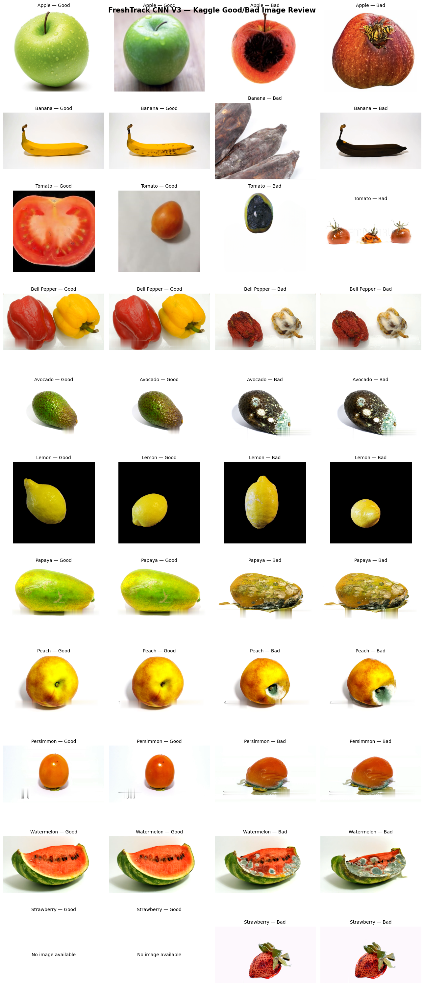


VISUAL REVIEW GENERATED
Inspect whether Good/Bad labels match visible freshness.
Pay particular attention to Apple and Banana.
No dataset labels or image files were modified.


In [110]:

# STEP 26.10 — VISUAL LABEL VERIFICATION

import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import pandas as pd
import random

print("=" * 65)
print("FRESHTRACK — CNN V3 VISUAL LABEL VERIFICATION")
print("=" * 65)

# Use only additional Kaggle images
review_df = v3_additional_mapped.copy()

# Review both original-overlap and new produce types
review_produce = [
    "Apple",
    "Banana",
    "Tomato",
    "Bell Pepper",
    "Avocado",
    "Lemon",
    "Papaya",
    "Peach",
    "Persimmon",
    "Watermelon",
    "Strawberry"
]

random.seed(42)

fig, axes = plt.subplots(
    len(review_produce),
    4,
    figsize=(13, len(review_produce) * 2.8)
)

for row_index, produce in enumerate(review_produce):

    for quality_index, quality in enumerate(
        ["Good", "Bad"]
    ):
        subset = review_df[
            (review_df["produce"] == produce) &
            (review_df["quality"] == quality)
        ]

        samples = subset.sample(
            n=min(2, len(subset)),
            random_state=42
        )

        for sample_index in range(2):

            col_index = quality_index * 2 + sample_index
            ax = axes[row_index, col_index]

            if sample_index < len(samples):
                image_path = samples.iloc[
                    sample_index
                ]["absolute_path"]

                try:
                    with Image.open(image_path) as image:
                        image = ImageOps.exif_transpose(
                            image
                        ).convert("RGB")

                        ax.imshow(image)

                except Exception as error:
                    ax.text(
                        0.5, 0.5,
                        f"Image error:\n{error}",
                        ha="center",
                        va="center",
                        fontsize=8
                    )

            else:
                ax.text(
                    0.5, 0.5,
                    "No image available",
                    ha="center",
                    va="center"
                )

            ax.set_title(
                f"{produce} — {quality}",
                fontsize=10
            )

            ax.axis("off")

plt.suptitle(
    "FreshTrack CNN V3 — Kaggle Good/Bad Image Review",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

print("\nVISUAL REVIEW GENERATED")
print("Inspect whether Good/Bad labels match visible freshness.")
print("Pay particular attention to Apple and Banana.")
print("No dataset labels or image files were modified.")


In [111]:

# STEP 26.11 — PERCEPTUAL HASH AUDIT (ADDITIONAL DATASET)

!pip -q install ImageHash

import imagehash
from PIL import Image, ImageOps
from collections import defaultdict
import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 PERCEPTUAL HASH AUDIT")
print("=" * 65)

def calculate_phash(path):
    try:
        with Image.open(path) as img:
            img = ImageOps.exif_transpose(img).convert("RGB")
            return str(imagehash.phash(img))
    except Exception as error:
        print("Unreadable image:", path, error)
        return None

# Preserve existing dataframes
v3_phash_audit = additional_safe.copy()

print("\nCalculating perceptual hashes...")

v3_phash_audit["phash"] = (
    v3_phash_audit["absolute_path"]
    .apply(calculate_phash)
)

failed = v3_phash_audit["phash"].isna().sum()

print("\nUnreadable images:", failed)

# Group images with identical perceptual hashes
groups = (
    v3_phash_audit.dropna(subset=["phash"])
    .groupby("phash")
    .size()
)

matching_groups = groups[groups > 1]

print("\nIDENTICAL PERCEPTUAL HASHES")
print("-" * 45)
print("Matching hash groups:", len(matching_groups))
print(
    "Additional records sharing a perceptual hash:",
    int((matching_groups - 1).sum())
)

# Identify groups containing different produce/quality labels
label_conflicts = (
    v3_phash_audit.dropna(subset=["phash"])
    .groupby("phash")[["produce", "quality"]]
    .nunique()
)

conflicts = label_conflicts[
    (label_conflicts["produce"] > 1) |
    (label_conflicts["quality"] > 1)
]

print("\nPOTENTIAL LABEL CONFLICTS")
print("-" * 45)
print("Perceptual hash groups with differing labels:",
      len(conflicts))

# Save audit for further review
v3_phash_audit.to_csv(
    REPORT_DIR / "v3_additional_phash_manifest.csv",
    index=False
)

print("\nSAVED: v3_additional_phash_manifest.csv")

print("\nIMPORTANT")
print("Matching perceptual hashes indicate possible similarity.")
print("They are not proof that images are duplicates.")
print("No images have been removed.")

print("\nSTEP 26.11 COMPLETE")


FRESHTRACK — CNN V3 PERCEPTUAL HASH AUDIT

Calculating perceptual hashes...

Unreadable images: 0

IDENTICAL PERCEPTUAL HASHES
---------------------------------------------
Matching hash groups: 499
Additional records sharing a perceptual hash: 6398

POTENTIAL LABEL CONFLICTS
---------------------------------------------
Perceptual hash groups with differing labels: 15

SAVED: v3_additional_phash_manifest.csv

IMPORTANT
Matching perceptual hashes indicate possible similarity.
They are not proof that images are duplicates.
No images have been removed.

STEP 26.11 COMPLETE


FRESHTRACK — CNN V3 PHASH GROUP INVESTIGATION

LARGEST PERCEPTUAL HASH GROUPS
-------------------------------------------------------
phash
b133ce6799cc6498    479
e6e89816899fb29c    252
b0c9c33fce32c91c    219
b896c5699e656994    201
bc87c0688fd1689f    144
b8c9c337c632c93c    105
8fd0f02f4bd4236a    102
af6ac09f35e01a66     96
a7c09c32d99d638d     93
b9c6c23b0e3c4d93     86

CONFLICTING GROUPS
-------------------------------------------------------
Total conflicting groups: 15

Hash: 9c6b6194ca996d27 | Images: 3
produce  quality
Lemon    Bad        2
         Good       1

Hash: cd3032cfcd3067c3 | Images: 2
produce  quality
Lemon    Bad        1
         Good       1

Hash: cf3030cbcb3c3633 | Images: 2
produce  quality
Lemon    Bad        1
         Good       1

Hash: cf3030cfcb3463c3 | Images: 2
produce  quality
Lemon    Bad        1
         Good       1

Hash: cf3030cfcb3c2c33 | Images: 7
produce  quality
Lemon    Bad        1
         Good       6

Hash: cf3030cfcb3c6433 | Imag

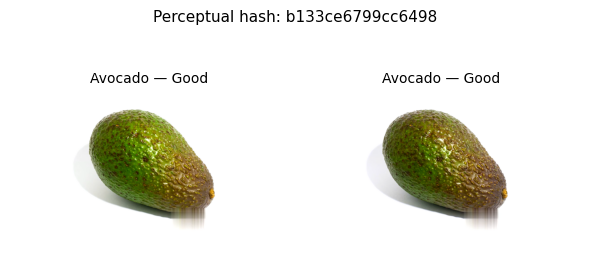

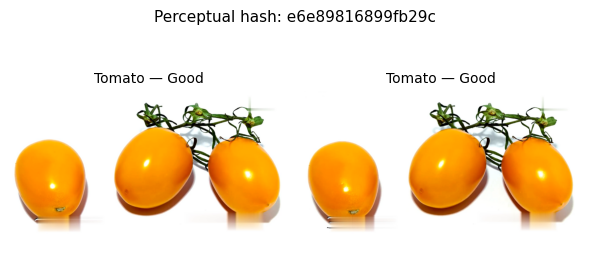

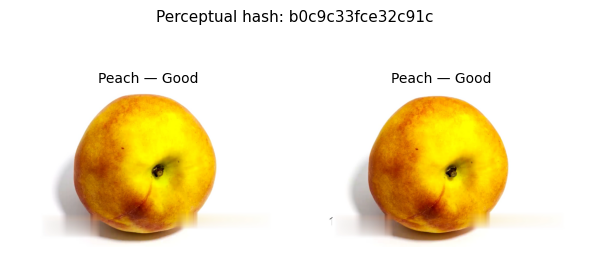


VISUAL REVIEW — CONFLICTING GROUPS
-------------------------------------------------------


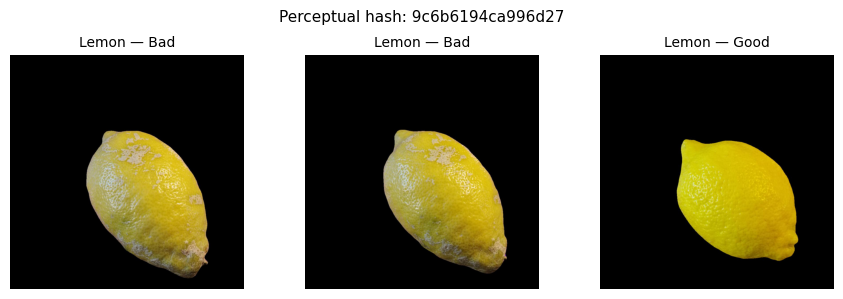

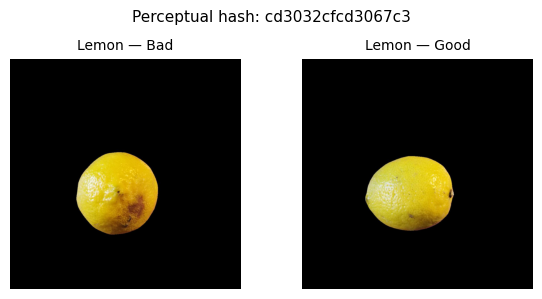

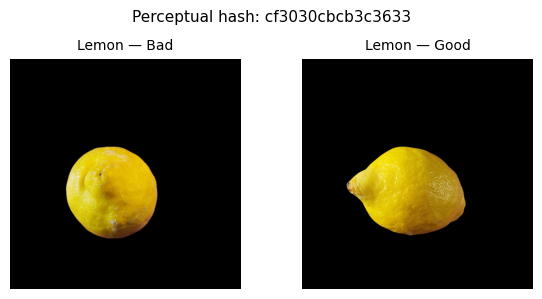

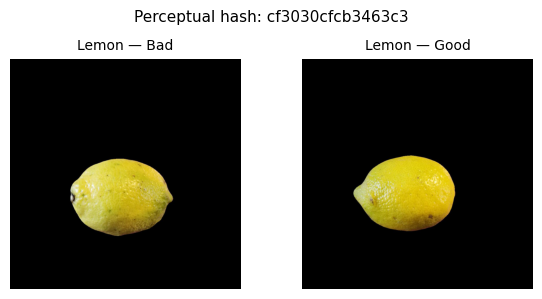

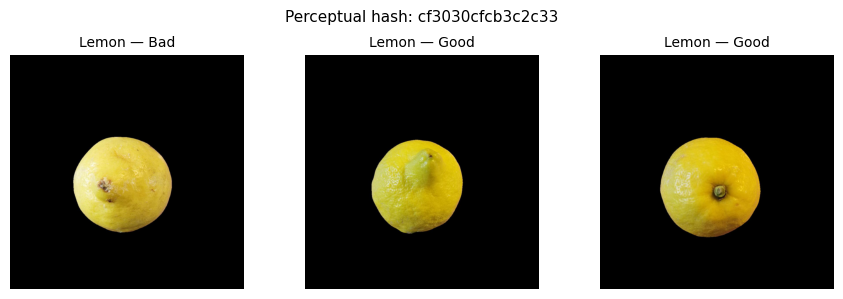


STEP 26.12 COMPLETE
No images or labels were modified.


In [112]:

# STEP 26.12 — INVESTIGATE PERCEPTUAL HASH GROUPS

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

print("=" * 65)
print("FRESHTRACK — CNN V3 PHASH GROUP INVESTIGATION")
print("=" * 65)

assert "phash" in v3_phash_audit.columns

valid = v3_phash_audit.dropna(
    subset=["phash"]
).copy()

# Group sizes
group_sizes = (
    valid.groupby("phash")
    .size()
    .sort_values(ascending=False)
)

# Find perceptual hash groups with conflicting labels
label_counts = (
    valid.groupby("phash")[["produce", "quality"]]
    .nunique()
)

conflicting_hashes = label_counts[
    (label_counts["produce"] > 1) |
    (label_counts["quality"] > 1)
].index.tolist()

print("\nLARGEST PERCEPTUAL HASH GROUPS")
print("-" * 55)

print(group_sizes.head(10).to_string())

print("\nCONFLICTING GROUPS")
print("-" * 55)

print("Total conflicting groups:", len(conflicting_hashes))

for phash in conflicting_hashes[:10]:
    group = valid[valid["phash"] == phash]

    print(
        f"\nHash: {phash} | "
        f"Images: {len(group)}"
    )

    print(
        group.groupby(["produce", "quality"])
        .size()
        .to_string()
    )

def display_hash_group(hash_value, max_images=8):
    group = valid[
        valid["phash"] == hash_value
    ]

    # Show representative images from different labels first
    selected = (
        group.groupby(
            ["produce", "quality"],
            group_keys=False
        )
        .head(2)
        .head(max_images)
    )

    fig, axes = plt.subplots(
        1, len(selected),
        figsize=(3 * len(selected), 3)
    )

    if len(selected) == 1:
        axes = [axes]

    for ax, (_, row) in zip(
        axes, selected.iterrows()
    ):
        with Image.open(row["absolute_path"]) as img:
            img = ImageOps.exif_transpose(
                img
            ).convert("RGB")

            ax.imshow(img)

        ax.set_title(
            f'{row["produce"]} — {row["quality"]}',
            fontsize=10
        )
        ax.axis("off")

    plt.suptitle(
        f"Perceptual hash: {hash_value}",
        fontsize=11
    )

    plt.tight_layout()
    plt.show()

print("\nVISUAL REVIEW — LARGEST GROUPS")
print("-" * 55)

for hash_value in group_sizes.head(3).index:
    display_hash_group(hash_value)

print("\nVISUAL REVIEW — CONFLICTING GROUPS")
print("-" * 55)

for hash_value in conflicting_hashes[:5]:
    display_hash_group(hash_value)

print("\nSTEP 26.12 COMPLETE")
print("No images or labels were modified.")


In [113]:

# STEP 26.13 — SECONDARY HASH VERIFICATION

import imagehash
import pandas as pd
from PIL import Image, ImageOps

print("=" * 65)
print("FRESHTRACK — CNN V3 SECONDARY HASH VERIFICATION")
print("=" * 65)

# Only inspect groups with matching pHash values
phash_counts = v3_phash_audit["phash"].value_counts()

candidate_hashes = set(
    phash_counts[phash_counts > 1].index
)

candidates = v3_phash_audit[
    v3_phash_audit["phash"].isin(candidate_hashes)
].copy()

print("\nCandidate images:", len(candidates))

def calculate_dhash(path):
    try:
        with Image.open(path) as img:
            img = ImageOps.exif_transpose(img).convert("RGB")
            return str(imagehash.dhash(img))
    except Exception:
        return None

print("\nCalculating secondary hashes...")

candidates["dhash"] = (
    candidates["absolute_path"]
    .apply(calculate_dhash)
)

print("Unreadable images:",
      candidates["dhash"].isna().sum())

# Require BOTH perceptual hashes to match exactly
secondary_groups = (
    candidates.dropna(subset=["dhash"])
    .groupby(["phash", "dhash"])
    .size()
)

strong_groups = secondary_groups[
    secondary_groups > 1
]

print("\nDUAL-HASH MATCHES")
print("-" * 45)

print("Matching groups:", len(strong_groups))
print(
    "Extra records sharing both hashes:",
    int((strong_groups - 1).sum())
)

# Check label consistency within dual-hash groups
label_counts = (
    candidates.dropna(subset=["dhash"])
    .groupby(["phash", "dhash"])[["produce", "quality"]]
    .nunique()
)

conflicting_groups = label_counts[
    (label_counts["produce"] > 1) |
    (label_counts["quality"] > 1)
]

print("\nPOTENTIAL LABEL CONFLICTS")
print("-" * 45)

print(
    "Dual-hash groups with conflicting labels:",
    len(conflicting_groups)
)

# Save secondary audit
candidates.to_csv(
    REPORT_DIR / "v3_secondary_hash_candidates.csv",
    index=False
)

print("\nSAVED: v3_secondary_hash_candidates.csv")
print("\nNo images were deleted or relabelled.")
print("\nSTEP 26.13 COMPLETE")


FRESHTRACK — CNN V3 SECONDARY HASH VERIFICATION

Candidate images: 6897

Calculating secondary hashes...
Unreadable images: 0

DUAL-HASH MATCHES
---------------------------------------------
Matching groups: 678
Extra records sharing both hashes: 5576

POTENTIAL LABEL CONFLICTS
---------------------------------------------
Dual-hash groups with conflicting labels: 0

SAVED: v3_secondary_hash_candidates.csv

No images were deleted or relabelled.

STEP 26.13 COMPLETE


FRESHTRACK — CNN V3 DUAL-HASH VISUAL REVIEW

TOP 10 DUAL-HASH GROUPS
-------------------------------------------------------
phash             dhash           
b133ce6799cc6498  009d9d9e9e060600    369
b0c9c33fce32c91c  4d9e9636361e1f1d    187
e6e89816899fb29c  4b034543454d6962     99
b8c9c337c632c93c  0d969636361e1f1d     98
b133ce6799cc6498  009d9d9e8e060600     89
ef6ac09735e01a66  104103071e396218     84
b8c6c33b0e3cc593  b0d8323733331b18     66
af6ac09f35e01a66  104103071e796218     62
b0c9c337ce32c93c  4d9e9636361e1f1d     59
8fd0f02f4bd4236a  0028836969690029     58

REPETITION BY PRODUCE TYPE
-------------------------------------------------------
             matching_records  matching_groups
produce                                       
Tomato                   1463               92
Peach                     976               54
Persimmon                 853               38
Bell Pepper               689               36
Avocado                   590                5
Papaya 

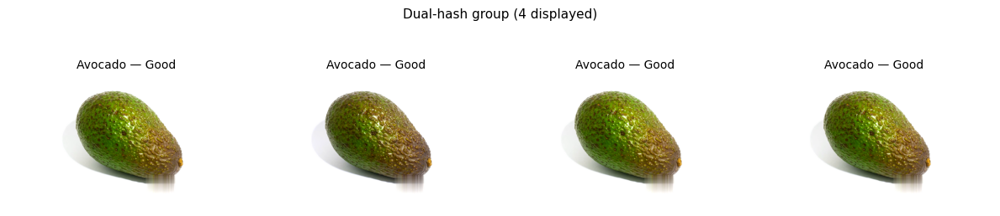

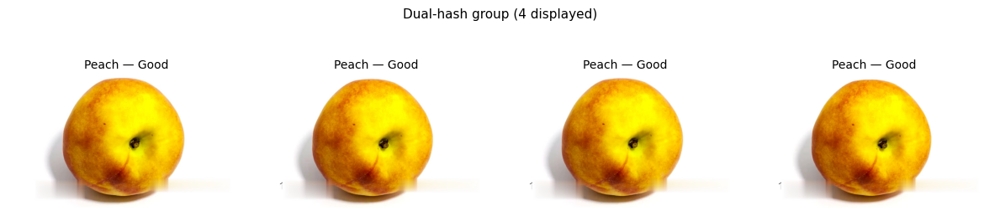

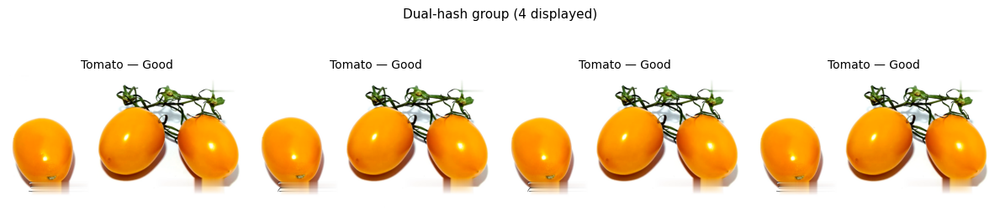

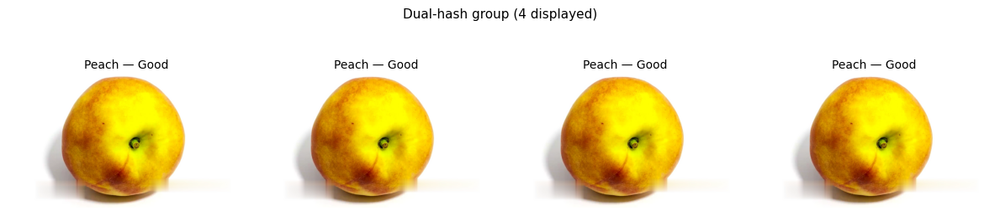

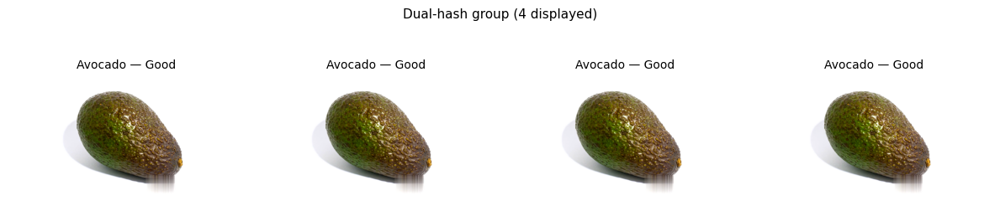


STEP 26.14 COMPLETE
No images or labels were modified.


In [114]:

# STEP 26.14 — DUAL-HASH DUPLICATE VISUAL REVIEW

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

print("=" * 65)
print("FRESHTRACK — CNN V3 DUAL-HASH VISUAL REVIEW")
print("=" * 65)

valid = candidates.dropna(
    subset=["phash", "dhash"]
).copy()

group_sizes = (
    valid.groupby(["phash", "dhash"])
    .size()
    .sort_values(ascending=False)
)

repeated_groups = group_sizes[group_sizes > 1]

print("\nTOP 10 DUAL-HASH GROUPS")
print("-" * 55)
print(repeated_groups.head(10).to_string())

# Count extra matching records by produce type
valid["group_size"] = (
    valid.groupby(["phash", "dhash"])["sha256"]
    .transform("size")
)

repeated = valid[valid["group_size"] > 1].copy()

produce_summary = (
    repeated.groupby("produce")
    .agg(
        matching_records=("sha256", "size"),
        matching_groups=("phash", "nunique")
    )
    .sort_values("matching_records", ascending=False)
)

print("\nREPETITION BY PRODUCE TYPE")
print("-" * 55)
print(produce_summary.to_string())

def show_dual_hash_group(group_key, max_images=4):
    phash_value, dhash_value = group_key

    group = valid[
        (valid["phash"] == phash_value) &
        (valid["dhash"] == dhash_value)
    ].head(max_images)

    fig, axes = plt.subplots(
        1, len(group),
        figsize=(3 * len(group), 3)
    )

    if len(group) == 1:
        axes = [axes]

    for ax, (_, row) in zip(
        axes, group.iterrows()
    ):
        with Image.open(row["absolute_path"]) as img:
            img = ImageOps.exif_transpose(
                img
            ).convert("RGB")
            ax.imshow(img)

        ax.set_title(
            f'{row["produce"]} — {row["quality"]}',
            fontsize=10
        )
        ax.axis("off")

    plt.suptitle(
        f"Dual-hash group ({len(group)} displayed)",
        fontsize=11
    )
    plt.tight_layout()
    plt.show()

print("\nVISUAL REVIEW — FIVE LARGEST GROUPS")
print("-" * 55)

for group_key in repeated_groups.head(5).index:
    show_dual_hash_group(group_key)

print("\nSTEP 26.14 COMPLETE")
print("No images or labels were modified.")


In [115]:

# STEP 26.15 — PIXEL-LEVEL NEAR-DUPLICATE VERIFICATION

import numpy as np
import pandas as pd
from PIL import Image, ImageOps

print("=" * 65)
print("FRESHTRACK — CNN V3 PIXEL SIMILARITY AUDIT")
print("=" * 65)

# Reuse dual-hash candidates from Step 26.13
audit_df = candidates.dropna(
    subset=["phash", "dhash"]
).copy()

def image_vector(path, size=(128, 128)):
    with Image.open(path) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
        img = img.resize(size)

        return np.asarray(img, dtype=np.float32) / 255.0

def pixel_similarity(image_a, image_b):
    # Mean absolute pixel difference converted to similarity
    difference = np.mean(
        np.abs(image_a - image_b)
    )
    return 1.0 - float(difference)

similarity_records = []

groups = audit_df.groupby(["phash", "dhash"])

for group_key, group in groups:

    if len(group) < 2:
        continue

    reference = group.iloc[0]
    reference_vector = image_vector(
        reference["absolute_path"]
    )

    for _, row in group.iloc[1:].iterrows():

        comparison_vector = image_vector(
            row["absolute_path"]
        )

        similarity = pixel_similarity(
            reference_vector,
            comparison_vector
        )

        similarity_records.append({
            "phash": group_key[0],
            "dhash": group_key[1],
            "reference_path": reference["absolute_path"],
            "comparison_path": row["absolute_path"],
            "produce": row["produce"],
            "quality": row["quality"],
            "similarity": similarity
        })

similarity_df = pd.DataFrame(similarity_records)

print("\nTOTAL PAIRS COMPARED:", len(similarity_df))

if similarity_df.empty:
    print("No matching groups to compare.")
else:
    print("\nPIXEL SIMILARITY DISTRIBUTION")
    print("-" * 45)

    print(
        similarity_df["similarity"]
        .describe()
        .to_string()
    )

    print("\nHIGH-SIMILARITY CANDIDATES")
    print("-" * 45)

    for threshold in [0.99, 0.995, 0.999]:
        count = (
            similarity_df["similarity"] >= threshold
        ).sum()

        print(
            f"Similarity >= {threshold}: {count}"
        )

    print("\nHIGH-SIMILARITY COUNTS BY PRODUCE")

    high_similarity = similarity_df[
        similarity_df["similarity"] >= 0.995
    ]

    print(
        high_similarity["produce"]
        .value_counts()
        .to_string()
    )

    similarity_df.to_csv(
        REPORT_DIR / "v3_pixel_similarity_audit.csv",
        index=False
    )

    print("\nSAVED: v3_pixel_similarity_audit.csv")

print("\nSTEP 26.15 COMPLETE")
print("No images were deleted or relabelled.")


FRESHTRACK — CNN V3 PIXEL SIMILARITY AUDIT

TOTAL PAIRS COMPARED: 5576

PIXEL SIMILARITY DISTRIBUTION
---------------------------------------------
count    5576.000000
mean        0.996239
std         0.003515
min         0.969330
25%         0.994801
50%         0.997368
75%         0.998729
max         1.000000

HIGH-SIMILARITY CANDIDATES
---------------------------------------------
Similarity >= 0.99: 5211
Similarity >= 0.995: 4107
Similarity >= 0.999: 1016

HIGH-SIMILARITY COUNTS BY PRODUCE
produce
Tomato         910
Persimmon      756
Peach          662
Bell Pepper    430
Papaya         410
Avocado        374
Banana         230
Cucumber       220
Strawberry      66
Watermelon      45
Apple            3
Lemon            1

SAVED: v3_pixel_similarity_audit.csv

STEP 26.15 COMPLETE
No images were deleted or relabelled.


In [116]:

# STEP 26.16 — CONSERVATIVE NEAR-DUPLICATE REVIEW MANIFEST

import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 NEAR-DUPLICATE REVIEW")
print("=" * 65)

SIMILARITY_THRESHOLD = 0.995

# Preserve the complete additional dataset
v3_review_manifest = additional_safe.copy()

# Find high-similarity comparison paths
high_similarity_pairs = similarity_df[
    similarity_df["similarity"] >= SIMILARITY_THRESHOLD
].copy()

flagged_paths = set(
    high_similarity_pairs["comparison_path"]
)

v3_review_manifest["near_duplicate_candidate"] = (
    v3_review_manifest["absolute_path"]
    .isin(flagged_paths)
)

# Provisional retained pool — NOT final training data
v3_provisional_retained = v3_review_manifest[
    ~v3_review_manifest["near_duplicate_candidate"]
].copy()

v3_flagged_for_review = v3_review_manifest[
    v3_review_manifest["near_duplicate_candidate"]
].copy()

print("\nNEAR-DUPLICATE REVIEW")
print("-" * 50)

print("Starting additional images:",
      len(v3_review_manifest))

print("Flagged for review:",
      len(v3_flagged_for_review))

print("Provisionally retained:",
      len(v3_provisional_retained))

print("\nFLAGGED IMAGES BY PRODUCE")
print("-" * 50)

print(
    v3_flagged_for_review["produce"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nPROVISIONALLY RETAINED CLASS DISTRIBUTION")
print("-" * 50)

distribution = pd.crosstab(
    v3_provisional_retained["produce"],
    v3_provisional_retained["quality"]
)

print(distribution.to_string())

print("\nORIGINAL TRAINING IMAGES:",
      len(original_train))

print(
    "PROVISIONAL COMBINED TRAINING CANDIDATES:",
    len(original_train) + len(v3_provisional_retained)
)

# Save review reports without moving images
v3_review_manifest.to_csv(
    REPORT_DIR / "v3_near_duplicate_review_manifest.csv",
    index=False
)

v3_flagged_for_review.to_csv(
    REPORT_DIR / "v3_near_duplicate_flagged.csv",
    index=False
)

print("\nREPORTS SAVED")
print("-" * 50)
print("v3_near_duplicate_review_manifest.csv")
print("v3_near_duplicate_flagged.csv")

print("\nIMPORTANT")
print("Flagged images have NOT been deleted.")
print("This is NOT the final CNN V3 training dataset.")
print("Protected validation/test leakage checks remain.")

print("\nSTEP 26.16 COMPLETE")


FRESHTRACK — CNN V3 NEAR-DUPLICATE REVIEW

NEAR-DUPLICATE REVIEW
--------------------------------------------------
Starting additional images: 12157
Flagged for review: 4107
Provisionally retained: 8050

FLAGGED IMAGES BY PRODUCE
--------------------------------------------------
produce
Apple            3
Avocado        374
Banana         230
Bell Pepper    430
Cucumber       220
Lemon            1
Papaya         410
Peach          662
Persimmon      756
Strawberry      66
Tomato         910
Watermelon      45

PROVISIONALLY RETAINED CLASS DISTRIBUTION
--------------------------------------------------
quality       Bad  Good
produce                
Apple         425   182
Avocado        35   195
Banana        550   269
Bell Pepper   270     8
Cucumber       31   115
Lemon        1237   954
Orange        199   163
Papaya        110    23
Peach         242   105
Persimmon      62    67
Strawberry     31     0
Tomato       1839   782
Watermelon    120    36

ORIGINAL TRAINING IMAGES: 8

In [117]:

# STEP 26.17 — CROSS-DATASET NEAR-DUPLICATE LEAKAGE AUDIT

import pandas as pd
import imagehash
from PIL import Image, ImageOps
from collections import defaultdict

print("=" * 65)
print("FRESHTRACK — CNN V3 VALIDATION/TEST LEAKAGE AUDIT")
print("=" * 65)

# Protect original validation and test sets
protected_df = pd.concat(
    [original_val, original_test],
    ignore_index=True
).copy()

def get_phash(path):
    with Image.open(path) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
        return str(imagehash.phash(img))

def get_dhash(path):
    with Image.open(path) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
        return str(imagehash.dhash(img))

print("\nHashing protected validation/test images...")

protected_df["phash"] = (
    protected_df["absolute_path"].apply(get_phash)
)

protected_df["dhash"] = (
    protected_df["absolute_path"].apply(get_dhash)
)

print("Protected images:", len(protected_df))

# Reuse additional dataset perceptual hashes
additional_check = v3_phash_audit.copy()

# Calculate dHash for all additional images
print("\nHashing additional images...")

additional_check["dhash"] = (
    additional_check["absolute_path"].apply(get_dhash)
)

# Identify exact dual-hash matches
protected_keys = set(
    zip(protected_df["phash"], protected_df["dhash"])
)

additional_check["protected_dual_hash_match"] = [
    (ph, dh) in protected_keys
    for ph, dh in zip(
        additional_check["phash"],
        additional_check["dhash"]
    )
]

matches = additional_check[
    additional_check["protected_dual_hash_match"]
].copy()

print("\nCROSS-DATASET HASH SCREENING")
print("-" * 50)

print("Additional images checked:",
      len(additional_check))

print("Protected images checked:",
      len(protected_df))

print("Additional images sharing both hashes:",
      len(matches))

print("\nMATCHES BY PRODUCE")
print("-" * 50)

if matches.empty:
    print("No exact dual-hash matches found.")
else:
    print(
        matches["produce"]
        .value_counts()
        .to_string()
    )

# Save reports
protected_df.to_csv(
    REPORT_DIR / "v3_protected_split_hashes.csv",
    index=False
)

matches.to_csv(
    REPORT_DIR / "v3_protected_dual_hash_matches.csv",
    index=False
)

print("\nREPORTS SAVED")
print("-" * 50)
print("v3_protected_split_hashes.csv")
print("v3_protected_dual_hash_matches.csv")

print("\nIMPORTANT")
print("Dual-hash matches are screening candidates.")
print("No files or labels were modified.")
print("A zero-match result does not rule out all near-duplicates.")

print("\nSTEP 26.17 COMPLETE")


FRESHTRACK — CNN V3 VALIDATION/TEST LEAKAGE AUDIT

Hashing protected validation/test images...
Protected images: 3530

Hashing additional images...

CROSS-DATASET HASH SCREENING
--------------------------------------------------
Additional images checked: 12157
Protected images checked: 3530
Additional images sharing both hashes: 14

MATCHES BY PRODUCE
--------------------------------------------------
produce
Orange    6
Apple     6
Banana    2

REPORTS SAVED
--------------------------------------------------
v3_protected_split_hashes.csv
v3_protected_dual_hash_matches.csv

IMPORTANT
Dual-hash matches are screening candidates.
No files or labels were modified.
A zero-match result does not rule out all near-duplicates.

STEP 26.17 COMPLETE


FRESHTRACK — CNN V3 PROTECTED MATCH VERIFICATION

MATCHED PAIRS: 14
UNIQUE ADDITIONAL IMAGES: 14

PIXEL SIMILARITY
--------------------------------------------------
count    14.000000
mean      0.996924
std       0.001269
min       0.995961
25%       0.996259
50%       0.996390
75%       0.996508
max       0.999413

MATCHES BY PROTECTED SPLIT
--------------------------------------------------
split
validation    7
test          7

MATCH DETAILS
--------------------------------------------------
produce quality               label      split  pixel_similarity
 Orange     Bad Fruits/RottenOrange validation          0.996246
 Orange     Bad Fruits/RottenOrange       test          0.996024
 Orange     Bad Fruits/RottenOrange       test          0.995961
 Orange     Bad Fruits/RottenOrange validation          0.996330
 Orange     Bad Fruits/RottenOrange       test          0.996499
 Orange     Bad Fruits/RottenOrange validation          0.996144
  Apple     Bad  Fruits/RottenApple       te

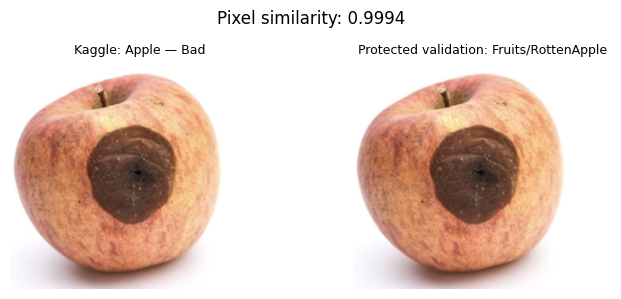

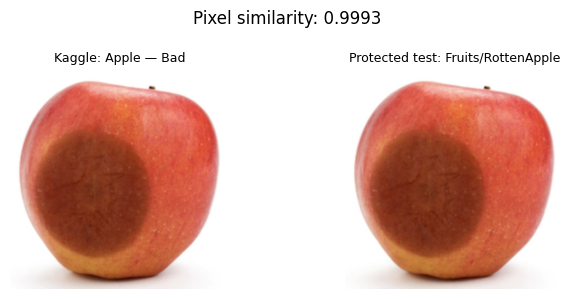

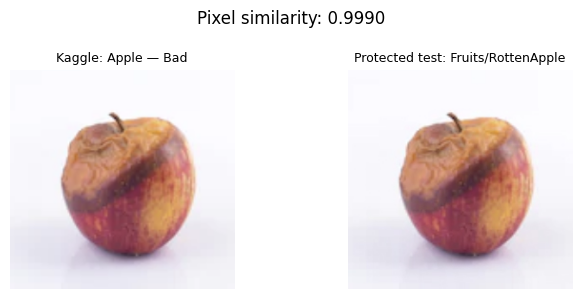

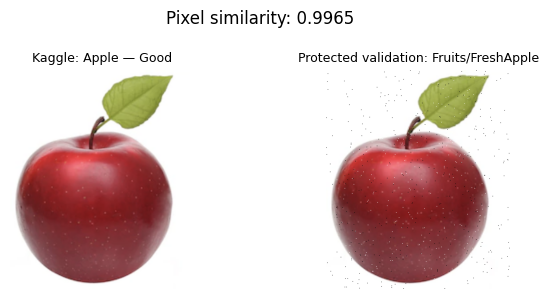

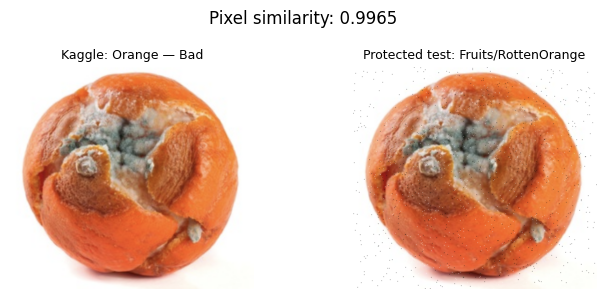

...

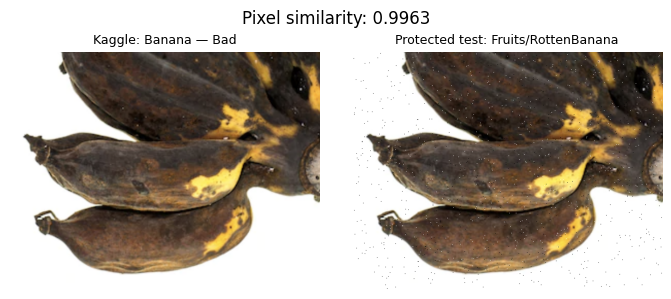

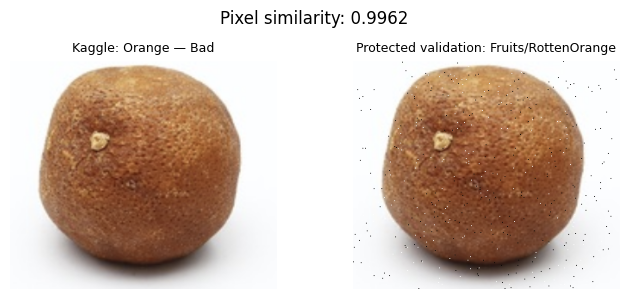

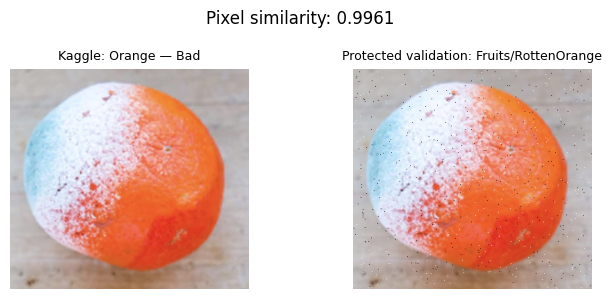

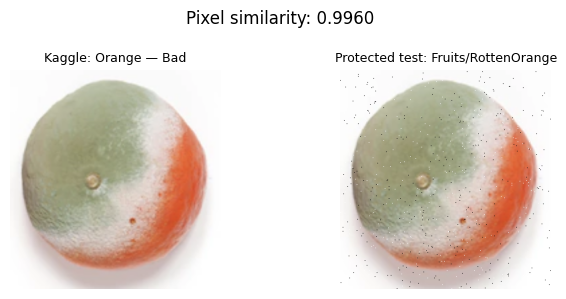

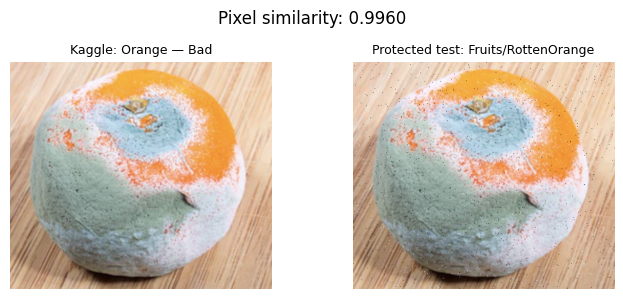


SAVED: v3_protected_match_verification.csv
No images were removed or relabelled.

STEP 26.18 COMPLETE


In [118]:

# STEP 26.18 — REVIEW PROTECTED-SPLIT IMAGE MATCHES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

print("=" * 65)
print("FRESHTRACK — CNN V3 PROTECTED MATCH VERIFICATION")
print("=" * 65)

def image_array(path, size=(128, 128)):
    with Image.open(path) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
        img = img.resize(size)
        return np.asarray(img, dtype=np.float32) / 255.0

# Pair each additional match with protected images
paired = matches.merge(
    protected_df[
        ["absolute_path", "label", "split", "phash", "dhash"]
    ],
    on=["phash", "dhash"],
    how="inner",
    suffixes=("_additional", "_protected")
)

# Calculate pixel similarity for every matched pair
def compare_pair(row):
    a = image_array(row["absolute_path_additional"])
    b = image_array(row["absolute_path_protected"])
    return 1.0 - float(np.mean(np.abs(a - b)))

paired["pixel_similarity"] = paired.apply(
    compare_pair,
    axis=1
)

print("\nMATCHED PAIRS:", len(paired))
print("UNIQUE ADDITIONAL IMAGES:",
      paired["absolute_path_additional"].nunique())

print("\nPIXEL SIMILARITY")
print("-" * 50)
print(paired["pixel_similarity"].describe().to_string())

print("\nMATCHES BY PROTECTED SPLIT")
print("-" * 50)
print(paired["split"].value_counts().to_string())

print("\nMATCH DETAILS")
print("-" * 50)

print(
    paired[
        ["produce", "quality", "label",
         "split", "pixel_similarity"]
    ].to_string(index=False)
)

# Display a representative protected match for each additional image
visual_pairs = (
    paired.sort_values(
        "pixel_similarity",
        ascending=False
    )
    .drop_duplicates("absolute_path_additional")
)

for _, row in visual_pairs.iterrows():

    fig, axes = plt.subplots(1, 2, figsize=(7, 3))

    for ax, path, title in [
        (
            axes[0],
            row["absolute_path_additional"],
            f'Kaggle: {row["produce"]} — {row["quality"]}'
        ),
        (
            axes[1],
            row["absolute_path_protected"],
            f'Protected {row["split"]}: {row["label"]}'
        )
    ]:
        with Image.open(path) as img:
            ax.imshow(
                ImageOps.exif_transpose(img).convert("RGB")
            )

        ax.set_title(title, fontsize=9)
        ax.axis("off")

    plt.suptitle(
        f'Pixel similarity: {row["pixel_similarity"]:.4f}'
    )
    plt.tight_layout()
    plt.show()

# Save report
paired.to_csv(
    REPORT_DIR / "v3_protected_match_verification.csv",
    index=False
)

print("\nSAVED: v3_protected_match_verification.csv")
print("No images were removed or relabelled.")
print("\nSTEP 26.18 COMPLETE")


In [119]:

# STEP 26.19 — BROADER PROTECTED-SPLIT SIMILARITY SCREEN

import numpy as np
import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 BROADER LEAKAGE SCREEN")
print("=" * 65)

# Work with existing hashes from Step 26.17
additional_screen = additional_check.copy()
protected_screen = protected_df.copy()

# Convert hexadecimal pHashes into integers
additional_hashes = [
    int(value, 16)
    for value in additional_screen["phash"]
]

protected_hashes = [
    int(value, 16)
    for value in protected_screen["phash"]
]

MAX_PHASH_DISTANCE = 4

near_matches = []

print("\nComparing additional images against protected splits...")

for additional_index, additional_hash in enumerate(
    additional_hashes
):
    for protected_index, protected_hash in enumerate(
        protected_hashes
    ):
        distance = (
            additional_hash ^ protected_hash
        ).bit_count()

        if distance <= MAX_PHASH_DISTANCE:
            near_matches.append({
                "additional_path":
                    additional_screen.iloc[additional_index]["absolute_path"],
                "additional_produce":
                    additional_screen.iloc[additional_index]["produce"],
                "additional_quality":
                    additional_screen.iloc[additional_index]["quality"],
                "protected_path":
                    protected_screen.iloc[protected_index]["absolute_path"],
                "protected_label":
                    protected_screen.iloc[protected_index]["label"],
                "protected_split":
                    protected_screen.iloc[protected_index]["split"],
                "phash_distance": distance
            })

near_matches_df = pd.DataFrame(near_matches)

print("\nSCREENING RESULTS")
print("-" * 50)

print("Additional images checked:", len(additional_screen))
print("Protected images checked:", len(protected_screen))
print("Potential matching pairs:", len(near_matches_df))

if not near_matches_df.empty:
    print(
        "Unique additional images flagged:",
        near_matches_df["additional_path"].nunique()
    )

    print("\nMATCHES BY PHASH DISTANCE")
    print(
        near_matches_df["phash_distance"]
        .value_counts()
        .sort_index()
        .to_string()
    )

    print("\nMATCHES BY PROTECTED SPLIT")
    print(
        near_matches_df["protected_split"]
        .value_counts()
        .to_string()
    )

near_matches_df.to_csv(
    REPORT_DIR / "v3_broader_protected_similarity_screen.csv",
    index=False
)

print("\nSAVED: v3_broader_protected_similarity_screen.csv")
print("No images were removed.")
print("\nSTEP 26.19 COMPLETE")


FRESHTRACK — CNN V3 BROADER LEAKAGE SCREEN

Comparing additional images against protected splits...

SCREENING RESULTS
--------------------------------------------------
Additional images checked: 12157
Protected images checked: 3530
Potential matching pairs: 53
Unique additional images flagged: 53

MATCHES BY PHASH DISTANCE
phash_distance
0    39
2    11
4     3

MATCHES BY PROTECTED SPLIT
protected_split
test          27
validation    26

SAVED: v3_broader_protected_similarity_screen.csv
No images were removed.

STEP 26.19 COMPLETE


In [120]:

# STEP 26.20 — VERIFY BROADER PROTECTED-SPLIT MATCHES

import numpy as np
import pandas as pd
from PIL import Image, ImageOps

print("=" * 65)
print("FRESHTRACK — CNN V3 BROADER MATCH VERIFICATION")
print("=" * 65)

assert len(near_matches_df) > 0, (
    "No candidate matches found in Step 26.19."
)

def comparison_image(path, size=(128, 128)):
    with Image.open(path) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
        img = img.resize(size, Image.Resampling.LANCZOS)

        return np.asarray(
            img, dtype=np.float32
        ) / 255.0

def calculate_similarity(row):
    additional = comparison_image(
        row["additional_path"]
    )

    protected = comparison_image(
        row["protected_path"]
    )

    return 1.0 - float(
        np.mean(np.abs(additional - protected))
    )

v3_broader_verified = near_matches_df.copy()

v3_broader_verified["pixel_similarity"] = (
    v3_broader_verified.apply(
        calculate_similarity,
        axis=1
    )
)

print("\nPIXEL SIMILARITY DISTRIBUTION")
print("-" * 50)

print(
    v3_broader_verified["pixel_similarity"]
    .describe()
    .to_string()
)

print("\nSIMILARITY THRESHOLDS")
print("-" * 50)

for threshold in [0.95, 0.98, 0.99, 0.995]:
    count = (
        v3_broader_verified["pixel_similarity"]
        >= threshold
    ).sum()

    print(f"Similarity >= {threshold}: {count}")

print("\nMATCHES BY PHASH DISTANCE")
print("-" * 50)

print(
    v3_broader_verified.groupby("phash_distance")[
        "pixel_similarity"
    ].agg(["count", "min", "mean", "max"])
    .to_string()
)

print("\nMATCH DETAILS")
print("-" * 50)

print(
    v3_broader_verified[
        [
            "additional_produce",
            "additional_quality",
            "protected_label",
            "protected_split",
            "phash_distance",
            "pixel_similarity"
        ]
    ].sort_values(
        "pixel_similarity",
        ascending=False
    ).to_string(index=False)
)

v3_broader_verified.to_csv(
    REPORT_DIR / "v3_broader_match_verification.csv",
    index=False
)

print("\nSAVED: v3_broader_match_verification.csv")
print("No images were removed or relabelled.")
print("\nSTEP 26.20 COMPLETE")


FRESHTRACK — CNN V3 BROADER MATCH VERIFICATION

PIXEL SIMILARITY DISTRIBUTION
--------------------------------------------------
count    53.000000
mean      0.984387
std       0.060135
min       0.582859
25%       0.995011
50%       0.995333
75%       0.995589
max       0.999358

SIMILARITY THRESHOLDS
--------------------------------------------------
Similarity >= 0.95: 51
Similarity >= 0.98: 50
Similarity >= 0.99: 50
Similarity >= 0.995: 41

MATCHES BY PHASH DISTANCE
--------------------------------------------------
                count       min      mean       max
phash_distance                                     
0                  39  0.994759  0.995659  0.999358
2                  11  0.993978  0.995094  0.995821
4                   3  0.582859  0.798596  0.971328

MATCH DETAILS
--------------------------------------------------
additional_produce additional_quality         protected_label protected_split  phash_distance  pixel_similarity
             Apple                Ba

In [121]:

# STEP 26.21 — PROTECTED-SPLIT EXCLUSION MANIFEST

import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 LEAKAGE EXCLUSION MANIFEST")
print("=" * 65)

verified = v3_broader_verified.copy()

# Translate Kaggle Good/Bad into the existing class terminology
verified["expected_freshness"] = verified[
    "additional_quality"
].map({
    "Good": "Fresh",
    "Bad": "Rotten"
})

# Existing labels use formats such as:
# Fruits/FreshApple or Vegetables/RottenTomato
verified["label_agrees"] = verified.apply(
    lambda row: (
        isinstance(row["protected_label"], str)
        and row["protected_label"].split("/")[-1]
        == (
            row["expected_freshness"]
            + row["additional_produce"].replace(" ", "")
        )
    ),
    axis=1
)

# Conservative high-confidence leakage rule
verified["high_confidence_leakage"] = (
    (verified["phash_distance"] <= 2)
    & (verified["pixel_similarity"] >= 0.99)
    & verified["label_agrees"]
)

# Keep ambiguous matches separate for manual inspection
verified["manual_review_required"] = (
    ~verified["high_confidence_leakage"]
)

high_confidence = verified[
    verified["high_confidence_leakage"]
].copy()

manual_review = verified[
    verified["manual_review_required"]
].copy()

# Deduplicate by additional-image path
excluded_paths = set(
    high_confidence["additional_path"]
)

# Create a leakage-safe additional pool for the matches
# identified by this screening method.
v3_leakage_screened = additional_safe[
    ~additional_safe["absolute_path"].isin(excluded_paths)
].copy()

print("\nEXCLUSION SUMMARY")
print("-" * 50)

print("Additional images before screening:",
      len(additional_safe))

print("High-confidence matching pairs:",
      len(high_confidence))

print("Unique additional images flagged:",
      len(excluded_paths))

print("Ambiguous pairs requiring manual review:",
      len(manual_review))

print("Additional images after exclusions:",
      len(v3_leakage_screened))

print("\nHIGH-CONFIDENCE FLAGS BY PRODUCE")
print("-" * 50)

if high_confidence.empty:
    print("None")
else:
    print(
        high_confidence["additional_produce"]
        .value_counts()
        .to_string()
    )

print("\nAMBIGUOUS PAIRS")
print("-" * 50)

if manual_review.empty:
    print("None")
else:
    print(
        manual_review[
            [
                "additional_produce",
                "additional_quality",
                "protected_label",
                "phash_distance",
                "pixel_similarity",
                "label_agrees"
            ]
        ].to_string(index=False)
    )

# Save audit evidence
verified.to_csv(
    REPORT_DIR / "v3_leakage_decision_manifest.csv",
    index=False
)

high_confidence.to_csv(
    REPORT_DIR / "v3_high_confidence_leakage.csv",
    index=False
)

manual_review.to_csv(
    REPORT_DIR / "v3_ambiguous_leakage_review.csv",
    index=False
)

v3_leakage_screened.to_csv(
    REPORT_DIR / "v3_leakage_screened_additional.csv",
    index=False
)

print("\nREPORTS SAVED")
print("-" * 50)
print("v3_leakage_decision_manifest.csv")
print("v3_high_confidence_leakage.csv")
print("v3_ambiguous_leakage_review.csv")
print("v3_leakage_screened_additional.csv")

print("\nIMPORTANT")
print("Original validation/test sets remain unchanged.")
print("No source images were deleted.")
print("This is not yet the final training dataset.")
print("Broader leakage and internal duplication checks remain.")

print("\nSTEP 26.21 COMPLETE")


FRESHTRACK — CNN V3 LEAKAGE EXCLUSION MANIFEST

EXCLUSION SUMMARY
--------------------------------------------------
Additional images before screening: 12157
High-confidence matching pairs: 50
Unique additional images flagged: 50
Ambiguous pairs requiring manual review: 3
Additional images after exclusions: 12107

HIGH-CONFIDENCE FLAGS BY PRODUCE
--------------------------------------------------
additional_produce
Orange    23
Apple     19
Banana     8

AMBIGUOUS PAIRS
--------------------------------------------------
additional_produce additional_quality         protected_label  phash_distance  pixel_similarity  label_agrees
            Orange                Bad Vegetables/RottenTomato               4          0.841602         False
             Apple                Bad      Fruits/RottenApple               4          0.971328          True
            Tomato                Bad Fruits/RottenStrawberry               4          0.582859         False

REPORTS SAVED
------------------

In [122]:

# STEP 26.22 — ORIGINAL TRAIN VS PROTECTED SPLIT LEAKAGE SCREEN

import numpy as np
import pandas as pd
import imagehash
from PIL import Image, ImageOps
from sklearn.neighbors import NearestNeighbors

print("=" * 65)
print("FRESHTRACK — CNN V3 ORIGINAL DATASET LEAKAGE SCREEN")
print("=" * 65)

MAX_PHASH_DISTANCE = 4

# Keep the original training and protected sets unchanged
original_training_screen = original_train.copy()
protected_screen = protected_df.copy()

def compute_phash(path):
    with Image.open(path) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
        return str(imagehash.phash(img))

print("\nHashing original training images...")

original_training_screen["phash"] = (
    original_training_screen["absolute_path"].apply(compute_phash)
)

# Convert 64-bit hashes to arrays of individual bits
def hashes_to_bits(hash_values):
    values = np.array(
        [int(value, 16) for value in hash_values],
        dtype=np.uint64
    )

    return np.unpackbits(
        values.view(np.uint8).reshape(-1, 8),
        axis=1
    )

train_bits = hashes_to_bits(
    original_training_screen["phash"].tolist()
)

protected_bits = hashes_to_bits(
    protected_screen["phash"].tolist()
)

print("Original training images:", len(original_training_screen))
print("Protected images:", len(protected_screen))

print("\nSearching for visually similar hash pairs...")

# Hamming distance is expressed as a fraction of 64 bits
nearest = NearestNeighbors(
    radius=MAX_PHASH_DISTANCE / 64,
    metric="hamming",
    algorithm="brute",
    n_jobs=-1
)

nearest.fit(protected_bits)

distances, indices = nearest.radius_neighbors(
    train_bits,
    return_distance=True,
    sort_results=True
)

records = []

for train_idx, (distance_list, index_list) in enumerate(
    zip(distances, indices)
):
    train_row = original_training_screen.iloc[train_idx]

    for distance, protected_idx in zip(
        distance_list, index_list
    ):
        protected_row = protected_screen.iloc[protected_idx]

        records.append({
            "training_path": train_row["absolute_path"],
            "training_label": train_row["label"],
            "protected_path": protected_row["absolute_path"],
            "protected_label": protected_row["label"],
            "protected_split": protected_row["split"],
            "phash_distance": int(round(distance * 64))
        })

original_leakage_candidates = pd.DataFrame(
    records,
    columns=[
        "training_path",
        "training_label",
        "protected_path",
        "protected_label",
        "protected_split",
        "phash_distance"
    ]
)

print("\nSCREENING RESULTS")
print("-" * 50)

print("Potential matching pairs:",
      len(original_leakage_candidates))

print("Unique original training images flagged:",
      original_leakage_candidates["training_path"].nunique())

if not original_leakage_candidates.empty:
    print("\nMATCHES BY PHASH DISTANCE")
    print(
        original_leakage_candidates["phash_distance"]
        .value_counts()
        .sort_index()
        .to_string()
    )

    print("\nMATCHES BY PROTECTED SPLIT")
    print(
        original_leakage_candidates["protected_split"]
        .value_counts()
        .to_string()
    )

    print("\nMATCHES WITH DISAGREEING LABELS")
    print(
        (
            original_leakage_candidates["training_label"]
            != original_leakage_candidates["protected_label"]
        ).sum()
    )

original_leakage_candidates.to_csv(
    REPORT_DIR / "v3_original_training_leakage_screen.csv",
    index=False
)

print("\nSAVED: v3_original_training_leakage_screen.csv")
print("No images were removed or relabelled.")
print("\nSTEP 26.22 COMPLETE")


FRESHTRACK — CNN V3 ORIGINAL DATASET LEAKAGE SCREEN

Hashing original training images...


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Original training images: 8236
Protected images: 3530

Searching for visually similar hash pairs...

SCREENING RESULTS
--------------------------------------------------
Potential matching pairs: 2142
Unique original training images flagged: 909

MATCHES BY PHASH DISTANCE
phash_distance
0    476
2    819
4    847

MATCHES BY PROTECTED SPLIT
protected_split
test          1102
validation    1040

MATCHES WITH DISAGREEING LABELS
11

SAVED: v3_original_training_leakage_screen.csv
No images were removed or relabelled.

STEP 26.22 COMPLETE


In [123]:

# STEP 26.23 — VERIFY ORIGINAL TRAIN/PROTECTED MATCHES

import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from functools import lru_cache

print("=" * 65)
print("FRESHTRACK — CNN V3 ORIGINAL MATCH VERIFICATION")
print("=" * 65)

@lru_cache(maxsize=5000)
def load_comparison_image(path):
    with Image.open(path) as img:
        img = ImageOps.exif_transpose(img).convert("RGB")
        img = img.resize(
            (128, 128),
            Image.Resampling.LANCZOS
        )

        return np.asarray(
            img, dtype=np.float32
        ) / 255.0

def calculate_pair_similarity(row):
    training_img = load_comparison_image(
        row.training_path
    )

    protected_img = load_comparison_image(
        row.protected_path
    )

    return 1.0 - float(
        np.mean(np.abs(training_img - protected_img))
    )

original_verified = original_leakage_candidates.copy()

print("\nCalculating pixel similarity for",
      len(original_verified), "candidate pairs...")

original_verified["pixel_similarity"] = [
    calculate_pair_similarity(row)
    for row in original_verified.itertuples(index=False)
]

original_verified["label_agrees"] = (
    original_verified["training_label"]
    == original_verified["protected_label"]
)

print("\nPIXEL SIMILARITY DISTRIBUTION")
print("-" * 50)

print(
    original_verified["pixel_similarity"]
    .describe()
    .to_string()
)

print("\nSIMILARITY THRESHOLDS")
print("-" * 50)

for threshold in [0.95, 0.98, 0.99, 0.995]:
    selected = original_verified[
        original_verified["pixel_similarity"] >= threshold
    ]

    print(
        f"Similarity >= {threshold}: "
        f"{len(selected)} pairs, "
        f"{selected['training_path'].nunique()} unique training images"
    )

print("\nSIMILARITY BY PHASH DISTANCE")
print("-" * 50)

print(
    original_verified.groupby("phash_distance")[
        "pixel_similarity"
    ].agg(["count", "min", "mean", "max"])
    .to_string()
)

print("\nLABEL DISAGREEMENTS")
print("-" * 50)

disagreements = original_verified[
    ~original_verified["label_agrees"]
]

print("Total disagreeing pairs:", len(disagreements))

if not disagreements.empty:
    print(
        disagreements[
            [
                "training_label",
                "protected_label",
                "phash_distance",
                "pixel_similarity"
            ]
        ].sort_values(
            "pixel_similarity",
            ascending=False
        ).to_string(index=False)
    )

print("\nHIGH-CONFIDENCE SAME-LABEL CANDIDATES")
print("-" * 50)

high_confidence_original = original_verified[
    (original_verified["phash_distance"] <= 2)
    & (original_verified["pixel_similarity"] >= 0.99)
    & original_verified["label_agrees"]
].copy()

print("Matching pairs:", len(high_confidence_original))
print(
    "Unique original training images:",
    high_confidence_original["training_path"].nunique()
)

print("\nSAVE REPORTS")
print("-" * 50)

original_verified.to_csv(
    REPORT_DIR / "v3_original_match_verification.csv",
    index=False
)

high_confidence_original.to_csv(
    REPORT_DIR / "v3_original_high_confidence_candidates.csv",
    index=False
)

disagreements.to_csv(
    REPORT_DIR / "v3_original_label_disagreements.csv",
    index=False
)

print("v3_original_match_verification.csv")
print("v3_original_high_confidence_candidates.csv")
print("v3_original_label_disagreements.csv")

print("\nIMPORTANT")
print("No images were deleted or relabelled.")
print("No training or evaluation split was modified.")
print("High-confidence matches still require a cleaning decision.")

print("\nSTEP 26.23 COMPLETE")


FRESHTRACK — CNN V3 ORIGINAL MATCH VERIFICATION

Calculating pixel similarity for 2142 candidate pairs...

PIXEL SIMILARITY DISTRIBUTION
--------------------------------------------------
count    2142.000000
mean        0.968673
std         0.021963
min         0.632186
25%         0.957836
50%         0.971354
75%         0.983549
max         0.999829

SIMILARITY THRESHOLDS
--------------------------------------------------
Similarity >= 0.95: 1824 pairs, 808 unique training images
Similarity >= 0.98: 699 pairs, 467 unique training images
Similarity >= 0.99: 276 pairs, 228 unique training images
Similarity >= 0.995: 68 pairs, 66 unique training images

SIMILARITY BY PHASH DISTANCE
--------------------------------------------------
                count       min      mean       max
phash_distance                                     
0                 476  0.936502  0.984291  0.999829
2                 819  0.894549  0.972240  0.998645
4                 847  0.632186  0.956447  0.9927

In [124]:

# STEP 26.24 — ORIGINAL TRAINING EXCLUSION MANIFEST

import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 ORIGINAL TRAINING CLEANING")
print("=" * 65)

# High-confidence candidates identified in Step 26.23
original_exclusion_paths = set(
    high_confidence_original["training_path"]
)

# Preserve original data and record the exclusion decision
v3_original_cleaning_manifest = original_train.copy()

v3_original_cleaning_manifest["protected_near_duplicate"] = (
    v3_original_cleaning_manifest["absolute_path"]
    .isin(original_exclusion_paths)
)

# Create cleaned training candidate pool
v3_original_leakage_screened = (
    v3_original_cleaning_manifest[
        ~v3_original_cleaning_manifest["protected_near_duplicate"]
    ].copy()
)

v3_original_excluded = (
    v3_original_cleaning_manifest[
        v3_original_cleaning_manifest["protected_near_duplicate"]
    ].copy()
)

print("\nORIGINAL TRAINING CLEANING SUMMARY")
print("-" * 50)

print("Original training images:", len(original_train))
print("Flagged for exclusion:", len(v3_original_excluded))
print("Remaining training candidates:",
      len(v3_original_leakage_screened))

print("\nEXCLUSIONS BY CLASS")
print("-" * 50)

if v3_original_excluded.empty:
    print("No exclusions.")
else:
    print(
        v3_original_excluded["label"]
        .value_counts()
        .sort_index()
        .to_string()
    )

print("\nREMAINING CLASS DISTRIBUTION")
print("-" * 50)

print(
    v3_original_leakage_screened["label"]
    .value_counts()
    .sort_index()
    .to_string()
)

# Track label-disagreement candidates separately
v3_label_review = original_verified[
    ~original_verified["label_agrees"]
].copy()

print("\nLABEL DISAGREEMENTS FOR MANUAL REVIEW")
print("-" * 50)

print("Pairs:", len(v3_label_review))
print(
    "Unique training images:",
    v3_label_review["training_path"].nunique()
)

# Save reports
v3_original_cleaning_manifest.to_csv(
    REPORT_DIR / "v3_original_training_cleaning_manifest.csv",
    index=False
)

v3_original_leakage_screened.to_csv(
    REPORT_DIR / "v3_original_leakage_screened.csv",
    index=False
)

v3_label_review.to_csv(
    REPORT_DIR / "v3_original_label_review.csv",
    index=False
)

print("\nREPORTS SAVED")
print("-" * 50)
print("v3_original_training_cleaning_manifest.csv")
print("v3_original_leakage_screened.csv")
print("v3_original_label_review.csv")

print("\nIMPORTANT")
print("Original validation/test images remain unchanged.")
print("No image files were deleted.")
print("The cleaned training pool is still provisional.")

print("\nSTEP 26.24 COMPLETE")


FRESHTRACK — CNN V3 ORIGINAL TRAINING CLEANING

ORIGINAL TRAINING CLEANING SUMMARY
--------------------------------------------------
Original training images: 8236
Flagged for exclusion: 224
Remaining training candidates: 8012

EXCLUSIONS BY CLASS
--------------------------------------------------
label
Fruits/FreshApple              20
Fruits/FreshBanana              2
Fruits/FreshOrange              2
Fruits/RottenApple              3
Fruits/RottenBanana             4
Fruits/RottenMango              8
Fruits/RottenStrawberry         3
Vegetables/FreshBellpepper      3
Vegetables/FreshCarrot          4
Vegetables/FreshCucumber       89
Vegetables/FreshPotato          3
Vegetables/RottenBellpepper    16
Vegetables/RottenCarrot        10
Vegetables/RottenCucumber       9
Vegetables/RottenPotato        24
Vegetables/RottenTomato        24

REMAINING CLASS DISTRIBUTION
--------------------------------------------------
label
Fruits/FreshApple              404
Fruits/FreshBanana          

FRESHTRACK — CNN V3 AMBIGUOUS MATCH VISUAL REVIEW

PART A — ORIGINAL DATASET LABEL DISAGREEMENTS
--------------------------------------------------

Original ambiguous pair 1


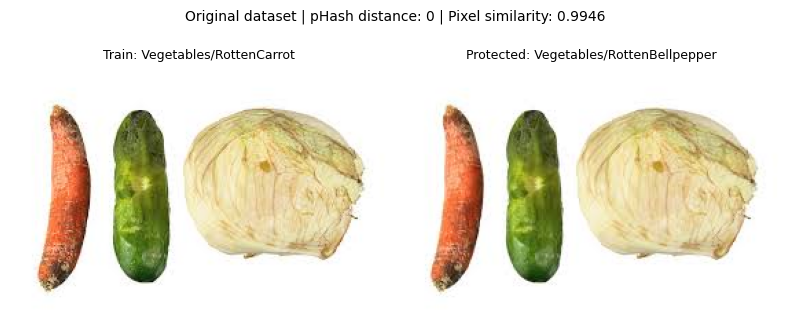


Original ambiguous pair 2


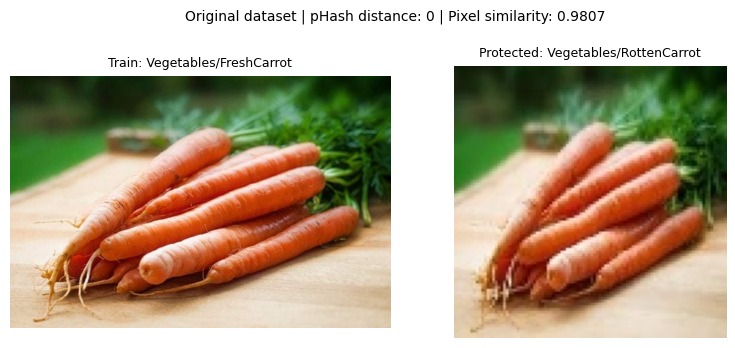


Original ambiguous pair 3


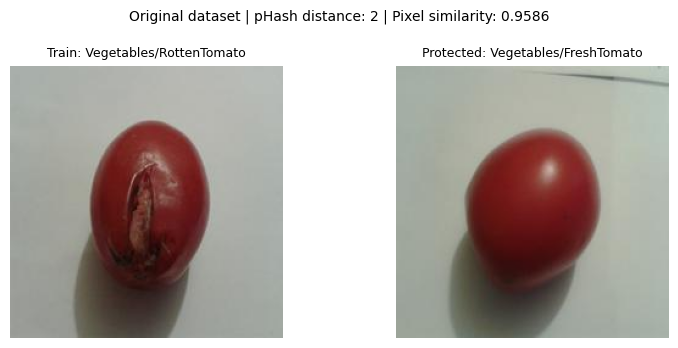


Original ambiguous pair 4


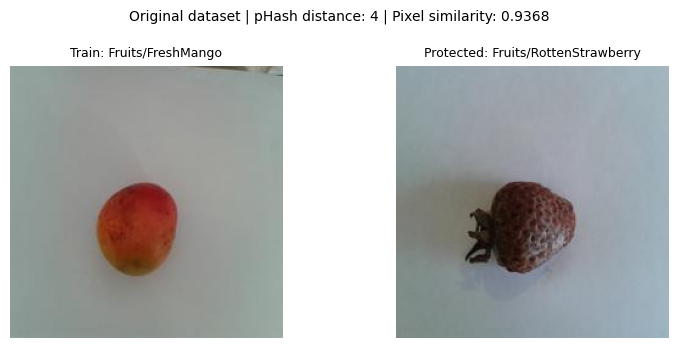


Original ambiguous pair 5


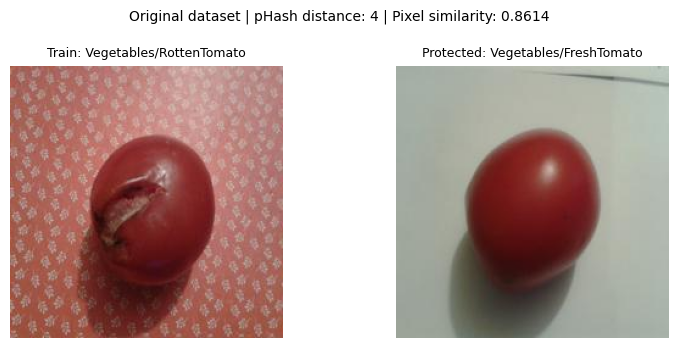


Original ambiguous pair 6


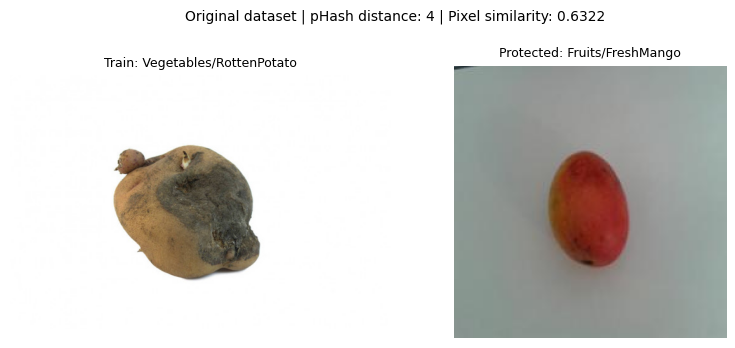


Original ambiguous pair 7


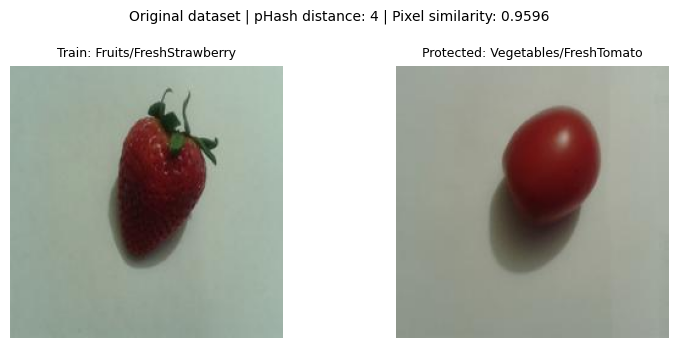


Original ambiguous pair 8


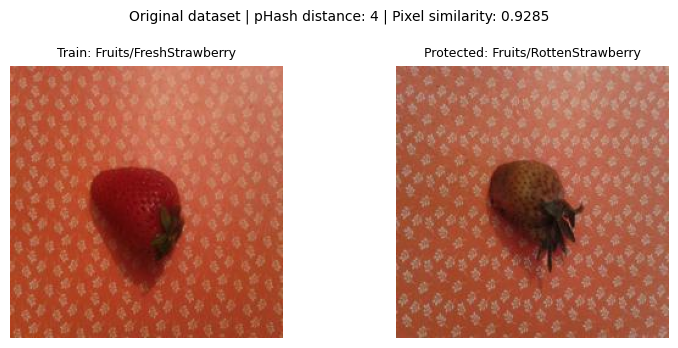


Original ambiguous pair 9


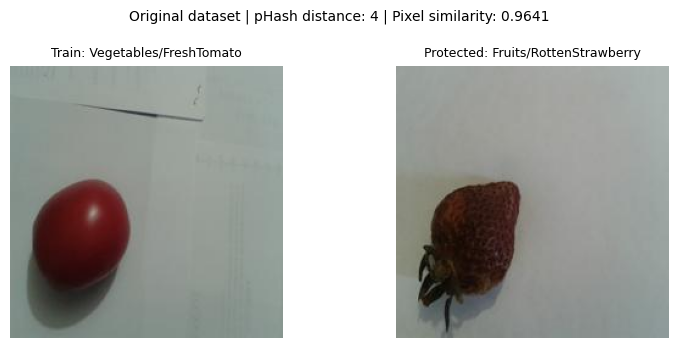


Original ambiguous pair 10


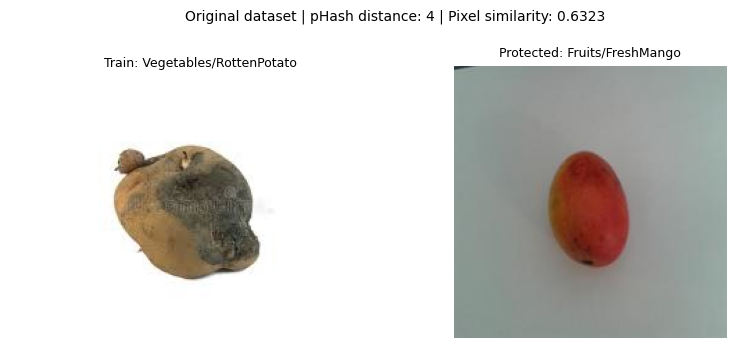


Original ambiguous pair 11


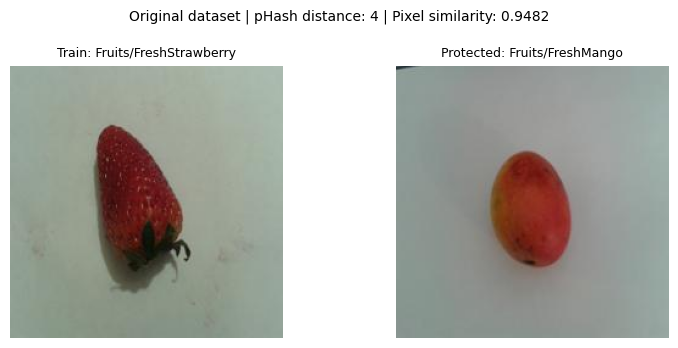


PART B — ADDITIONAL DATASET AMBIGUOUS MATCHES
--------------------------------------------------

Additional ambiguous pair 1


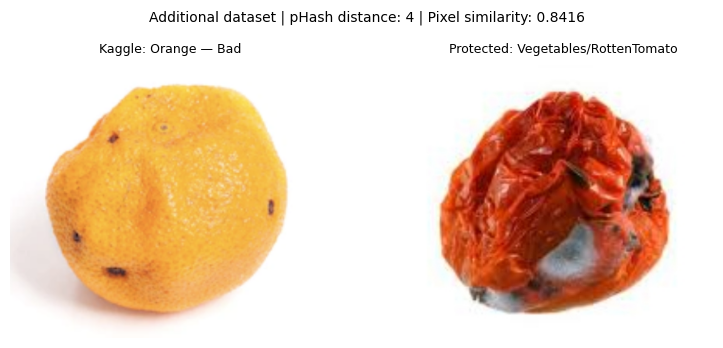


Additional ambiguous pair 2


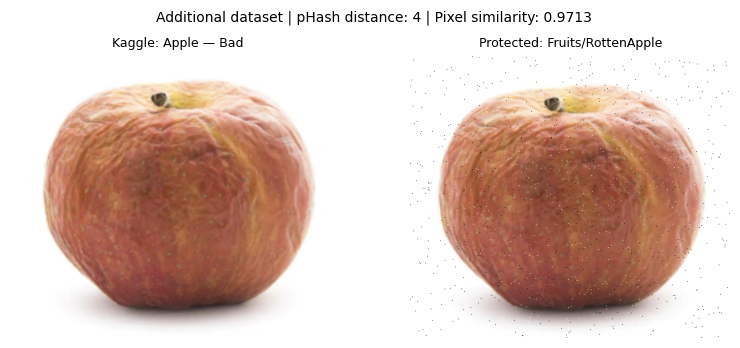


Additional ambiguous pair 3


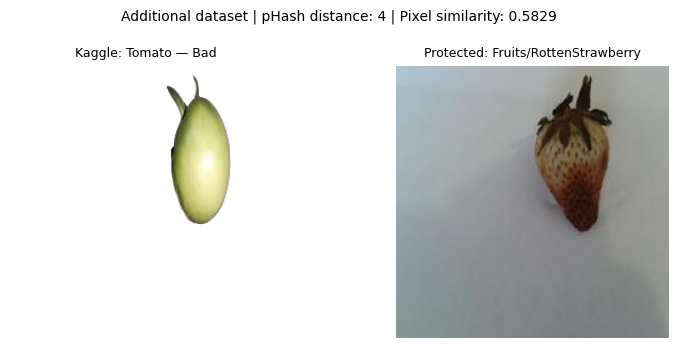


STEP 26.25 COMPLETE
No files or labels were modified.


In [125]:

# STEP 26.25 — VISUAL REVIEW OF AMBIGUOUS LEAKAGE MATCHES

import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 AMBIGUOUS MATCH VISUAL REVIEW")
print("=" * 65)

def display_review_pair(
    path_a, path_b,
    label_a, label_b,
    similarity, distance, source
):
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

    for ax, path, label in [
        (axes[0], path_a, label_a),
        (axes[1], path_b, label_b)
    ]:
        with Image.open(path) as img:
            ax.imshow(
                ImageOps.exif_transpose(img).convert("RGB")
            )

        ax.set_title(label, fontsize=9)
        ax.axis("off")

    fig.suptitle(
        f"{source} | pHash distance: {distance} | "
        f"Pixel similarity: {similarity:.4f}",
        fontsize=10
    )

    plt.tight_layout()
    plt.show()

# Review original dataset label disagreements
print("\nPART A — ORIGINAL DATASET LABEL DISAGREEMENTS")
print("-" * 50)

for index, row in enumerate(
    v3_label_review.itertuples(index=False),
    start=1
):
    print(f"\nOriginal ambiguous pair {index}")

    display_review_pair(
        row.training_path,
        row.protected_path,
        f"Train: {row.training_label}",
        f"Protected: {row.protected_label}",
        row.pixel_similarity,
        row.phash_distance,
        "Original dataset"
    )

# Review additional Kaggle ambiguous matches
print("\nPART B — ADDITIONAL DATASET AMBIGUOUS MATCHES")
print("-" * 50)

for index, row in enumerate(
    manual_review.itertuples(index=False),
    start=1
):
    print(f"\nAdditional ambiguous pair {index}")

    display_review_pair(
        row.additional_path,
        row.protected_path,
        f"Kaggle: {row.additional_produce} — {row.additional_quality}",
        f"Protected: {row.protected_label}",
        row.pixel_similarity,
        row.phash_distance,
        "Additional dataset"
    )

print("\nSTEP 26.25 COMPLETE")
print("No files or labels were modified.")


In [126]:

# STEP 26.26 — RECORD MANUAL VISUAL REVIEW DECISIONS

import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 MANUAL REVIEW DECISIONS")
print("=" * 65)

# Original ambiguous pairs confirmed from visual inspection:
# Pair 1: RottenCarrot vs RottenBellpepper
# Pair 2: FreshCarrot vs RottenCarrot
confirmed_original = v3_label_review.iloc[[0, 1]].copy()

confirmed_original["review_decision"] = [
    "Same multi-vegetable image; conflicting produce labels",
    "Same carrot photograph; conflicting freshness labels"
]

# Ambiguous Apple pair from the additional dataset
confirmed_apple = manual_review[
    (manual_review["additional_produce"] == "Apple")
    & (manual_review["protected_label"] == "Fruits/RottenApple")
].copy()

confirmed_apple["review_decision"] = (
    "Same underlying Apple photograph confirmed by visual review"
)

# Create updated training exclusion sets
original_manual_paths = set(
    confirmed_original["training_path"]
)

additional_manual_paths = set(
    confirmed_apple["additional_path"]
)

v3_original_reviewed = v3_original_leakage_screened[
    ~v3_original_leakage_screened["absolute_path"].isin(
        original_manual_paths
    )
].copy()

v3_additional_reviewed = v3_leakage_screened[
    ~v3_leakage_screened["absolute_path"].isin(
        additional_manual_paths
    )
].copy()

print("\nMANUAL REVIEW SUMMARY")
print("-" * 50)

print("Original training images additionally flagged:",
      len(original_manual_paths))

print("Additional Kaggle images additionally flagged:",
      len(additional_manual_paths))

print("\nUPDATED PROVISIONAL TRAINING POOLS")
print("-" * 50)

print("Original images:", len(v3_original_reviewed))
print("Additional images:", len(v3_additional_reviewed))

print(
    "Combined candidates:",
    len(v3_original_reviewed) + len(v3_additional_reviewed)
)

# Save evidence and updated manifests
confirmed_original.to_csv(
    REPORT_DIR / "v3_confirmed_original_label_issues.csv",
    index=False
)

confirmed_apple.to_csv(
    REPORT_DIR / "v3_confirmed_apple_leakage.csv",
    index=False
)

v3_original_reviewed.to_csv(
    REPORT_DIR / "v3_original_reviewed_candidates.csv",
    index=False
)

v3_additional_reviewed.to_csv(
    REPORT_DIR / "v3_additional_reviewed_candidates.csv",
    index=False
)

print("\nREPORTS SAVED")
print("-" * 50)
print("v3_confirmed_original_label_issues.csv")
print("v3_confirmed_apple_leakage.csv")
print("v3_original_reviewed_candidates.csv")
print("v3_additional_reviewed_candidates.csv")

print("\nNo source images were deleted or relabelled.")
print("Validation and test splits remain unchanged.")
print("\nSTEP 26.26 COMPLETE")


FRESHTRACK — CNN V3 MANUAL REVIEW DECISIONS

MANUAL REVIEW SUMMARY
--------------------------------------------------
Original training images additionally flagged: 2
Additional Kaggle images additionally flagged: 1

UPDATED PROVISIONAL TRAINING POOLS
--------------------------------------------------
Original images: 8010
Additional images: 12106
Combined candidates: 20116

REPORTS SAVED
--------------------------------------------------
v3_confirmed_original_label_issues.csv
v3_confirmed_apple_leakage.csv
v3_original_reviewed_candidates.csv
v3_additional_reviewed_candidates.csv

No source images were deleted or relabelled.
Validation and test splits remain unchanged.

STEP 26.26 COMPLETE


In [127]:

# STEP 26.27 — INTERNAL IMAGE DIVERSITY AUDIT

import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 INTERNAL IMAGE DIVERSITY AUDIT")
print("=" * 65)

# Use the additional dataset after protected-split exclusions
diversity_df = v3_additional_reviewed.copy()

# Reuse hashes calculated in Step 26.17
hash_lookup = (
    additional_check[
        ["absolute_path", "phash", "dhash"]
    ]
    .drop_duplicates(subset=["absolute_path"])
)

diversity_df = diversity_df.merge(
    hash_lookup,
    on="absolute_path",
    how="left",
    validate="one_to_one"
)

assert diversity_df["phash"].notna().all(), (
    "Some additional images are missing pHashes."
)

assert diversity_df["dhash"].notna().all(), (
    "Some additional images are missing dHashes."
)

# Define groups within the same produce/freshness category
group_columns = [
    "produce",
    "quality",
    "phash",
    "dhash"
]

group_sizes = (
    diversity_df
    .groupby(group_columns)
    .size()
    .reset_index(name="group_size")
)

diversity_df = diversity_df.merge(
    group_sizes,
    on=group_columns,
    how="left",
    validate="many_to_one"
)

# Calculate class-level diversity statistics
class_summary = (
    diversity_df
    .groupby(["produce", "quality"])
    .agg(
        total_images=("absolute_path", "size"),
        unique_hash_groups=("phash", lambda x: 0),
        images_in_repeated_groups=(
            "group_size",
            lambda x: int((x > 1).sum())
        ),
        largest_group=("group_size", "max")
    )
    .reset_index()
)

# Replace placeholder with actual dual-hash group counts
unique_groups = (
    group_sizes
    .groupby(["produce", "quality"])
    .size()
    .rename("unique_hash_groups")
    .reset_index()
)

class_summary = class_summary.drop(
    columns=["unique_hash_groups"]
).merge(
    unique_groups,
    on=["produce", "quality"],
    how="left"
)

class_summary["repeated_group_percentage"] = (
    class_summary["images_in_repeated_groups"]
    / class_summary["total_images"] * 100
).round(2)

class_summary = class_summary[
    [
        "produce",
        "quality",
        "total_images",
        "unique_hash_groups",
        "images_in_repeated_groups",
        "repeated_group_percentage",
        "largest_group"
    ]
].sort_values(
    ["produce", "quality"]
)

print("\nINTERNAL DIVERSITY BY CLASS")
print("-" * 65)
print(class_summary.to_string(index=False))

print("\nOVERALL SUMMARY")
print("-" * 50)
print("Images audited:", len(diversity_df))
print("Dual-hash groups:", len(group_sizes))
print(
    "Images in repeated groups:",
    int((diversity_df["group_size"] > 1).sum())
)
print(
    "Largest dual-hash group:",
    int(diversity_df["group_size"].max())
)

print("\nSAVING REPORTS")
print("-" * 50)

class_summary.to_csv(
    REPORT_DIR / "v3_internal_diversity_summary.csv",
    index=False
)

diversity_df.to_csv(
    REPORT_DIR / "v3_internal_diversity_manifest.csv",
    index=False
)

print("v3_internal_diversity_summary.csv")
print("v3_internal_diversity_manifest.csv")

print("\nNo images were removed or relabelled.")
print("STEP 26.27 COMPLETE")


FRESHTRACK — CNN V3 INTERNAL IMAGE DIVERSITY AUDIT

INTERNAL DIVERSITY BY CLASS
-----------------------------------------------------------------
    produce quality  total_images  unique_hash_groups  images_in_repeated_groups  repeated_group_percentage  largest_group
      Apple     Bad           412                 399                         24                       5.83              3
      Apple    Good           178                 178                          0                       0.00              1
    Avocado     Bad           100                   8                        100                     100.00             39
    Avocado    Good           504                  19                        490                      97.22            369
     Banana     Bad           693                 415                        331                      47.76             41
     Banana    Good           348                 216                        162                      46.55         

In [128]:

# STEP 26.28 — GROUP-AWARE SPLIT FEASIBILITY AUDIT

import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 GROUP-AWARE SPLIT FEASIBILITY")
print("=" * 65)

# Reuse the class-level diversity summary from Step 26.27
feasibility_df = class_summary.copy()

MIN_GROUPS_FOR_REVIEW = 15

# Identify the six newly introduced produce categories
new_produce_types = {
    "Avocado",
    "Lemon",
    "Papaya",
    "Peach",
    "Persimmon",
    "Watermelon"
}

feasibility_df["produce_category"] = (
    feasibility_df["produce"].apply(
        lambda value: (
            "New in V3"
            if value in new_produce_types
            else "Original produce type"
        )
    )
)

feasibility_df["split_review_status"] = (
    feasibility_df["unique_hash_groups"].apply(
        lambda count: (
            "LIMITED GROUP DIVERSITY"
            if count < MIN_GROUPS_FOR_REVIEW
            else "GROUP COUNT SUFFICIENT FOR SPLIT PLANNING"
        )
    )
)

feasibility_df["images_per_group"] = (
    feasibility_df["total_images"]
    / feasibility_df["unique_hash_groups"]
).round(2)

print("\nCLASS-LEVEL SPLIT FEASIBILITY")
print("-" * 65)

print(
    feasibility_df[
        [
            "produce",
            "quality",
            "produce_category",
            "total_images",
            "unique_hash_groups",
            "images_per_group",
            "split_review_status"
        ]
    ].to_string(index=False)
)

limited_classes = feasibility_df[
    feasibility_df["unique_hash_groups"]
    < MIN_GROUPS_FOR_REVIEW
]

print("\nCLASSES REQUIRING ADDITIONAL REVIEW")
print("-" * 50)

if limited_classes.empty:
    print("No classes below the planning threshold.")
else:
    print(
        limited_classes[
            [
                "produce",
                "quality",
                "unique_hash_groups"
            ]
        ].to_string(index=False)
    )

print("\nNEW PRODUCE TYPES — GROUP COVERAGE")
print("-" * 50)

new_type_summary = (
    feasibility_df[
        feasibility_df["produce_category"] == "New in V3"
    ][
        [
            "produce",
            "quality",
            "total_images",
            "unique_hash_groups"
        ]
    ]
    .sort_values(["produce", "quality"])
)

print(new_type_summary.to_string(index=False))

feasibility_df.to_csv(
    REPORT_DIR / "v3_group_split_feasibility.csv",
    index=False
)

print("\nSAVED: v3_group_split_feasibility.csv")
print("No images were removed, relabelled or split.")
print("\nSTEP 26.28 COMPLETE")


FRESHTRACK — CNN V3 GROUP-AWARE SPLIT FEASIBILITY

CLASS-LEVEL SPLIT FEASIBILITY
-----------------------------------------------------------------
    produce quality      produce_category  total_images  unique_hash_groups  images_per_group                       split_review_status
      Apple     Bad Original produce type           412                 399              1.03 GROUP COUNT SUFFICIENT FOR SPLIT PLANNING
      Apple    Good Original produce type           178                 178              1.00 GROUP COUNT SUFFICIENT FOR SPLIT PLANNING
    Avocado     Bad             New in V3           100                   8             12.50                   LIMITED GROUP DIVERSITY
    Avocado    Good             New in V3           504                  19             26.53 GROUP COUNT SUFFICIENT FOR SPLIT PLANNING
     Banana     Bad Original produce type           693                 415              1.67 GROUP COUNT SUFFICIENT FOR SPLIT PLANNING
     Banana    Good Original produce 

In [129]:

# STEP 26.29 — LARGE-GROUP DOMINANCE AUDIT

import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 LARGE-GROUP DOMINANCE AUDIT")
print("=" * 65)

new_produce_types = {
    "Avocado",
    "Lemon",
    "Papaya",
    "Peach",
    "Persimmon",
    "Watermelon"
}

# Reuse the hashed additional dataset from Step 26.27
new_produce_df = diversity_df[
    diversity_df["produce"].isin(new_produce_types)
].copy()

# One record per produce/quality/dual-hash group
new_group_sizes = (
    new_produce_df
    .groupby(
        ["produce", "quality", "phash", "dhash"]
    )
    .size()
    .reset_index(name="group_size")
)

records = []

for (produce, quality), group in new_group_sizes.groupby(
    ["produce", "quality"]
):
    sizes = group["group_size"].sort_values(
        ascending=False
    ).tolist()

    total_images = sum(sizes)
    total_groups = len(sizes)

    largest_group = sizes[0]
    top_three = sum(sizes[:3])

    records.append({
        "produce": produce,
        "quality": quality,
        "total_images": total_images,
        "dual_hash_groups": total_groups,
        "largest_group_images": largest_group,
        "largest_group_pct": round(
            largest_group / total_images * 100, 2
        ),
        "top_3_groups_pct": round(
            top_three / total_images * 100, 2
        ),
        "one_per_group_images": total_groups,
        "one_per_group_reduction_pct": round(
            (1 - total_groups / total_images) * 100, 2
        )
    })

dominance_df = pd.DataFrame(records).sort_values(
    ["produce", "quality"]
)

print("\nGROUP DOMINANCE BY NEW CLASS")
print("-" * 65)

print(dominance_df.to_string(index=False))

print("\nCLASSES WHERE THE LARGEST GROUP EXCEEDS 30%")
print("-" * 50)

high_dominance = dominance_df[
    dominance_df["largest_group_pct"] > 30
]

if high_dominance.empty:
    print("None")
else:
    print(
        high_dominance[
            [
                "produce",
                "quality",
                "largest_group_images",
                "largest_group_pct",
                "top_3_groups_pct"
            ]
        ].to_string(index=False)
    )

print("\nONE-REPRESENTATIVE-PER-GROUP SCENARIO")
print("-" * 50)

print(
    "Total additional images in six new produce types:",
    int(dominance_df["total_images"].sum())
)

print(
    "Total dual-hash groups:",
    int(dominance_df["dual_hash_groups"].sum())
)

dominance_df.to_csv(
    REPORT_DIR / "v3_new_produce_group_dominance.csv",
    index=False
)

print("\nSAVED: v3_new_produce_group_dominance.csv")
print("No images were removed or split.")
print("\nSTEP 26.29 COMPLETE")


FRESHTRACK — CNN V3 LARGE-GROUP DOMINANCE AUDIT

GROUP DOMINANCE BY NEW CLASS
-----------------------------------------------------------------
   produce quality  total_images  dual_hash_groups  largest_group_images  largest_group_pct  top_3_groups_pct  one_per_group_images  one_per_group_reduction_pct
   Avocado     Bad           100                 8                    39              39.00             70.00                     8                        92.00
   Avocado    Good           504                19                   369              73.21             95.04                    19                        96.23
     Lemon     Bad          1238              1229                     2               0.16              0.48                  1229                         0.73
     Lemon    Good           954               946                     2               0.21              0.63                   946                         0.84
    Papaya     Bad           413                30 

In [130]:

# STEP 26.30 — GROUP-AWARE SPLIT ALLOCATION PLAN

import pandas as pd
import math

print("=" * 65)
print("FRESHTRACK — CNN V3 GROUP-AWARE SPLIT PLAN")
print("=" * 65)

TARGET_TRAIN = 0.70
TARGET_VAL = 0.15
TARGET_TEST = 0.15

plan_records = []

for _, row in dominance_df.iterrows():

    total_groups = int(row["dual_hash_groups"])

    # Reserve at least one group for validation and testing
    val_groups = max(1, round(total_groups * TARGET_VAL))
    test_groups = max(1, round(total_groups * TARGET_TEST))
    train_groups = total_groups - val_groups - test_groups

    if train_groups < 1:
        raise ValueError(
            f"Insufficient groups for {row['produce']} "
            f"{row['quality']}"
        )

    plan_records.append({
        "produce": row["produce"],
        "quality": row["quality"],
        "total_images": int(row["total_images"]),
        "total_groups": total_groups,
        "train_groups": train_groups,
        "validation_groups": val_groups,
        "test_groups": test_groups,
        "largest_group_pct": row["largest_group_pct"],
        "evaluation_caution": (
            "HIGH — limited independent groups"
            if total_groups < 15
            else (
                "MODERATE — group imbalance"
                if row["largest_group_pct"] > 30
                else "STANDARD — still requires validation"
            )
        )
    })

v3_split_plan = pd.DataFrame(plan_records)

print("\nPROPOSED GROUP ALLOCATION")
print("-" * 65)

print(v3_split_plan.to_string(index=False))

print("\nTOTAL GROUP ALLOCATION")
print("-" * 50)

for column in [
    "train_groups",
    "validation_groups",
    "test_groups"
]:
    print(
        f"{column}:",
        int(v3_split_plan[column].sum())
    )

print("\nCLASSES REQUIRING CAUTIOUS EVALUATION")
print("-" * 50)

caution = v3_split_plan[
    v3_split_plan["evaluation_caution"]
    != "STANDARD — still requires validation"
]

print(
    caution[
        [
            "produce",
            "quality",
            "total_groups",
            "train_groups",
            "validation_groups",
            "test_groups",
            "evaluation_caution"
        ]
    ].to_string(index=False)
)

v3_split_plan.to_csv(
    REPORT_DIR / "v3_group_split_allocation_plan.csv",
    index=False
)

print("\nSAVED: v3_group_split_allocation_plan.csv")
print("No images were moved, removed or assigned.")
print("\nSTEP 26.30 COMPLETE")


FRESHTRACK — CNN V3 GROUP-AWARE SPLIT PLAN

PROPOSED GROUP ALLOCATION
-----------------------------------------------------------------
   produce quality  total_images  total_groups  train_groups  validation_groups  test_groups  largest_group_pct                   evaluation_caution
   Avocado     Bad           100             8             6                  1            1              39.00    HIGH — limited independent groups
   Avocado    Good           504            19            13                  3            3              73.21           MODERATE — group imbalance
     Lemon     Bad          1238          1229           861                184          184               0.16 STANDARD — still requires validation
     Lemon    Good           954           946           662                142          142               0.21 STANDARD — still requires validation
    Papaya     Bad           413            30            22                  4            4              13.32 STANDAR

In [131]:

# STEP 26.31 — CREATE PROVISIONAL GROUP-AWARE SPLITS

import numpy as np
import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 GROUP-AWARE SPLIT ASSIGNMENT")
print("=" * 65)

SEED = 42
rng = np.random.default_rng(SEED)

split_records = []

for _, plan in v3_split_plan.iterrows():

    produce = plan["produce"]
    quality = plan["quality"]

    class_images = new_produce_df[
        (new_produce_df["produce"] == produce)
        & (new_produce_df["quality"] == quality)
    ].copy()

    groups = (
        class_images
        .groupby(["phash", "dhash"])
        .size()
        .reset_index(name="group_size")
    )

    # Shuffle before sorting to randomise equal-sized groups
    groups = groups.iloc[
        rng.permutation(len(groups))
    ].copy()

    groups = groups.sort_values(
        "group_size",
        ascending=False,
        kind="stable"
    ).reset_index(drop=True)

    group_targets = {
        "train": int(plan["train_groups"]),
        "validation": int(plan["validation_groups"]),
        "test": int(plan["test_groups"])
    }

    image_targets = {
        "train": len(class_images) * 0.70,
        "validation": len(class_images) * 0.15,
        "test": len(class_images) * 0.15
    }

    assigned_groups = {s: 0 for s in group_targets}
    assigned_images = {s: 0 for s in group_targets}

    assignments = []

    for _, group in groups.iterrows():

        available = [
            split for split in group_targets
            if assigned_groups[split] < group_targets[split]
        ]

        # Prefer the split with the greatest remaining
        # image capacity, while respecting group quotas.
        selected = max(
            available,
            key=lambda split: (
                image_targets[split] - assigned_images[split],
                group_targets[split] - assigned_groups[split]
            )
        )

        assignments.append({
            "phash": group["phash"],
            "dhash": group["dhash"],
            "split": selected
        })

        assigned_groups[selected] += 1
        assigned_images[selected] += int(group["group_size"])

    assignment_df = pd.DataFrame(assignments)

    class_images = class_images.merge(
        assignment_df,
        on=["phash", "dhash"],
        how="left",
        validate="many_to_one"
    )

    assert class_images["split"].notna().all()

    split_records.append(class_images)

v3_new_produce_split = pd.concat(
    split_records,
    ignore_index=True
)

print("\nIMAGE COUNTS BY SPLIT")
print("-" * 50)

print(
    v3_new_produce_split["split"]
    .value_counts()
    .reindex(["train", "validation", "test"])
    .to_string()
)

print("\nCLASS-LEVEL IMAGE COUNTS")
print("-" * 50)

split_summary = pd.crosstab(
    [
        v3_new_produce_split["produce"],
        v3_new_produce_split["quality"]
    ],
    v3_new_produce_split["split"]
)

print(
    split_summary.reindex(
        columns=["train", "validation", "test"],
        fill_value=0
    ).to_string()
)

print("\nVERIFYING GROUP ISOLATION")
print("-" * 50)

group_overlap = (
    v3_new_produce_split
    .groupby(["produce", "quality", "phash", "dhash"])["split"]
    .nunique()
)

cross_split_groups = int((group_overlap > 1).sum())

print("Dual-hash groups crossing splits:", cross_split_groups)

assert cross_split_groups == 0, (
    "Group leakage detected."
)

assert len(v3_new_produce_split) == len(new_produce_df), (
    "Image count mismatch."
)

print("\nSAVING REPORTS")
print("-" * 50)

v3_new_produce_split.to_csv(
    REPORT_DIR / "v3_new_produce_provisional_splits.csv",
    index=False
)

split_summary.to_csv(
    REPORT_DIR / "v3_new_produce_split_summary.csv"
)

print("v3_new_produce_provisional_splits.csv")
print("v3_new_produce_split_summary.csv")

print("\nIMPORTANT")
print("Splits are provisional.")
print("No images were moved or deleted.")
print("Cross-group near-duplicate checks remain necessary.")

print("\nSTEP 26.31 COMPLETE")


FRESHTRACK — CNN V3 GROUP-AWARE SPLIT ASSIGNMENT

IMAGE COUNTS BY SPLIT
--------------------------------------------------
split
train         3992
validation     767
test           675

CLASS-LEVEL IMAGE COUNTS
--------------------------------------------------
split               train  validation  test
produce    quality                         
Avocado    Bad         79          11    10
           Good       381          91    32
Lemon      Bad        870         184   184
           Good       670         142   142
Papaya     Bad        305          54    54
           Good       100          16    14
Peach      Bad        444          70    70
           Good       334          59    32
Persimmon  Bad        250          45    45
           Good       399          74    72
Watermelon Bad        118          16    16
           Good        42           5     4

VERIFYING GROUP ISOLATION
--------------------------------------------------
Dual-hash groups crossing splits: 0

SAVING

In [132]:

# STEP 26.32 — CROSS-SPLIT NEAR-DUPLICATE SCREENING

import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 CROSS-SPLIT SIMILARITY AUDIT")
print("=" * 65)

MAX_DISTANCE = 4

# One record per dual-hash group, retaining its assigned split
group_representatives = (
    v3_new_produce_split
    .drop_duplicates(
        subset=["produce", "quality", "phash", "dhash"]
    )
    .copy()
)

records = []

print("\nComparing image-group representatives...")

for (produce, quality), class_groups in (
    group_representatives.groupby(["produce", "quality"])
):
    class_groups = class_groups.reset_index(drop=True)

    hash_values = [
        int(value, 16)
        for value in class_groups["phash"]
    ]

    for i in range(len(class_groups)):
        for j in range(i + 1, len(class_groups)):

            split_a = class_groups.iloc[i]["split"]
            split_b = class_groups.iloc[j]["split"]

            # Only interested in potential leakage across splits
            if split_a == split_b:
                continue

            distance = (
                hash_values[i] ^ hash_values[j]
            ).bit_count()

            if distance <= MAX_DISTANCE:
                records.append({
                    "produce": produce,
                    "quality": quality,
                    "path_a": class_groups.iloc[i]["absolute_path"],
                    "path_b": class_groups.iloc[j]["absolute_path"],
                    "split_a": split_a,
                    "split_b": split_b,
                    "phash_distance": distance
                })

cross_split_candidates = pd.DataFrame(
    records,
    columns=[
        "produce",
        "quality",
        "path_a",
        "path_b",
        "split_a",
        "split_b",
        "phash_distance"
    ]
)

print("\nCROSS-SPLIT SCREENING RESULTS")
print("-" * 50)

print("Groups examined:", len(group_representatives))
print("Potential cross-split group pairs:",
      len(cross_split_candidates))

if not cross_split_candidates.empty:

    print("\nMATCHES BY CLASS")
    print("-" * 50)

    print(
        cross_split_candidates.groupby(
            ["produce", "quality"]
        ).size().to_string()
    )

    print("\nMATCHES BY PHASH DISTANCE")
    print("-" * 50)

    print(
        cross_split_candidates["phash_distance"]
        .value_counts()
        .sort_index()
        .to_string()
    )

    print("\nMATCHES BY SPLIT COMBINATION")
    print("-" * 50)

    combinations = cross_split_candidates.apply(
        lambda row: " / ".join(
            sorted([row["split_a"], row["split_b"]])
        ),
        axis=1
    )

    print(combinations.value_counts().to_string())

cross_split_candidates.to_csv(
    REPORT_DIR / "v3_new_produce_cross_split_candidates.csv",
    index=False
)

print("\nSAVED: v3_new_produce_cross_split_candidates.csv")
print("No images were removed or reassigned.")
print("\nSTEP 26.32 COMPLETE")


FRESHTRACK — CNN V3 CROSS-SPLIT SIMILARITY AUDIT

Comparing image-group representatives...

CROSS-SPLIT SCREENING RESULTS
--------------------------------------------------
Groups examined: 2582
Potential cross-split group pairs: 4399

MATCHES BY CLASS
--------------------------------------------------
produce     quality
Avocado     Bad          13
            Good         32
Lemon       Bad        1252
            Good       1344
Papaya      Bad         111
            Good         11
Peach       Bad         454
            Good         11
Persimmon   Bad         264
            Good        213
Watermelon  Bad         540
            Good        154

MATCHES BY PHASH DISTANCE
--------------------------------------------------
phash_distance
0     473
2    1440
4    2486

MATCHES BY SPLIT COMBINATION
--------------------------------------------------
test / train          2080
train / validation    1933
test / validation      386

SAVED: v3_new_produce_cross_split_candidates.csv
No im

In [133]:

# STEP 26.33 — CROSS-SPLIT PIXEL SIMILARITY AUDIT

import numpy as np
import pandas as pd
from PIL import Image
from functools import lru_cache

print("=" * 65)
print("FRESHTRACK — CNN V3 CROSS-SPLIT PIXEL VERIFICATION")
print("=" * 65)

@lru_cache(maxsize=6000)
def load_comparison_image(path):
    with Image.open(path) as image:
        image = image.convert("RGB")
        image = image.resize(
            (128, 128),
            Image.Resampling.BILINEAR
        )
        return np.asarray(image, dtype=np.float32)

def calculate_similarity(path_a, path_b):
    image_a = load_comparison_image(path_a)
    image_b = load_comparison_image(path_b)

    mean_difference = np.mean(
        np.abs(image_a - image_b)
    )

    return float(1.0 - mean_difference / 255.0)

verified_records = []
failed_records = []

for index, row in cross_split_candidates.iterrows():

    try:
        similarity = calculate_similarity(
            row["path_a"],
            row["path_b"]
        )

        verified_records.append({
            **row.to_dict(),
            "pixel_similarity": similarity
        })

    except Exception as error:
        failed_records.append({
            "path_a": row["path_a"],
            "path_b": row["path_b"],
            "error": str(error)
        })

    if (index + 1) % 1000 == 0:
        print(
            f"Processed {index + 1:,} / "
            f"{len(cross_split_candidates):,} pairs"
        )

v3_cross_split_verified = pd.DataFrame(
    verified_records
)

v3_cross_split_failures = pd.DataFrame(
    failed_records,
    columns=["path_a", "path_b", "error"]
)

print("\nPIXEL SIMILARITY RESULTS")
print("-" * 50)

print("Candidate pairs:", len(cross_split_candidates))
print("Successfully compared:", len(v3_cross_split_verified))
print("Failed comparisons:", len(v3_cross_split_failures))

if not v3_cross_split_verified.empty:

    for threshold in [0.95, 0.98, 0.99, 0.995, 0.999]:
        count = int(
            (
                v3_cross_split_verified["pixel_similarity"]
                >= threshold
            ).sum()
        )

        print(f"Similarity >= {threshold:.3f}: {count}")

    print("\nHIGH-SIMILARITY PAIRS BY CLASS")
    print("-" * 50)

    high_similarity = v3_cross_split_verified[
        v3_cross_split_verified["pixel_similarity"] >= 0.99
    ]

    if high_similarity.empty:
        print("No pairs reached 0.99.")
    else:
        print(
            high_similarity.groupby(
                ["produce", "quality"]
            ).size().to_string()
        )

    print("\nTOP 15 MOST SIMILAR PAIRS")
    print("-" * 50)

    print(
        v3_cross_split_verified.nlargest(
            15,
            "pixel_similarity"
        )[
            [
                "produce",
                "quality",
                "split_a",
                "split_b",
                "phash_distance",
                "pixel_similarity"
            ]
        ].to_string(index=False)
    )

v3_cross_split_verified.to_csv(
    REPORT_DIR / "v3_cross_split_pixel_verified.csv",
    index=False
)

v3_cross_split_failures.to_csv(
    REPORT_DIR / "v3_cross_split_pixel_failures.csv",
    index=False
)

print("\nREPORTS SAVED")
print("-" * 50)
print("v3_cross_split_pixel_verified.csv")
print("v3_cross_split_pixel_failures.csv")

print("\nNo images were removed or reassigned.")
print("STEP 26.33 COMPLETE")


FRESHTRACK — CNN V3 CROSS-SPLIT PIXEL VERIFICATION
Processed 1,000 / 4,399 pairs
Processed 2,000 / 4,399 pairs
Processed 3,000 / 4,399 pairs
Processed 4,000 / 4,399 pairs

PIXEL SIMILARITY RESULTS
--------------------------------------------------
Candidate pairs: 4399
Successfully compared: 4399
Failed comparisons: 0
Similarity >= 0.950: 4285
Similarity >= 0.980: 2244
Similarity >= 0.990: 839
Similarity >= 0.995: 307
Similarity >= 0.999: 21

HIGH-SIMILARITY PAIRS BY CLASS
--------------------------------------------------
produce     quality
Avocado     Bad          6
            Good         4
Lemon       Bad        105
            Good        75
Papaya      Bad         20
            Good         9
Peach       Bad        152
            Good         4
Persimmon   Bad        149
            Good       200
Watermelon  Bad         67
            Good        48

TOP 15 MOST SIMILAR PAIRS
--------------------------------------------------
  produce quality    split_a    split_b  phash_di

In [134]:

# STEP 26.34 — CONNECTED NEAR-DUPLICATE GROUP AUDIT

import pandas as pd
from collections import defaultdict

print("=" * 65)
print("FRESHTRACK — CNN V3 CONNECTED SIMILARITY GROUP AUDIT")
print("=" * 65)

SIMILARITY_THRESHOLD = 0.995

# Start from the existing dual-hash group representatives
nodes = group_representatives[
    ["produce", "quality", "phash", "dhash", "split"]
].drop_duplicates().copy()

nodes["node_id"] = (
    nodes["produce"].astype(str) + "|" +
    nodes["quality"].astype(str) + "|" +
    nodes["phash"].astype(str) + "|" +
    nodes["dhash"].astype(str)
)

parent = {node: node for node in nodes["node_id"]}
rank = {node: 0 for node in nodes["node_id"]}

def find(node):
    while parent[node] != node:
        parent[node] = parent[parent[node]]
        node = parent[node]
    return node

def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a == root_b:
        return

    if rank[root_a] < rank[root_b]:
        root_a, root_b = root_b, root_a

    parent[root_b] = root_a

    if rank[root_a] == rank[root_b]:
        rank[root_a] += 1

# Look up the dual-hash group for each representative path
path_to_node = dict(
    zip(
        group_representatives["absolute_path"],
        nodes["node_id"]
    )
)

high_similarity_pairs = v3_cross_split_verified[
    v3_cross_split_verified["pixel_similarity"]
    >= SIMILARITY_THRESHOLD
].copy()

edges_added = 0

for _, row in high_similarity_pairs.iterrows():
    node_a = path_to_node.get(row["path_a"])
    node_b = path_to_node.get(row["path_b"])

    if node_a is None or node_b is None:
        continue

    union(node_a, node_b)
    edges_added += 1

nodes["component_id"] = nodes["node_id"].map(find)

component_summary = (
    nodes.groupby("component_id")
    .agg(
        produce=("produce", "first"),
        quality=("quality", "first"),
        dual_hash_groups=("node_id", "size"),
        splits_spanned=("split", "nunique")
    )
    .reset_index()
)

cross_split_components = component_summary[
    component_summary["splits_spanned"] > 1
]

print("\nCONNECTED COMPONENT RESULTS")
print("-" * 50)
print("Original dual-hash groups:", len(nodes))
print("High-similarity edges processed:", edges_added)
print("Connected components:", len(component_summary))
print(
    "Components spanning multiple splits:",
    len(cross_split_components)
)

print("\nLARGEST COMPONENTS")
print("-" * 50)

print(
    component_summary.nlargest(
        15,
        "dual_hash_groups"
    )[
        [
            "produce",
            "quality",
            "dual_hash_groups",
            "splits_spanned"
        ]
    ].to_string(index=False)
)

print("\nCROSS-SPLIT COMPONENTS BY CLASS")
print("-" * 50)

if cross_split_components.empty:
    print("None")
else:
    print(
        cross_split_components.groupby(
            ["produce", "quality"]
        ).size().to_string()
    )

nodes.to_csv(
    REPORT_DIR / "v3_similarity_component_nodes.csv",
    index=False
)

component_summary.to_csv(
    REPORT_DIR / "v3_similarity_component_summary.csv",
    index=False
)

print("\nREPORTS SAVED")
print("-" * 50)
print("v3_similarity_component_nodes.csv")
print("v3_similarity_component_summary.csv")

print("\nNo images were removed or reassigned.")
print("STEP 26.34 COMPLETE")


FRESHTRACK — CNN V3 CONNECTED SIMILARITY GROUP AUDIT

CONNECTED COMPONENT RESULTS
--------------------------------------------------
Original dual-hash groups: 2582
High-similarity edges processed: 307
Connected components: 2370
Components spanning multiple splits: 50

LARGEST COMPONENTS
--------------------------------------------------
   produce quality  dual_hash_groups  splits_spanned
 Persimmon    Good                52               3
 Persimmon     Bad                18               3
     Peach     Bad                 9               3
 Persimmon     Bad                 8               3
 Persimmon     Bad                 8               3
Watermelon    Good                 8               3
     Peach     Bad                 7               3
 Persimmon     Bad                 7               3
     Peach     Bad                 6               2
     Peach     Bad                 6               3
     Peach     Bad                 6               3
     Peach     Bad      

In [135]:

# STEP 26.35 — PROVISIONAL COMPONENT-AWARE SPLIT CORRECTION

import numpy as np
import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 COMPONENT-AWARE SPLIT CORRECTION")
print("=" * 65)

SPLITS = ["train", "validation", "test"]
TARGETS = {"train": 0.70, "validation": 0.15, "test": 0.15}

# Map each image to the component of its dual-hash group
component_lookup = nodes[
    ["produce", "quality", "phash", "dhash", "component_id"]
].drop_duplicates()

corrected_df = v3_new_produce_split.drop(
    columns=["component_id"],
    errors="ignore"
).merge(
    component_lookup,
    on=["produce", "quality", "phash", "dhash"],
    how="left",
    validate="many_to_one"
)

assert corrected_df["component_id"].notna().all()

# Count images and existing assignments within each component
component_counts = (
    corrected_df.groupby(
        ["produce", "quality", "component_id", "split"]
    )
    .size()
    .unstack(fill_value=0)
    .reindex(columns=SPLITS, fill_value=0)
    .reset_index()
)

component_counts["total_images"] = (
    component_counts[SPLITS].sum(axis=1)
)

assignment_records = []
warnings = []

for (produce, quality), class_components in (
    component_counts.groupby(["produce", "quality"])
):

    class_components = class_components.copy()
    class_components = class_components.sort_values(
        ["total_images", "component_id"],
        ascending=[False, True]
    )

    number_of_components = len(class_components)
    total_images = int(class_components["total_images"].sum())

    if number_of_components < 3:
        warnings.append({
            "produce": produce,
            "quality": quality,
            "components": number_of_components,
            "issue": "Fewer than three independent candidate components"
        })

    target_images = {
        split: total_images * TARGETS[split]
        for split in SPLITS
    }

    current_images = {split: 0 for split in SPLITS}
    current_components = {split: 0 for split in SPLITS}

    for _, component in class_components.iterrows():

        size = int(component["total_images"])

        # Prefer the original majority assignment when it
        # does not create excessive image imbalance.
        preferred = sorted(
            SPLITS,
            key=lambda split: (
                abs(
                    (current_images[split] + size)
                    - target_images[split]
                ),
                -int(component[split]),
                SPLITS.index(split)
            )
        )

        selected = preferred[0]

        assignment_records.append({
            "produce": produce,
            "quality": quality,
            "component_id": component["component_id"],
            "corrected_split": selected
        })

        current_images[selected] += size
        current_components[selected] += 1

component_assignments = pd.DataFrame(
    assignment_records
)

corrected_df = corrected_df.merge(
    component_assignments,
    on=["produce", "quality", "component_id"],
    how="left",
    validate="many_to_one"
)

assert corrected_df["corrected_split"].notna().all()

# Verify that every component belongs to only one split
component_overlap = (
    corrected_df.groupby(
        ["produce", "quality", "component_id"]
    )["corrected_split"]
    .nunique()
)

assert (component_overlap == 1).all()

corrected_summary = pd.crosstab(
    [corrected_df["produce"], corrected_df["quality"]],
    corrected_df["corrected_split"]
).reindex(columns=SPLITS, fill_value=0)

print("\nCORRECTED IMAGE COUNTS")
print("-" * 65)
print(corrected_summary.to_string())

print("\nOVERALL IMAGE COUNTS")
print("-" * 50)
print(
    corrected_df["corrected_split"]
    .value_counts()
    .reindex(SPLITS, fill_value=0)
    .to_string()
)

print("\nCOMPONENT ISOLATION CHECK")
print("-" * 50)
print(
    "Components crossing splits:",
    int((component_overlap > 1).sum())
)

missing_splits = corrected_summary[
    (corrected_summary[SPLITS] == 0).any(axis=1)
]

print("\nCLASSES WITH EMPTY SPLITS")
print("-" * 50)

if missing_splits.empty:
    print("None")
else:
    print(missing_splits.to_string())

print("\nLOW-COMPONENT-DIVERSITY WARNINGS")
print("-" * 50)

if warnings:
    print(pd.DataFrame(warnings).to_string(index=False))
else:
    print("None")

corrected_df.to_csv(
    REPORT_DIR / "v3_new_produce_component_corrected_splits.csv",
    index=False
)

component_assignments.to_csv(
    REPORT_DIR / "v3_new_produce_component_assignments.csv",
    index=False
)

print("\nREPORTS SAVED")
print("-" * 50)
print("v3_new_produce_component_corrected_splits.csv")
print("v3_new_produce_component_assignments.csv")

print("\nNo source images were moved or deleted.")
print("STEP 26.35 COMPLETE")


FRESHTRACK — CNN V3 COMPONENT-AWARE SPLIT CORRECTION

CORRECTED IMAGE COUNTS
-----------------------------------------------------------------
corrected_split     train  validation  test
produce    quality                         
Avocado    Bad          0          48    52
           Good       391         113     0
Lemon      Bad          0         619   619
           Good         0         477   477
Papaya     Bad          0         207   206
           Good         0          66    64
Peach      Bad          0         292   292
           Good       327          98     0
Persimmon  Bad          0         170   170
           Good       545           0     0
Watermelon Bad          0          75    75
           Good         0          27    24

OVERALL IMAGE COUNTS
--------------------------------------------------
corrected_split
train         1263
validation    2192
test          1979

COMPONENT ISOLATION CHECK
--------------------------------------------------
Components crossi

In [136]:

# STEP 26.36 — COMPONENT SIZE AND SPLIT FEASIBILITY DIAGNOSIS

import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 COMPONENT SPLIT DIAGNOSIS")
print("=" * 65)

# Use component identities from Step 26.34,
# but do not use the flawed Step 26.35 assignments.

diagnostic_df = v3_new_produce_split.merge(
    nodes[
        ["produce", "quality", "phash", "dhash", "component_id"]
    ].drop_duplicates(),
    on=["produce", "quality", "phash", "dhash"],
    how="left",
    validate="many_to_one"
)

assert diagnostic_df["component_id"].notna().all()

component_sizes = (
    diagnostic_df
    .groupby(["produce", "quality", "component_id"])
    .size()
    .reset_index(name="images")
)

records = []

for (produce, quality), group in component_sizes.groupby(
    ["produce", "quality"]
):
    sizes = sorted(group["images"].tolist(), reverse=True)
    total = sum(sizes)

    records.append({
        "produce": produce,
        "quality": quality,
        "total_images": total,
        "components": len(sizes),
        "largest_component": sizes[0],
        "largest_component_pct": round(
            100 * sizes[0] / total, 2
        ),
        "top_3_component_pct": round(
            100 * sum(sizes[:3]) / total, 2
        ),
        "remaining_after_largest": total - sizes[0],
        "can_form_three_component_splits": len(sizes) >= 3
    })

v3_component_feasibility = pd.DataFrame(records).sort_values(
    ["produce", "quality"]
)

print("\nCOMPONENT SIZE DISTRIBUTION")
print("-" * 65)
print(v3_component_feasibility.to_string(index=False))

print("\nCLASSES WITH FEWER THAN THREE COMPONENTS")
print("-" * 50)

limited = v3_component_feasibility[
    ~v3_component_feasibility[
        "can_form_three_component_splits"
    ]
]

if limited.empty:
    print("None")
else:
    print(
        limited[
            [
                "produce",
                "quality",
                "total_images",
                "components",
                "largest_component_pct"
            ]
        ].to_string(index=False)
    )

print("\nCLASSES WITH A COMPONENT CONTAINING >50% OF IMAGES")
print("-" * 50)

dominant = v3_component_feasibility[
    v3_component_feasibility["largest_component_pct"] > 50
]

if dominant.empty:
    print("None")
else:
    print(
        dominant[
            [
                "produce",
                "quality",
                "largest_component",
                "largest_component_pct"
            ]
        ].to_string(index=False)
    )

v3_component_feasibility.to_csv(
    REPORT_DIR / "v3_component_split_feasibility.csv",
    index=False
)

print("\nSAVED: v3_component_split_feasibility.csv")
print("No images were removed, reassigned or relabelled.")
print("\nSTEP 26.36 COMPLETE")


FRESHTRACK — CNN V3 COMPONENT SPLIT DIAGNOSIS

COMPONENT SIZE DISTRIBUTION
-----------------------------------------------------------------
   produce quality  total_images  components  largest_component  largest_component_pct  top_3_component_pct  remaining_after_largest  can_form_three_component_splits
   Avocado     Bad           100           5                 39                  39.00                86.00                       61                             True
   Avocado    Good           504          18                390                  77.38                96.83                      114                             True
     Lemon     Bad          1238        1224                  4                   0.32                 0.73                     1234                             True
     Lemon    Good           954         946                  2                   0.21                 0.63                      952                             True
    Papaya     Bad           

In [138]:

# STEP 26.37 — TRAINING-FIRST COMPONENT ALLOCATION PLAN

import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 TRAINING-FIRST SPLIT PLAN")
print("=" * 65)

component_plan_records = []

for (produce, quality), class_components in (
    component_sizes.groupby(["produce", "quality"])
):

    class_components = class_components.sort_values(
        "images",
        ascending=False
    ).reset_index(drop=True)

    total_images = int(class_components["images"].sum())
    total_components = len(class_components)

    train_target = total_images * 0.70
    val_target = total_images * 0.15

    train_images = 0
    val_images = 0
    test_images = 0

    train_components = 0
    val_components = 0
    test_components = 0

    if total_components < 3:
        # Do not fabricate validation/test coverage
        train_images = total_images
        train_components = total_components
        status = "TRAIN ONLY — independent evaluation needed"

    else:
        # Largest component always goes to training
        largest = int(class_components.iloc[0]["images"])

        train_images += largest
        train_components += 1

        remaining = class_components.iloc[1:]

        # Reserve the two smallest components for evaluation
        reserved = remaining.tail(2)
        available = remaining.iloc[:-2]

        for _, component in available.iterrows():
            size = int(component["images"])

            if train_images < train_target:
                train_images += size
                train_components += 1

            elif val_images < val_target:
                val_images += size
                val_components += 1

            else:
                test_images += size
                test_components += 1

        # Guarantee non-empty validation and test
        val_images += int(reserved.iloc[0]["images"])
        val_components += 1

        test_images += int(reserved.iloc[1]["images"])
        test_components += 1

        status = (
            "CAUTION — limited components"
            if total_components < 15
            else "PROVISIONAL"
        )

    component_plan_records.append({
        "produce": produce,
        "quality": quality,
        "total_images": total_images,
        "total_components": total_components,
        "train_images": train_images,
        "validation_images": val_images,
        "test_images": test_images,
        "train_components": train_components,
        "validation_components": val_components,
        "test_components": test_components,
        "status": status
    })

v3_training_first_plan = pd.DataFrame(
    component_plan_records
).sort_values(["produce", "quality"])

assert (
    v3_training_first_plan[
        ["train_images", "validation_images", "test_images"]
    ].sum(axis=1)
    == v3_training_first_plan["total_images"]
).all()

print("\nTRAINING-FIRST CLASS ALLOCATION")
print("-" * 65)
print(v3_training_first_plan.to_string(index=False))

print("\nOVERALL PROPOSED IMAGE COUNTS")
print("-" * 50)

for column in [
    "train_images",
    "validation_images",
    "test_images"
]:
    print(
        column,
        int(v3_training_first_plan[column].sum())
    )

print("\nCLASSES WITHOUT INDEPENDENT EVALUATION")
print("-" * 50)

print(
    v3_training_first_plan[
        v3_training_first_plan["status"].str.contains("TRAIN ONLY")
    ][["produce", "quality", "status"]].to_string(index=False)
)

v3_training_first_plan.to_csv(
    REPORT_DIR / "v3_training_first_component_plan.csv",
    index=False
)

print("\nSAVED: v3_training_first_component_plan.csv")
print("No images were removed or reassigned.")
print("\nSTEP 26.37 COMPLETE")


FRESHTRACK — CNN V3 TRAINING-FIRST SPLIT PLAN

TRAINING-FIRST CLASS ALLOCATION
-----------------------------------------------------------------
   produce quality  total_images  total_components  train_images  validation_images  test_images  train_components  validation_components  test_components                                     status
   Avocado     Bad           100                 5            86                  9            5                 3                      1                1               CAUTION — limited components
   Avocado    Good           504                18           390                 90           24                 1                      2               15                                PROVISIONAL
     Lemon     Bad          1238              1224           867                187          184               853                    187              184                                PROVISIONAL
     Lemon    Good           954               946           66

In [140]:

# ================================================================
# STEP 26.38 — IMPLEMENT TRAINING-FIRST SPLIT ASSIGNMENTS
# FRESHTRACK — CNN V3
# ================================================================

import pandas as pd

print("=" * 65)
print("FRESHTRACK — CNN V3 TRAINING-FIRST IMAGE ASSIGNMENT")
print("=" * 65)

assignment_records = []

# ---------------------------------------------------------------
# 1. ASSIGN EACH COMPONENT TO A SPLIT
# ---------------------------------------------------------------

for (produce, quality), class_components in (
    component_sizes.groupby(["produce", "quality"])
):

    class_components = class_components.sort_values(
        "images",
        ascending=False,
        kind="stable"
    ).reset_index(drop=True)

    total_images = int(class_components["images"].sum())
    total_components = len(class_components)

    train_target = total_images * 0.70
    val_target = total_images * 0.15

    train_images = 0
    val_images = 0

    # Classes with fewer than 3 components:
    # Training only; independent evaluation needed.
    if total_components < 3:

        for _, component in class_components.iterrows():

            assignment_records.append({
                "produce": produce,
                "quality": quality,
                "component_id": component["component_id"],
                "final_split": "train"
            })

        continue

    # Assign the largest component to training.
    largest = class_components.iloc[0]

    assignment_records.append({
        "produce": produce,
        "quality": quality,
        "component_id": largest["component_id"],
        "final_split": "train"
    })

    train_images += int(largest["images"])

    # Reserve two smallest components for evaluation.
    remaining = class_components.iloc[1:]
    reserved = remaining.tail(2)
    available = remaining.iloc[:-2]

    for _, component in available.iterrows():

        size = int(component["images"])

        if train_images < train_target:
            selected = "train"
            train_images += size

        elif val_images < val_target:
            selected = "validation"
            val_images += size

        else:
            selected = "test"

        assignment_records.append({
            "produce": produce,
            "quality": quality,
            "component_id": component["component_id"],
            "final_split": selected
        })

    # Ensure validation and test each receive a component.
    for selected, (_, component) in zip(
        ["validation", "test"],
        reserved.iterrows()
    ):

        assignment_records.append({
            "produce": produce,
            "quality": quality,
            "component_id": component["component_id"],
            "final_split": selected
        })

        if selected == "validation":
            val_images += int(component["images"])


# ---------------------------------------------------------------
# 2. CREATE COMPONENT ASSIGNMENT DATAFRAME
# ---------------------------------------------------------------

v3_final_component_assignments = pd.DataFrame(
    assignment_records
)

assert not v3_final_component_assignments.empty

assert not v3_final_component_assignments.duplicated(
    subset=["produce", "quality", "component_id"]
).any()


# ---------------------------------------------------------------
# 3. APPLY ASSIGNMENTS TO INDIVIDUAL IMAGES
# ---------------------------------------------------------------

v3_new_produce_final = diagnostic_df.drop(
    columns=["final_split"],
    errors="ignore"
).merge(
    v3_final_component_assignments,
    on=["produce", "quality", "component_id"],
    how="left",
    validate="many_to_one"
)


# ---------------------------------------------------------------
# 4. VERIFY DATA INTEGRITY
# ---------------------------------------------------------------

assert v3_new_produce_final["final_split"].notna().all(), (
    "ERROR: Some images were not assigned to a split."
)

assert v3_new_produce_final["absolute_path"].is_unique, (
    "ERROR: Duplicate image paths detected."
)

assert len(v3_new_produce_final) == len(diagnostic_df), (
    "ERROR: Image count changed during assignment."
)

assert len(v3_new_produce_final) == 5434, (
    "ERROR: Expected 5,434 new-produce images."
)

# Every similarity component must belong to one split.
component_overlap = (
    v3_new_produce_final
    .groupby(
        ["produce", "quality", "component_id"]
    )["final_split"]
    .nunique()
)

cross_split_components = int(
    (component_overlap > 1).sum()
)

assert cross_split_components == 0, (
    "ERROR: Similarity components cross dataset splits."
)


# ---------------------------------------------------------------
# 5. CALCULATE ACTUAL CLASS COUNTS
# ---------------------------------------------------------------

actual_counts = pd.crosstab(
    [
        v3_new_produce_final["produce"],
        v3_new_produce_final["quality"]
    ],
    v3_new_produce_final["final_split"]
).reindex(
    columns=["train", "validation", "test"],
    fill_value=0
)

expected_counts = (
    v3_training_first_plan
    .set_index(["produce", "quality"])[
        [
            "train_images",
            "validation_images",
            "test_images"
        ]
    ]
    .copy()
)

expected_counts.columns = [
    "train",
    "validation",
    "test"
]

# FIX: Standardise column-axis names before comparison.
actual_counts.columns.name = None
expected_counts.columns.name = None

# Ensure both tables have the same index names.
actual_counts.index.names = ["produce", "quality"]
expected_counts.index.names = ["produce", "quality"]

# Verify actual counts against Step 26.37.
pd.testing.assert_frame_equal(
    actual_counts.sort_index(),
    expected_counts.sort_index(),
    check_dtype=False
)

print("\nPASS: Actual split counts match Step 26.37.")


# ---------------------------------------------------------------
# 6. DISPLAY RESULTS
# ---------------------------------------------------------------

print("\nFINAL IMAGE COUNTS BY CLASS")
print("-" * 65)
print(actual_counts.to_string())

print("\nTOTAL IMAGE COUNTS")
print("-" * 50)
print(actual_counts.sum().to_string())

print("\nDATA INTEGRITY CHECKS")
print("-" * 50)

print(
    "Images assigned:",
    len(v3_new_produce_final)
)

print(
    "Unique image paths:",
    v3_new_produce_final["absolute_path"].nunique()
)

print(
    "Components crossing splits:",
    cross_split_components
)

print(
    "Counts match Step 26.37 plan: YES"
)

print("\nCLASSES WITHOUT INDEPENDENT EVALUATION")
print("-" * 50)

missing_evaluation = actual_counts[
    (actual_counts["validation"] == 0)
    | (actual_counts["test"] == 0)
]

if missing_evaluation.empty:
    print("None")
else:
    print(missing_evaluation.to_string())


# ---------------------------------------------------------------
# 7. SAVE REPORTS
# ---------------------------------------------------------------

v3_new_produce_final.to_csv(
    REPORT_DIR / "v3_new_produce_training_first_splits.csv",
    index=False
)

v3_final_component_assignments.to_csv(
    REPORT_DIR / "v3_training_first_component_assignments.csv",
    index=False
)

actual_counts.to_csv(
    REPORT_DIR / "v3_training_first_actual_counts.csv"
)

print("\nREPORTS SAVED")
print("-" * 50)

print("v3_new_produce_training_first_splits.csv")
print("v3_training_first_component_assignments.csv")
print("v3_training_first_actual_counts.csv")

print("\nIMPORTANT")
print("-" * 50)
print("No source images were moved, deleted or relabelled.")
print("Splits remain provisional pending final evaluation review.")

print("\nSTEP 26.38 COMPLETE")


FRESHTRACK — CNN V3 TRAINING-FIRST IMAGE ASSIGNMENT

PASS: Actual split counts match Step 26.37.

FINAL IMAGE COUNTS BY CLASS
-----------------------------------------------------------------
                    train  validation  test
produce    quality                         
Avocado    Bad         86           9     5
           Good       390          90    24
Lemon      Bad        867         187   184
           Good       668         145   141
Papaya     Bad        297          69    47
           Good        91          22    17
Peach      Bad        411          93    80
           Good       359          60     6
Persimmon  Bad        262          60    18
           Good       545           0     0
Watermelon Bad        106          25    19
           Good        36          12     3

TOTAL IMAGE COUNTS
--------------------------------------------------
train         4118
validation     772
test           544

DATA INTEGRITY CHECKS
-----------------------------------------

In [141]:

# ================================================================
# STEP 26.39 — COMBINED CNN V3 DATASET MANIFEST
# ================================================================

import pandas as pd
from pathlib import Path

print("=" * 65)
print("FRESHTRACK — CNN V3 COMBINED DATASET MANIFEST")
print("=" * 65)

# ---------------------------------------------------------------
# 1. CANONICAL PRODUCE NAMES
# ---------------------------------------------------------------

PRODUCE_NAMES = [
    "Apple", "Avocado", "Banana", "Bell Pepper",
    "Carrot", "Cucumber", "Lemon", "Mango",
    "Orange", "Papaya", "Peach", "Persimmon",
    "Potato", "Strawberry", "Tomato", "Watermelon"
]

CLASS_NAMES = [
    f"{quality}_{produce.replace(' ', '')}"
    for produce in PRODUCE_NAMES
    for quality in ["Fresh", "Rotten"]
]

class_to_id = {
    name: index
    for index, name in enumerate(CLASS_NAMES)
}

# ---------------------------------------------------------------
# 2. STANDARDISE ORIGINAL DATASET
# ---------------------------------------------------------------

def standardise_original(df, split):
    output = df.copy()

    # Original labels are expected to contain Fresh/Rotten
    # followed by the produce name, e.g. FreshApple.
    output["class_name"] = (
        output["label"]
        .astype(str)
        .str.split("/")
        .str[-1]
    )

    output["class_name"] = output["class_name"].replace({
        "FreshBellpepper": "Fresh_BellPepper",
        "RottenBellpepper": "Rotten_BellPepper"
    })

    for quality in ["Fresh", "Rotten"]:
        output["class_name"] = output["class_name"].str.replace(
            f"^{quality}(?!_)",
            f"{quality}_",
            regex=True
        )

    output["split"] = split
    output["source"] = "original"

    return output[
        ["absolute_path", "class_name", "split", "source"]
    ]


original_train_manifest = standardise_original(
    v3_original_reviewed, "train"
)

original_val_manifest = standardise_original(
    original_val, "validation"
)

original_test_manifest = standardise_original(
    original_test, "test"
)

# ---------------------------------------------------------------
# 3. STANDARDISE NEW PRODUCE DATASET
# ---------------------------------------------------------------

new_manifest = v3_new_produce_final.copy()

quality_mapping = {
    "Good": "Fresh",
    "Bad": "Rotten"
}

new_manifest["quality_standard"] = (
    new_manifest["quality"].map(quality_mapping)
)

new_manifest["class_name"] = (
    new_manifest["quality_standard"]
    + "_"
    + new_manifest["produce"].str.replace(
        " ", "", regex=False
    )
)

new_manifest["split"] = new_manifest["final_split"]
new_manifest["source"] = "additional_kaggle"

new_manifest = new_manifest[
    ["absolute_path", "class_name", "split", "source"]
]

# ---------------------------------------------------------------
# 4. COMBINE DATASETS
# ---------------------------------------------------------------

v3_combined_manifest = pd.concat(
    [
        original_train_manifest,
        original_val_manifest,
        original_test_manifest,
        new_manifest
    ],
    ignore_index=True
)

v3_combined_manifest["class_id"] = (
    v3_combined_manifest["class_name"].map(class_to_id)
)

# ---------------------------------------------------------------
# 5. VERIFY CLASS MAPPING AND SPLITS
# ---------------------------------------------------------------

unknown_classes = v3_combined_manifest[
    v3_combined_manifest["class_id"].isna()
]

if not unknown_classes.empty:
    print("\nUNKNOWN CLASS LABELS:")
    print(unknown_classes["class_name"].value_counts())
    raise ValueError("Unrecognised class names found.")

assert v3_combined_manifest["absolute_path"].is_unique, (
    "Duplicate image paths detected."
)

assert v3_combined_manifest["split"].isin(
    ["train", "validation", "test"]
).all()

assert v3_combined_manifest["class_id"].notna().all()

# Verify source image paths without changing files.
missing_files = [
    path for path in v3_combined_manifest["absolute_path"]
    if not Path(path).is_file()
]

assert not missing_files, (
    f"{len(missing_files)} image files are missing. "
    f"Example: {missing_files[:3]}"
)

# ---------------------------------------------------------------
# 6. DISPLAY DATASET SUMMARY
# ---------------------------------------------------------------

print("\nTOTAL IMAGES:", len(v3_combined_manifest))
print("NUMBER OF CLASSES:", len(CLASS_NAMES))

print("\nIMAGES BY SPLIT")
print("-" * 50)
print(
    v3_combined_manifest["split"]
    .value_counts()
    .reindex(["train", "validation", "test"])
    .to_string()
)

print("\nIMAGES BY SOURCE AND SPLIT")
print("-" * 50)
print(
    pd.crosstab(
        v3_combined_manifest["source"],
        v3_combined_manifest["split"]
    ).to_string()
)

print("\nCLASSES WITH NO VALIDATION OR TEST IMAGES")
print("-" * 50)

class_split_counts = pd.crosstab(
    v3_combined_manifest["class_name"],
    v3_combined_manifest["split"]
).reindex(
    columns=["train", "validation", "test"],
    fill_value=0
)

incomplete_classes = class_split_counts[
    (class_split_counts["validation"] == 0)
    | (class_split_counts["test"] == 0)
]

if incomplete_classes.empty:
    print("None")
else:
    print(incomplete_classes.to_string())

# ---------------------------------------------------------------
# 7. SAVE MANIFEST AND CLASS MAPPING
# ---------------------------------------------------------------

v3_combined_manifest.to_csv(
    REPORT_DIR / "v3_combined_dataset_manifest.csv",
    index=False
)

pd.DataFrame({
    "class_id": range(len(CLASS_NAMES)),
    "class_name": CLASS_NAMES
}).to_csv(
    REPORT_DIR / "v3_class_mapping.csv",
    index=False
)

print("\nREPORTS SAVED")
print("-" * 50)
print("v3_combined_dataset_manifest.csv")
print("v3_class_mapping.csv")

print("\nNo image files were moved or modified.")
print("STEP 26.39 COMPLETE")


FRESHTRACK — CNN V3 COMBINED DATASET MANIFEST

TOTAL IMAGES: 16974
NUMBER OF CLASSES: 32

IMAGES BY SPLIT
--------------------------------------------------
split
train         12128
validation     2537
test           2309

IMAGES BY SOURCE AND SPLIT
--------------------------------------------------
split              test  train  validation
source                                    
additional_kaggle   544   4118         772
original           1765   8010        1765

CLASSES WITH NO VALIDATION OR TEST IMAGES
--------------------------------------------------
split            train  validation  test
class_name                              
Fresh_Persimmon    545           0     0

REPORTS SAVED
--------------------------------------------------
v3_combined_dataset_manifest.csv
v3_class_mapping.csv

No image files were moved or modified.
STEP 26.39 COMPLETE


In [142]:

# ================================================================
# STEP 26.40 — TRAINING-ONLY REPETITION CONTROL
# FRESHTRACK CNN V3
# ================================================================

import pandas as pd
import numpy as np

print("=" * 65)
print("FRESHTRACK — CNN V3 TRAINING REPETITION CONTROL")
print("=" * 65)

MAX_IMAGES_PER_GROUP = 5
SEED = 42

# ---------------------------------------------------------------
# 1. SEPARATE TRAINING AND EVALUATION IMAGES
# ---------------------------------------------------------------

original_training = v3_combined_manifest[
    (v3_combined_manifest["split"] == "train")
    & (v3_combined_manifest["source"] == "original")
].copy()

additional_training = v3_new_produce_final[
    v3_new_produce_final["final_split"] == "train"
].copy()

evaluation_images = v3_combined_manifest[
    v3_combined_manifest["split"].isin(
        ["validation", "test"]
    )
].copy()

# ---------------------------------------------------------------
# 2. CAP REPETITION WITHIN DUAL-HASH GROUPS
# ---------------------------------------------------------------

additional_training = additional_training.sample(
    frac=1,
    random_state=SEED
)

capped_additional = (
    additional_training
    .groupby(
        ["produce", "quality", "phash", "dhash"],
        group_keys=False
    )
    .head(MAX_IMAGES_PER_GROUP)
    .copy()
)

# ---------------------------------------------------------------
# 3. REBUILD STANDARDISED ADDITIONAL TRAINING RECORDS
# ---------------------------------------------------------------

quality_mapping = {
    "Good": "Fresh",
    "Bad": "Rotten"
}

capped_additional["class_name"] = (
    capped_additional["quality"].map(quality_mapping)
    + "_"
    + capped_additional["produce"].str.replace(
        " ", "", regex=False
    )
)

capped_additional["split"] = "train"
capped_additional["source"] = "additional_kaggle"

capped_additional = capped_additional[
    ["absolute_path", "class_name", "split", "source"]
]

# ---------------------------------------------------------------
# 4. CREATE TRAINING MANIFEST
# ---------------------------------------------------------------

v3_training_manifest = pd.concat(
    [
        original_training[
            ["absolute_path", "class_name", "split", "source"]
        ],
        capped_additional
    ],
    ignore_index=True
)

v3_training_manifest["class_id"] = (
    v3_training_manifest["class_name"].map(class_to_id)
)

assert v3_training_manifest["class_id"].notna().all()
assert v3_training_manifest["absolute_path"].is_unique

# All 32 classes must have training examples
present_classes = set(v3_training_manifest["class_name"])
missing_classes = set(CLASS_NAMES) - present_classes

assert not missing_classes, (
    f"Missing training classes: {missing_classes}"
)

# ---------------------------------------------------------------
# 5. CREATE EXPERIMENT DATASET
# ---------------------------------------------------------------

v3_experiment_manifest = pd.concat(
    [
        v3_training_manifest,
        evaluation_images
    ],
    ignore_index=True
)

assert v3_experiment_manifest["absolute_path"].is_unique

# Confirm evaluation images are unchanged
assert set(evaluation_images["absolute_path"]) == set(
    v3_combined_manifest[
        v3_combined_manifest["split"].isin(
            ["validation", "test"]
        )
    ]["absolute_path"]
)

# ---------------------------------------------------------------
# 6. DISPLAY RESULTS
# ---------------------------------------------------------------

print("\nTRAINING IMAGE COUNTS")
print("-" * 50)

print("Original training:", len(original_training))
print("Additional before cap:", len(additional_training))
print("Additional after cap:", len(capped_additional))
print("Final training total:", len(v3_training_manifest))

print("\nFINAL EXPERIMENT SPLITS")
print("-" * 50)

print(
    v3_experiment_manifest["split"]
    .value_counts()
    .reindex(["train", "validation", "test"])
    .to_string()
)

print("\nTRAINING IMAGES BY CLASS")
print("-" * 50)

print(
    v3_training_manifest["class_name"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nDATA INTEGRITY")
print("-" * 50)

print("Training classes:", len(present_classes))
print("Duplicate image paths:", (
    len(v3_experiment_manifest)
    - v3_experiment_manifest["absolute_path"].nunique()
))
print("Evaluation images modified: NO")

# ---------------------------------------------------------------
# 7. SAVE EXPERIMENT MANIFEST
# ---------------------------------------------------------------

v3_training_manifest.to_csv(
    REPORT_DIR / "v3_training_repetition_controlled.csv",
    index=False
)

v3_experiment_manifest.to_csv(
    REPORT_DIR / "v3_experiment_dataset_manifest.csv",
    index=False
)

print("\nREPORTS SAVED")
print("-" * 50)
print("v3_training_repetition_controlled.csv")
print("v3_experiment_dataset_manifest.csv")

print("\nNo source images were modified or deleted.")
print("STEP 26.40 COMPLETE")


FRESHTRACK — CNN V3 TRAINING REPETITION CONTROL

TRAINING IMAGE COUNTS
--------------------------------------------------
Original training: 8010
Additional before cap: 4118
Additional after cap: 2392
Final training total: 10402

FINAL EXPERIMENT SPLITS
--------------------------------------------------
split
train         10402
validation     2537
test           2309

TRAINING IMAGES BY CLASS
--------------------------------------------------
class_name
Fresh_Apple          404
Fresh_Avocado         10
Fresh_Banana         434
Fresh_BellPepper     417
Fresh_Carrot         421
Fresh_Cucumber       325
Fresh_Lemon          668
Fresh_Mango          424
Fresh_Orange         424
Fresh_Papaya          23
Fresh_Peach           25
Fresh_Persimmon      175
Fresh_Potato         424
Fresh_Strawberry     422
Fresh_Tomato         421
Fresh_Watermelon      34
Rotten_Apple         407
Rotten_Avocado        26
Rotten_Banana        399
Rotten_BellPepper    367
Rotten_Carrot        343
Rotten_Cucumber 

In [143]:

# ================================================================
# STEP 26.41 — BUILD CUSTOM CNN V3 FROM SCRATCH
# FRESHTRACK — FOOD SPOILAGE DETECTION
# ================================================================

import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras import layers, models, regularizers

print("=" * 65)
print("FRESHTRACK — CNN V3 MODEL ARCHITECTURE")
print("=" * 65)

# ---------------------------------------------------------------
# 1. REPRODUCIBILITY AND CONFIGURATION
# ---------------------------------------------------------------

SEED = 42
tf.keras.utils.set_random_seed(SEED)

IMG_SIZE = (160, 160)
BATCH_SIZE = 32
NUM_CLASSES = 32

print("TensorFlow version:", tf.__version__)

print(
    "Available GPUs:",
    tf.config.list_physical_devices("GPU")
)

# ---------------------------------------------------------------
# 2. PREPARE DATAFRAMES
# ---------------------------------------------------------------

train_df = v3_experiment_manifest[
    v3_experiment_manifest["split"] == "train"
].copy()

val_df = v3_experiment_manifest[
    v3_experiment_manifest["split"] == "validation"
].copy()

test_df = v3_experiment_manifest[
    v3_experiment_manifest["split"] == "test"
].copy()

for df in [train_df, val_df, test_df]:
    df["class_id"] = df["class_id"].astype("int32")

assert len(train_df) == 10402
assert len(val_df) == 2537
assert len(test_df) == 2309

assert train_df["class_id"].nunique() == NUM_CLASSES

print("\nDATASET COUNTS")
print("-" * 50)
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

# ---------------------------------------------------------------
# 3. IMAGE LOADING AND PREPROCESSING
# ---------------------------------------------------------------

def load_image(path, label):

    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE,
        method="bilinear"
    )

    image = tf.cast(image, tf.float32)

    return image, label


def create_dataset(df, training=False):

    paths = df["absolute_path"].astype(str).values
    labels = df["class_id"].astype("int32").values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


train_ds = create_dataset(
    train_df,
    training=True
)

val_ds = create_dataset(
    val_df,
    training=False
)

# Test dataset will be created only when needed for evaluation.

# ---------------------------------------------------------------
# 4. TRAINING-ONLY DATA AUGMENTATION
# ---------------------------------------------------------------

data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.10),
        layers.RandomContrast(0.10),
        layers.RandomTranslation(0.05, 0.05)
    ],
    name="training_augmentation"
)

# ---------------------------------------------------------------
# 5. CUSTOM CNN ARCHITECTURE
# ---------------------------------------------------------------

def conv_block(x, filters, dropout_rate):

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4)
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        use_bias=False,
        kernel_regularizer=regularizers.l2(1e-4)
    )(x)

    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)

    x = layers.MaxPooling2D(pool_size=2)(x)
    x = layers.SpatialDropout2D(dropout_rate)(x)

    return x


inputs = layers.Input(
    shape=(160, 160, 3),
    name="food_image"
)

x = layers.Rescaling(1.0 / 255.0)(inputs)

x = data_augmentation(x)

x = conv_block(x, 32, 0.05)
x = conv_block(x, 64, 0.10)
x = conv_block(x, 128, 0.15)
x = conv_block(x, 192, 0.20)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(1e-4)
)(x)

x = layers.Dropout(0.35)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="food_classification"
)(x)

cnn_v3 = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="FreshTrack_Custom_CNN_V3"
)

# ---------------------------------------------------------------
# 6. CALCULATE MODERATE CLASS WEIGHTS
# ---------------------------------------------------------------

class_counts = (
    train_df["class_id"]
    .value_counts()
    .reindex(range(NUM_CLASSES), fill_value=0)
)

assert (class_counts > 0).all()

raw_weights = (
    len(train_df)
    / (NUM_CLASSES * class_counts)
)

# Square-root weighting reduces extreme oversampling pressure.
class_weights_array = np.sqrt(
    raw_weights.to_numpy(dtype=np.float64)
)

# Limit unusually high weights from tiny classes.
class_weights_array = np.clip(
    class_weights_array,
    0.5,
    3.0
)

class_weight_dict = {
    int(i): float(weight)
    for i, weight in enumerate(class_weights_array)
}

print("\nCLASS WEIGHT RANGE")
print("-" * 50)
print("Minimum:", round(min(class_weight_dict.values()), 3))
print("Maximum:", round(max(class_weight_dict.values()), 3))

# ---------------------------------------------------------------
# 7. COMPILE MODEL
# ---------------------------------------------------------------

cnn_v3.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="accuracy"
        )
    ]
)

# ---------------------------------------------------------------
# 8. DISPLAY MODEL SUMMARY
# ---------------------------------------------------------------

print("\nCUSTOM CNN V3 ARCHITECTURE")
print("-" * 65)

cnn_v3.summary()

print("\nMODEL CONFIGURATION")
print("-" * 50)
print("Input size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Output classes:", NUM_CLASSES)
print("Pretrained weights: NONE")
print("Augmentation: TRAINING ONLY")
print("Class weighting: ENABLED")

print("\nSTEP 26.41 COMPLETE")


FRESHTRACK — CNN V3 MODEL ARCHITECTURE
TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

DATASET COUNTS
--------------------------------------------------
Training: 10402
Validation: 2537
Testing: 2309

CLASS WEIGHT RANGE
--------------------------------------------------
Minimum: 0.612
Maximum: 3.0

CUSTOM CNN V3 ARCHITECTURE
-----------------------------------------------------------------


Model: "FreshTrack_Custom_CNN_V3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ food_image (InputLayer)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ training_augmentation           │ (None, 160, 160, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 160, 160, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 160, 160, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d               │ (None, 80, 80, 32)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 80, 80, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 80, 80, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_1             │ (None, 40, 40, 64)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 40, 40, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 871,680 (3.33 MB)

 Trainable params: 870,016 (3.32 MB)

 Non-trainable params: 1,664 (6.50 KB)


MODEL CONFIGURATION
--------------------------------------------------
Input size: (160, 160)
Batch size: 32
Output classes: 32
Pretrained weights: NONE
Augmentation: TRAINING ONLY
Class weighting: ENABLED

STEP 26.41 COMPLETE


In [144]:

# ================================================================
# STEP 26.42 — TRAIN CUSTOM CNN V3
# FRESHTRACK — FOOD SPOILAGE DETECTION
# ================================================================

import tensorflow as tf
import pandas as pd
import json
from pathlib import Path
from datetime import datetime

print("=" * 65)
print("FRESHTRACK — CNN V3 TRAINING")
print("=" * 65)

# ---------------------------------------------------------------
# 1. TRAINING CONFIGURATION
# ---------------------------------------------------------------

EPOCHS = 35

# Store model checkpoints and history in persistent Google Drive
# when REPORT_DIR already points there.
V3_MODEL_DIR = Path(REPORT_DIR) / "cnn_v3_training"
V3_MODEL_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = V3_MODEL_DIR / "freshtrack_cnn_v3_best.keras"
FINAL_MODEL_PATH = V3_MODEL_DIR / "freshtrack_cnn_v3_last.keras"
HISTORY_PATH = V3_MODEL_DIR / "freshtrack_cnn_v3_history.csv"
CONFIG_PATH = V3_MODEL_DIR / "freshtrack_cnn_v3_training_config.json"

# ---------------------------------------------------------------
# 2. CHECK BEFORE TRAINING
# ---------------------------------------------------------------

assert cnn_v3.output_shape[-1] == 32
assert len(train_df) == 10402
assert len(val_df) == 2537
assert len(class_weight_dict) == 32

assert tf.config.list_physical_devices("GPU"), (
    "No GPU detected. Check Colab Runtime > Change runtime type."
)

print("\nTRAINING CONFIGURATION")
print("-" * 50)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Classes:", 32)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", EPOCHS)
print("GPU:", tf.config.list_physical_devices("GPU")[0])
print("Best model:", BEST_MODEL_PATH)

# ---------------------------------------------------------------
# 3. CALLBACKS
# ---------------------------------------------------------------

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(HISTORY_PATH),
        append=False
    ),

    tf.keras.callbacks.TerminateOnNaN()
]

# ---------------------------------------------------------------
# 4. SAVE TRAINING CONFIGURATION
# ---------------------------------------------------------------

training_config = {
    "model_name": "FreshTrack_Custom_CNN_V3",
    "architecture": "Custom CNN from scratch",
    "pretrained_weights": False,
    "image_size": list(IMG_SIZE),
    "batch_size": int(BATCH_SIZE),
    "maximum_epochs": EPOCHS,
    "number_of_classes": 32,
    "training_images": len(train_df),
    "validation_images": len(val_df),
    "optimizer": "Adam",
    "initial_learning_rate": 0.001,
    "loss": "SparseCategoricalCrossentropy",
    "class_weighting": "Clipped square-root inverse-frequency",
    "early_stopping_patience": 8,
    "seed": SEED,
    "timestamp": datetime.now().isoformat()
}

with open(CONFIG_PATH, "w") as file:
    json.dump(training_config, file, indent=2)

# ---------------------------------------------------------------
# 5. TRAIN CNN V3
# ---------------------------------------------------------------

print("\nSTARTING CNN V3 TRAINING...")
print("-" * 65)

v3_history = cnn_v3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)

# ---------------------------------------------------------------
# 6. SAVE FINAL MODEL
# ---------------------------------------------------------------

cnn_v3.save(str(FINAL_MODEL_PATH))

print("\nTRAINING COMPLETE")
print("-" * 50)

print("Epochs completed:", len(v3_history.history["loss"]))

best_epoch = int(
    pd.Series(v3_history.history["val_loss"]).idxmin() + 1
)

best_val_accuracy = max(
    v3_history.history["val_accuracy"]
)

best_val_loss = min(
    v3_history.history["val_loss"]
)

print("Best validation-loss epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print(
    "Highest validation accuracy:",
    round(best_val_accuracy * 100, 2),
    "%"
)

print("\nSAVED FILES")
print("-" * 50)
print(BEST_MODEL_PATH)
print(FINAL_MODEL_PATH)
print(HISTORY_PATH)
print(CONFIG_PATH)

print("\nSTEP 26.42 COMPLETE")


FRESHTRACK — CNN V3 TRAINING

TRAINING CONFIGURATION
--------------------------------------------------
Training images: 10402
Validation images: 2537
Classes: 32
Batch size: 32
Maximum epochs: 35
GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Best model: /content/drive/MyDrive/Food_Spoilage_Models/cnn_v3_training/freshtrack_cnn_v3_best.keras

STARTING CNN V3 TRAINING...
-----------------------------------------------------------------
Epoch 1/35
326/326 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.1841 - loss: 2.7642
Epoch 1: val_loss improved from None to 3.14776, saving model to /content/drive/MyDrive/Food_Spoilage_Models/cnn_v3_training/freshtrack_cnn_v3_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Food_Spoilage_Models/cnn_v3_training/freshtrack_cnn_v3_best.keras
326/326 ━━━━━━━━━━━━━━━━━━━━ 88s 219ms/step - accuracy: 0.2375 - loss: 2.4937 - val_accuracy: 0.1652 - val_loss: 3.1478 - learning_rate: 0.0010
Epoch 2/35
325/326 ━━━━━━━━

In [146]:

# ================================================================
# STEP 26.42.1 — EXPORT CNN V3 TRAINING CHECKPOINT
# FRESHTRACK
# ================================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import shutil
import zipfile

print("=" * 65)
print("FRESHTRACK — CNN V3 TRAINING CHECKPOINT EXPORT")
print("=" * 65)

# Source files in Google Drive
SOURCE_REPORTS = Path(REPORT_DIR)
SOURCE_MODELS = SOURCE_REPORTS / "cnn_v3_training"

# Temporary export folder in Colab
EXPORT_ROOT = Path("/content/freshtrack_v3_checkpoint")
CHECKPOINT_DIR = EXPORT_ROOT / "research" / "cnn_v3"

REPORTS_DEST = CHECKPOINT_DIR / "reports"
CONFIG_DEST = CHECKPOINT_DIR / "config"

REPORTS_DEST.mkdir(parents=True, exist_ok=True)
CONFIG_DEST.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------
# 1. VERIFY REQUIRED FILES
# ---------------------------------------------------------------

required_files = {
    "training_history.csv":
        SOURCE_MODELS / "freshtrack_cnn_v3_history.csv",

    "training_config.json":
        SOURCE_MODELS / "freshtrack_cnn_v3_training_config.json",

    "class_mapping.csv":
        SOURCE_REPORTS / "v3_class_mapping.csv",

    "experiment_manifest.csv":
        SOURCE_REPORTS / "v3_experiment_dataset_manifest.csv"
}

for name, path in required_files.items():
    assert path.is_file(), f"Missing file: {path}"

# ---------------------------------------------------------------
# 2. COPY CHECKPOINT FILES
# ---------------------------------------------------------------

shutil.copy2(
    required_files["training_history.csv"],
    REPORTS_DEST / "training_history.csv"
)

shutil.copy2(
    required_files["training_config.json"],
    CONFIG_DEST / "training_config.json"
)

shutil.copy2(
    required_files["class_mapping.csv"],
    CONFIG_DEST / "class_mapping.csv"
)

shutil.copy2(
    required_files["experiment_manifest.csv"],
    REPORTS_DEST / "experiment_manifest.csv"
)

# ---------------------------------------------------------------
# 3. CREATE CHECKPOINT METADATA
# ---------------------------------------------------------------

checkpoint = {
    "project": "FreshTrack",
    "milestone": "CNN V3 Training Complete",
    "date_utc": datetime.now(timezone.utc).isoformat(),
    "model": "Custom CNN from scratch",
    "classes": 32,
    "training_images": 10402,
    "validation_images": 2537,
    "test_images": 2309,
    "epochs": 35,
    "best_epoch": 33,
    "best_validation_accuracy": 0.8017,
    "best_validation_loss": 0.6624,
    "evaluation_status": "Pending",
    "model_storage": "Google Drive/Food_Spoilage_Models/cnn_v3_training",
    "limitations": [
        "Fresh Persimmon has no independent evaluation samples",
        "Some new produce classes have limited diversity",
        "Final held-out test evaluation is pending"
    ]
}

with open(
    CHECKPOINT_DIR / "checkpoint.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(checkpoint, f, indent=2)

# ---------------------------------------------------------------
# 4. CREATE ZIP
# ---------------------------------------------------------------

ZIP_PATH = Path("/content/freshtrack_v3_checkpoint.zip")

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for file in CHECKPOINT_DIR.rglob("*"):
        if file.is_file():
            archive.write(
                file,
                arcname=file.relative_to(EXPORT_ROOT)
            )

print("\nCHECKPOINT FILES")
print("-" * 50)

for file in CHECKPOINT_DIR.rglob("*"):
    if file.is_file():
        print(file.relative_to(EXPORT_ROOT))

print("\nZIP CREATED:", ZIP_PATH)
print("ZIP SIZE:", round(ZIP_PATH.stat().st_size / 1024 / 1024, 2), "MB")

print("\nModel weights remain in Google Drive.")
print("No original images or large models included.")
print("\nSTEP 26.42.1 COMPLETE")

# ---------------------------------------------------------------
# 5. DOWNLOAD ZIP TO YOUR COMPUTER
# ---------------------------------------------------------------

from google.colab import files
files.download(str(ZIP_PATH))


FRESHTRACK — CNN V3 TRAINING CHECKPOINT EXPORT

CHECKPOINT FILES
--------------------------------------------------
research/cnn_v3/checkpoint.json
research/cnn_v3/reports/experiment_manifest.csv
research/cnn_v3/reports/training_history.csv
research/cnn_v3/config/class_mapping.csv
research/cnn_v3/config/training_config.json

ZIP CREATED: /content/freshtrack_v3_checkpoint.zip
ZIP SIZE: 0.1 MB

Model weights remain in Google Drive.
No original images or large models included.

STEP 26.42.1 COMPLETE


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>